In [ ]:
# [env] load .env (KEY=VALUE lines) into os.environ -- see .env.sample
# real env vars / Colab / Kaggle secrets take precedence; empty values are ignored
import os, pathlib
for _p in [pathlib.Path(".env"), pathlib.Path("../.env"),
           pathlib.Path("/content/drive/MyDrive/.env"),
           *sorted(pathlib.Path("/kaggle/input").glob("*/.env"))]:
    if _p.is_file():
        for _line in _p.read_text().splitlines():
            _k, _sep, _v = _line.partition("=")
            _k, _v = _k.strip(), _v.strip().strip("\"'")
            if _sep and _k and _v and not _k.startswith("#"):
                os.environ.setdefault(_k, _v)
        print("env loaded from", _p)
        break
else:
    print("no .env found -- copy .env.sample to .env and fill it in")

# S2O Complete Benchmark — SAR→optical on official SEN1-2, scene-disjoint, every baseline re-trained in one harness

One notebook, one A100-40GB, resumable. It runs **all** experiments of the paper and writes everything the paper needs.

| § | Experiment | Output for the paper |
|---|---|---|
| 3 | Parallel rsync download of whole scenes, wide-SAR context, scene-disjoint split, leakage assertion | data statistics, split/scene lists |
| 3c | **E1 protocol audit**: zero-training, SAR-free *overlap lookup* under a per-patch vs a scene-disjoint split | Table “protocol”, leakage coverage % |
| 4 | benchmark every model family, project CU, budget gate | |
| 5 | **E2 Stage A** posterior-mean regressor (ours) + diagnostics | |
| 6 | **E3 Stage B PMRF** (posterior-mean rectified flow, ours) | |
| 7 | **E4 baselines**: Pix2Pix, CycleGAN, DDPM, BBDM-style bridge, ResShift-style, U-Net(L1) | Table “main” |
| 8 | **E5 ablations (A)**: wide context, season, loss, plain U-Net | Table “ablation” |
| 9 | **E6 controls (B)**: pure PMRF, flow-from-noise (posterior sampler), σ_s, **out-of-fold posterior means** | Table “ablation” |
| 10 | **E7 protocol inflation**: Stage A trained/tested with a *per-patch* split | Table “protocol” |
| 11 | **E8 unified evaluation**: PSNR, SSIM, LPIPS-Alex/VGG, FID, SAM, ERGAS, CC, RMSE, MAE, pooled PSNR, diversity, ms/img, params, NFE; scene-bootstrap CIs; λ- and K-sweeps; per-season | all tables |
| 12 | paired tests (scene-cluster bootstrap + Wilcoxon), automatic claim check | |
| 13 | **figures**: SAR │ GT │ *every model* grids (random and one-per-season), distortion–perception plane, training curves | Fig. qualitative |
| 14 | **paper bundle**: LaTeX tables, CSV, configs, split lists, environment, methods paragraph → zip | |

**Honest-reporting rules built in:** baselines are *re-implementations of the method families on a shared backbone* (not the authors' code) and are labelled “-style”;
numbers published by other papers are **not** mixed into the measured tables (they get their own table, flagged “different protocol”);
checkpoint selection uses only the validation scenes; FID uses the same real set and the same number of images for every model; the automatic claim check refuses to call a gain “supported” when its CI crosses zero.

**How to run:** Runtime → Change runtime type → **A100**. Add a Colab *Secret* `HF_TOKEN` only if you use `STORE_*="hf"` (never paste tokens into cells). Run all cells. If the session dies, run all again:
every training cell resumes from Drive, finished runs are skipped, finished evaluations are loaded from disk (the data is re-fetched by rsync, ≈ 10–25 min). Cells in §11–14 can be run at any time; models that are not trained yet are skipped.

**Units:** §4 measures real step times and prints the projected CU for *your* switches. The notebook **stops before spending anything** if the plan exceeds `MAX_CU`.

## 0 · Setup

In [1]:
import os, sys, subprocess, json, time, shutil, importlib
SMOKE = os.environ.get("PMFLOW_SMOKE") == "1"          # CPU dry-run with synthetic data (used to test this notebook)
IN_COLAB = "google.colab" in sys.modules
CODE_DIR = "/tmp/pmflow_nb_code" if SMOKE else "/content/pmflow_code"
os.makedirs(CODE_DIR, exist_ok=True); os.chdir(CODE_DIR)
if CODE_DIR not in sys.path: sys.path.insert(0, CODE_DIR)

if not SMOKE:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lpips", "torch-fidelity", "torchmetrics",
                    "huggingface_hub", "requests", "kagglehub", "scipy", "pandas", "matplotlib", "pillow"], check=True)
    subprocess.run("which rsync >/dev/null || (apt-get -qq update && apt-get -qq install -y rsync)", shell=True)

import torch
print("torch", torch.__version__, "| cuda:", torch.cuda.is_available())
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name}  {p.total_memory/1e9:.0f} GB")
    if "A100" not in p.name: print("!! this is not an A100 - speeds/CU in section 4 will differ; the plan there is computed from MEASURED speed")
elif not SMOKE:
    print("NOTE: no GPU in this runtime. Fine for sections 0-3 (data is lost when the runtime changes unless STORE_DATA is set).")
print("free disk (GB):", round(shutil.disk_usage("/").free / 1e9))

torch 2.11.0+cu130 | cuda: True
GPU: NVIDIA A100-SXM4-40GB  42 GB
free disk (GB): 75


In [2]:
%%writefile common.py
"""
common.py -- config presets, small utilities, and the persistence layer.

Everything else imports from here. Nothing in this file needs a GPU.
"""
import os, sys, json, time, math, random, shutil, threading
from pathlib import Path

import numpy as np
import torch


# ----------------------------------------------------------------------------
# logging / seeding
# ----------------------------------------------------------------------------
def log(*a):
    print(time.strftime("[%H:%M:%S]"), *a, flush=True)


def seed_all(s=42):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)


def get_device():
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


# ----------------------------------------------------------------------------
# config
# ----------------------------------------------------------------------------
class Cfg(dict):
    """dict with attribute access that raises on missing keys (typos fail loudly)."""

    def __getattr__(self, k):
        try:
            return self[k]
        except KeyError:
            raise AttributeError(k)

    def __setattr__(self, k, v):
        self[k] = v


_BASE = dict(
    # ---- data ----
    img=256,                  # patch size S. SEN1-2 is 256x256, stride 128 (50% overlap)
    max_pairs=100_000,        # hard cap on stored pairs. 100k pairs ~= 26 GB raw (+ ~20 GB for cached posterior means)
    scene_frac=0.30,          # fraction of SCENES kept (hash-selected). 0.30 x 282k ~= 85k +/- 6k pairs, under the cap
    split_fracs=(0.80, 0.10, 0.10),   # train/val/test target PATCH fractions, assigned per SCENE
    seed=42,
    split_file="split.json",  # which split definition every loader uses (the per-patch audit split lives in split_patch.json)
    # ---- shared training ----
    num_workers=8,
    ckpt_every_min=60.0,      # wall-clock minutes between checkpoints (pushed to the store)
    max_hours=20.0,           # a single call to a train_* function stops cleanly after this
    log_every=100,
    val_every=5000,
    val_n=512,                # images in the quick-validation subset (fixed, from the val split)
    channels_last=True,
    tf32=True,
    # ---- stage A: posterior-mean predictor ----
    A=dict(base=96, mult=(1, 2, 3, 4), n_res=(2, 2, 2, 2), attn=(32, 16), patch=2,
           head_dim=64, dropout=0.0, ctx_ch=64),
    bsA=32, stepsA=120_000, lrA=2e-4, warmupA=2000, emaA=0.9999,
    # ---- stage B: rectified flow ----
    B=dict(base=128, mult=(1, 2, 3, 4), n_res=(2, 2, 2, 2), attn=(32, 16), patch=2,
           head_dim=64, dropout=0.0, ctx_ch=64),
    bsB=32, stepsB=150_000, lrB=1e-4, warmupB=2000, emaB=0.9999,
    sigma_s=0.10,             # std of Gaussian noise added to the posterior mean (PMRF's sigma_s)
    val_K=10,                 # Euler steps used in quick validation of stage B
    # ---- pix2pix baseline ----
    P=dict(base=64, mult=(1, 2, 4, 4), n_res=(1, 1, 1, 1), attn=(), patch=1, head_dim=64,
           dropout=0.0, ctx_ch=64),
    bsP=32, stepsP=100_000, lrP=2e-4, lambda_l1=100.0,
    # ---- CycleGAN baseline (unpaired; same generator family as pix2pix) ----
    bsC=16, stepsC=60_000, lrC=2e-4, lambda_cyc=10.0,
    # ---- diffusion baselines (DDPM / BBDM-style bridge / ResShift-style): SAME backbone and batch size as stage B ----
    D=dict(base=128, mult=(1, 2, 3, 4), n_res=(2, 2, 2, 2), attn=(32, 16), patch=2,
           head_dim=64, dropout=0.0, ctx_ch=64),
    bsD=32, stepsD=60_000, lrD=1e-4, warmupD=2000, emaD=0.9999,
    diff_K=25,                # sampling steps for DDPM(DDIM) and BBDM
    diff_T=15,                # ResShift: number of diffusion steps (= NFE)
    bridge_s=1.0,             # BBDM noise scale s (variance 2 s t (1-t))
    res_kappa=2.0,            # ResShift kappa
)


def make_cfg(preset="a100", work="/content/pmflow_work", **over):
    c = Cfg(json.loads(json.dumps(_BASE)))          # deep copy; tuples become lists (fine)
    c.preset = preset
    c.work = str(work)
    if preset == "smoke":                          # CPU sanity-check sizes (seconds)
        c.update(img=64, max_pairs=4000, scene_frac=1.0, num_workers=0, ckpt_every_min=0.0,
                 max_hours=1.0, log_every=5, val_every=10, val_n=16, channels_last=False,
                 val_K=3, bsA=4, stepsA=20, warmupA=3, emaA=0.9, bsB=4, stepsB=20, warmupB=3,
                 emaB=0.9, bsP=4, stepsP=10, bsC=4, stepsC=8, bsD=4, stepsD=12, emaD=0.9, warmupD=3,
                 diff_K=3, diff_T=4)
        c.A = dict(base=16, mult=[1, 2, 2], n_res=[1, 1, 1], attn=[8], patch=2, head_dim=16,
                   dropout=0.0, ctx_ch=16)
        c.B = dict(base=16, mult=[1, 2, 2], n_res=[1, 1, 1], attn=[8], patch=2, head_dim=16,
                   dropout=0.0, ctx_ch=16)
        c.P = dict(base=16, mult=[1, 2, 2], n_res=[1, 1, 1], attn=[], patch=1, head_dim=16,
                   dropout=0.0, ctx_ch=16)
        c.D = dict(base=16, mult=[1, 2, 2], n_res=[1, 1, 1], attn=[8], patch=2, head_dim=16,
                   dropout=0.0, ctx_ch=16)
    elif preset != "a100":
        raise ValueError(preset)
    for k, v in over.items():
        if k not in c:
            raise KeyError(f"unknown config key {k!r}")
        c[k] = v
    for sub in ("data", "ckpt", "eval", "fig"):
        Path(c.work, sub).mkdir(parents=True, exist_ok=True)
    return c


# ----------------------------------------------------------------------------
# persistence: 'none' | 'drive' | 'hf'
# ----------------------------------------------------------------------------
class Store:
    """
    Colab wipes the local disk on disconnect, so everything important is mirrored.
      kind='drive': copy to a folder (mount Google Drive first, remote='/content/drive/MyDrive/pmflow')
      kind='hf'   : private HF repo (needs HF_TOKEN in Colab secrets or env)
      kind='none' : do nothing
    Paths are always relative to cfg.work, e.g. 'ckpt/A_main/last.pt', 'data/sar.u8'.
    """

    def __init__(self, kind, local_root, remote=None, hf_repo=None, token=None):
        self.kind, self.root = kind, Path(local_root)
        self.remote = Path(remote) if remote else None
        self.hf_repo, self.token = hf_repo, token
        self._threads = []
        if kind == "hf":
            from huggingface_hub import HfApi
            self.api = HfApi(token=token)
            self.api.create_repo(hf_repo, private=True, exist_ok=True, repo_type="model")
        if kind == "drive":
            assert self.remote is not None, "drive store needs remote=<folder>"
            self.remote.mkdir(parents=True, exist_ok=True)

    # -- push -------------------------------------------------------------
    def push(self, rel, background=False):
        if self.kind == "none":
            return
        if background:
            th = threading.Thread(target=self._push, args=(rel,), daemon=True)
            th.start()
            self._threads.append(th)
        else:
            self._push(rel)

    def _push(self, rel):
        src = self.root / rel
        if not src.exists():
            return
        try:
            if self.kind == "drive":
                dst = self.remote / rel
                dst.parent.mkdir(parents=True, exist_ok=True)
                if src.is_dir():
                    shutil.copytree(src, dst, dirs_exist_ok=True)
                else:
                    tmp = dst.with_suffix(dst.suffix + ".tmp")
                    shutil.copy2(src, tmp)
                    os.replace(tmp, dst)
            elif self.kind == "hf":
                if src.is_dir():
                    self.api.upload_folder(folder_path=str(src), path_in_repo=rel, repo_id=self.hf_repo,
                                           repo_type="model")
                else:
                    self.api.upload_file(path_or_fileobj=str(src), path_in_repo=rel, repo_id=self.hf_repo,
                                         repo_type="model")
        except Exception as e:                      # never kill training because a push failed
            log(f"  !! store.push({rel}) failed: {type(e).__name__}: {e}")

    def wait(self):
        for th in self._threads:
            th.join()
        self._threads = []

    # -- pull -------------------------------------------------------------
    def pull(self, rel, overwrite=False):
        """Fetch rel into the local root if it is missing locally. Returns True if present afterwards."""
        dst = self.root / rel
        if dst.exists() and not overwrite:
            return True
        if self.kind == "none":
            return False
        try:
            if self.kind == "drive":
                src = self.remote / rel
                if not src.exists():
                    return False
                dst.parent.mkdir(parents=True, exist_ok=True)
                if src.is_dir():
                    shutil.copytree(src, dst, dirs_exist_ok=True)
                else:
                    shutil.copy2(src, dst)
                return True
            if self.kind == "hf":
                from huggingface_hub import hf_hub_download
                dst.parent.mkdir(parents=True, exist_ok=True)
                # local_dir => the file is written straight to its final place (no second copy in ~/.cache)
                p = hf_hub_download(self.hf_repo, rel, token=self.token, repo_type="model",
                                    local_dir=str(self.root))
                if not dst.exists():
                    shutil.copy2(p, dst)
                return True
        except Exception as e:
            log(f"  (store.pull {rel}: {type(e).__name__}: {str(e)[:120]})")
        return False


class RoutedStore:
    """Send paths to different Stores by prefix, e.g. {'ckpt/': drive_store, 'data/': hf_store}."""

    def __init__(self, routes, default=None):
        self.routes, self.default = routes, default or Store("none", ".")

    def _pick(self, rel):
        for pre, st in self.routes.items():
            if rel.startswith(pre):
                return st
        return self.default

    def push(self, rel, background=False):
        self._pick(rel).push(rel, background=background)

    def pull(self, rel, overwrite=False):
        return self._pick(rel).pull(rel, overwrite=overwrite)

    def wait(self):
        for st in list(self.routes.values()) + [self.default]:
            st.wait()


_STORE = {"obj": None}


def set_store(s):
    _STORE["obj"] = s


def get_store():
    return _STORE["obj"] or Store("none", ".")


def count_params(m):
    return sum(p.numel() for p in m.parameters()) / 1e6

Writing common.py


In [3]:
%%writefile data.py
"""
data.py -- SEN1-2 ingestion that never needs the full dataset on disk.

Pipeline
--------
 1. Ingestor.process(...)   streams .tar.gz archives (http(s) or local), or walks a folder, and keeps ONLY
                            patches from a deterministic, hash-selected subset of SCENES. Raw archives are
                            never stored. Output: sar.u8 (N,S,S) and rgb.u8 (N,S,S,3) memmaps.
 2. Ingestor.finalize()     drops unpaired slots (in-place compaction), writes items.json.
 3. build_contexts()        SEN1-2 patches use stride S/2 (50% overlap), so neighbours share bit-identical
                            half-patches. We rebuild each scene mosaic from those overlaps (SAR only!) and
                            store a 2S x 2S window around every patch, downsampled 4x -> ctx.u8 (N,2,S/2,S/2)
                            (channel 0 = SAR, channel 1 = validity mask). Legal at test time: SAR only.
 4. make_split()            scene-disjoint train/val/test.
 5. PairData                the torch Dataset.
"""
import io, os, re, json, tarfile, hashlib, zipfile, time
from pathlib import Path

import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset

from common import log

NAME_RE = re.compile(r"(ROIs\d+)_(spring|summer|fall|winter)_(s1|s2)_(\d+)_p(\d+)\.png$")
SEASONS = ("spring", "summer", "fall", "winter")


def parse_name(name):
    m = NAME_RE.search(name)
    if not m:
        return None
    roi, season, kind, scene, p = m.groups()
    return dict(roi=roi, season=season, kind=kind, scene=f"{roi}_{season}_{int(scene)}", p=int(p))


def hash_frac(s, seed):
    return int(hashlib.md5(f"{seed}:{s}".encode()).hexdigest()[:8], 16) / 2 ** 32


# ----------------------------------------------------------------------------
# member iterators: (name, read_bytes_callable)
# ----------------------------------------------------------------------------
def iter_tar(source):
    """Stream a .tar / .tar.gz from a URL or local path without writing it to disk."""
    if str(source).startswith("http"):
        import requests
        r = requests.get(source, stream=True, timeout=(30, 300))
        r.raise_for_status()
        fobj = r.raw
    else:
        fobj = open(source, "rb")
    try:
        with tarfile.open(fileobj=fobj, mode="r|*") as tf:
            for m in tf:
                if m.isfile():
                    yield m.name, (lambda tf=tf, m=m: tf.extractfile(m).read())
    finally:
        fobj.close()


def iter_zip(path):
    with zipfile.ZipFile(path) as zf:
        for n in zf.namelist():
            if not n.endswith("/"):
                yield n, (lambda zf=zf, n=n: zf.read(n))


def iter_dir(root):
    for dp, dn, fs in os.walk(root):
        dn.sort()                                   # deterministic order => identical slot indices in every session
        for f in sorted(fs):
            if f.endswith(".png"):
                p = os.path.join(dp, f)
                yield p, (lambda p=p: open(p, "rb").read())


def iter_source(source):
    s = str(source)
    if s.startswith("http") or s.endswith((".tar", ".tar.gz", ".tgz")):
        return iter_tar(s)
    if s.endswith(".zip"):
        return iter_zip(s)
    if os.path.isdir(s):
        return iter_dir(s)
    raise ValueError(f"don't know how to read {source!r}")


# ----------------------------------------------------------------------------
# ingestion
# ----------------------------------------------------------------------------
class Ingestor:
    def __init__(self, work, S, capacity, scene_frac, seed):
        self.dir = Path(work) / "data"
        self.dir.mkdir(parents=True, exist_ok=True)
        self.S, self.cap, self.scene_frac, self.seed = S, int(capacity), scene_frac, seed
        self.state_path = self.dir / "ingest_state.json"
        self.index, self.next_free, self.done = {}, 0, []
        self.has_sar = np.zeros(self.cap, np.uint8)
        self.has_rgb = np.zeros(self.cap, np.uint8)
        resume = self.state_path.exists() and (self.dir / "sar.u8").exists()
        if resume:
            st = json.load(open(self.state_path))
            assert st["S"] == S and st["cap"] == self.cap, "ingest state does not match current config"
            self.index, self.next_free, self.done = st["index"], st["next_free"], st["done"]
            hf = np.load(self.dir / "ingest_flags.npz")
            self.has_sar, self.has_rgb = hf["sar"].copy(), hf["rgb"].copy()
        mode = "r+" if resume else "w+"
        self.sar = np.memmap(self.dir / "sar.u8", np.uint8, mode, shape=(self.cap, S, S))
        self.rgb = np.memmap(self.dir / "rgb.u8", np.uint8, mode, shape=(self.cap, S, S, 3))
        self.stats = dict(skipped_scene=0, bad_shape=0, overflow=0, kept=0)

    def wanted(self, info):
        return hash_frac(info["scene"], self.seed) < self.scene_frac

    def _add(self, info, data):
        im = Image.open(io.BytesIO(data))
        arr = np.asarray(im.convert("L") if info["kind"] == "s1" else im.convert("RGB"), np.uint8)
        if arr.shape[0] != self.S or arr.shape[1] != self.S:
            self.stats["bad_shape"] += 1
            return
        key = f"{info['scene']}|{info['p']}"
        slot = self.index.get(key)
        if slot is None:
            if self.next_free >= self.cap:
                self.stats["overflow"] += 1
                return
            slot = self.next_free
            self.next_free += 1
            self.index[key] = slot
        if info["kind"] == "s1":
            self.sar[slot] = arr
            self.has_sar[slot] = 1
        else:
            self.rgb[slot] = arr
            self.has_rgb[slot] = 1
        self.stats["kept"] += 1

    def process(self, source, tag=None):
        """Process ONE archive / folder. Idempotent: finished sources are skipped on re-run."""
        tag = tag or str(source)
        if tag in self.done:
            log(f"  [skip] already ingested: {tag}")
            return
        t0, snap = time.time(), (dict(self.index), self.next_free)
        try:
            for name, reader in iter_source(source):
                info = parse_name(name)
                if info is None:
                    continue
                if not self.wanted(info):
                    self.stats["skipped_scene"] += 1
                    continue
                self._add(info, reader())
        except Exception:
            # roll back so a re-run of this source starts clean (slots beyond next_free are simply reused)
            self.index, self.next_free = snap
            self.has_sar[self.next_free:] = 0
            self.has_rgb[self.next_free:] = 0
            raise
        self.done.append(tag)
        self.save_state()
        log(f"  ingested {tag} in {time.time() - t0:.0f}s | slots used {self.next_free}/{self.cap} | {self.stats}")

    def save_state(self):
        self.sar.flush()
        self.rgb.flush()
        np.savez(self.dir / "ingest_flags.npz", sar=self.has_sar, rgb=self.has_rgb)
        tmp = self.state_path.with_suffix(".tmp")
        json.dump(dict(S=self.S, cap=self.cap, index=self.index, next_free=self.next_free, done=self.done),
                  open(tmp, "w"))
        os.replace(tmp, self.state_path)

    def finalize(self):
        """Keep only complete pairs, compact IN PLACE (no extra disk), write items.json."""
        n = self.next_free
        if self.stats["overflow"] > 0:
            log(f"  !! {self.stats['overflow']} patches did NOT fit in max_pairs={self.cap}: the last scene(s) are partial. "
                f"Lower scene_frac or raise max_pairs and re-run with force=True.")
        valid = np.where((self.has_sar[:n] == 1) & (self.has_rgb[:n] == 1))[0]
        log(f"finalize: {len(valid)} complete pairs of {n} slots ({n - len(valid)} unpaired dropped)")
        if len(valid) == 0:
            raise RuntimeError("no complete SAR/optical pairs were found -- check the sources / regex")
        inv = {slot: key for key, slot in self.index.items()}
        CH = 512
        for a in range(0, len(valid), CH):
            olds = valid[a:a + CH]
            if olds[0] != a or olds[-1] != a + len(olds) - 1:           # needs moving
                self.sar[a:a + len(olds)] = self.sar[olds]
                self.rgb[a:a + len(olds)] = self.rgb[olds]
        items = []
        for new_i, old in enumerate(valid):
            scene, p = inv[int(old)].split("|")
            season = scene.split("_")[1]
            items.append(dict(i=new_i, scene=scene, season=SEASONS.index(season), p=int(p)))
        self.sar.flush()
        self.rgb.flush()
        del self.sar, self.rgb
        N = len(valid)
        os.truncate(self.dir / "sar.u8", N * self.S * self.S)
        os.truncate(self.dir / "rgb.u8", N * self.S * self.S * 3)
        json.dump(dict(S=self.S, N=N, items=items), open(self.dir / "items.json", "w"))
        for f in ("ingest_state.json", "ingest_flags.npz"):
            (self.dir / f).unlink(missing_ok=True)
        scenes = sorted({it["scene"] for it in items})
        log(f"items.json: N={N}, scenes={len(scenes)}")
        return N


def load_items(work):
    d = json.load(open(Path(work) / "data" / "items.json"))
    return d["S"], d["N"], d["items"]


def open_arrays(work, S, N, names=("sar", "rgb")):
    d = Path(work) / "data"
    out = {}
    if "sar" in names:
        out["sar"] = np.memmap(d / "sar.u8", np.uint8, "r", shape=(N, S, S))
    if "rgb" in names:
        out["rgb"] = np.memmap(d / "rgb.u8", np.uint8, "r", shape=(N, S, S, 3))
    return out


# ----------------------------------------------------------------------------
# wide-context windows from the 50%-overlap tiling
# ----------------------------------------------------------------------------
def _h(a):
    return hash(np.ascontiguousarray(a).tobytes())


def build_scene_grid(A, S):
    """
    A: (n,S,S) uint8 SAR patches of ONE scene. Returns comp (n,), pos (n,2) int grid coords (stride S/2 units)
    and #conflicts. Neighbours are found by exact equality of the shared half-patches.
    """
    n, h = A.shape[0], S // 2
    rh = [_h(A[k, :, h:]) for k in range(n)]      # right half  == left half of right neighbour
    lh = [_h(A[k, :, :h]) for k in range(n)]
    bh = [_h(A[k, h:, :]) for k in range(n)]      # bottom half == top half of lower neighbour
    th = [_h(A[k, :h, :]) for k in range(n)]
    from collections import defaultdict, Counter
    lh_d, th_d = defaultdict(list), defaultdict(list)
    for k in range(n):
        lh_d[lh[k]].append(k)
        th_d[th[k]].append(k)
    rc, bc = Counter(rh), Counter(bh)
    adj = [[] for _ in range(n)]
    for k in range(n):
        c = lh_d.get(rh[k], [])
        if rc[rh[k]] == 1 and len(c) == 1 and c[0] != k and np.array_equal(A[k, :, h:], A[c[0], :, :h]):
            adj[k].append((c[0], 0, 1))
            adj[c[0]].append((k, 0, -1))
        c = th_d.get(bh[k], [])
        if bc[bh[k]] == 1 and len(c) == 1 and c[0] != k and np.array_equal(A[k, h:, :], A[c[0], :h, :]):
            adj[k].append((c[0], 1, 0))
            adj[c[0]].append((k, -1, 0))
    comp = -np.ones(n, np.int64)
    pos = np.zeros((n, 2), np.int64)
    conflicts, ncomp = 0, 0
    for s in range(n):
        if comp[s] >= 0:
            continue
        comp[s] = ncomp
        stack = [s]
        while stack:
            u = stack.pop()
            for v, dr, dc in adj[u]:
                want = pos[u] + (dr, dc)
                if comp[v] < 0:
                    comp[v] = ncomp
                    pos[v] = want
                    stack.append(v)
                elif not np.array_equal(pos[v], want):
                    conflicts += 1
        ncomp += 1
    return comp, pos, conflicts


def build_contexts(work, log_every_scenes=50):
    """Writes data/ctx.u8 of shape (N,2,S/2,S/2). Channel 0: SAR, channel 1: validity (0/255)."""
    S, N, items = load_items(work)
    h, R = S // 2, S // 2                                    # R = ctx resolution
    d = Path(work) / "data"
    sar = open_arrays(work, S, N, ("sar",))["sar"]
    ctx = np.memmap(d / "ctx.u8", np.uint8, "w+", shape=(N, 2, R, R))
    by_scene = {}
    for it in items:
        by_scene.setdefault(it["scene"], []).append(it["i"])
    tot_conf, n_with_nb, t0 = 0, 0, time.time()
    for si, (scene, ids) in enumerate(sorted(by_scene.items())):
        ids = np.array(ids)
        A = np.asarray(sar[ids])
        comp, pos, conf = build_scene_grid(A, S)
        tot_conf += conf
        for c in np.unique(comp):
            sel = np.where(comp == c)[0]
            r0, c0 = pos[sel, 0].min(), pos[sel, 1].min()
            rr, cc = pos[sel, 0] - r0, pos[sel, 1] - c0
            H = (rr.max() + 1) * h + h + 2 * h                # +h for the last patch overhang, +2h padding
            W = (cc.max() + 1) * h + h + 2 * h
            mos = np.zeros((H, W), np.uint8)
            val = np.zeros((H, W), np.uint8)
            for k, r, cl in zip(sel, rr, cc):
                y, x = r * h + h, cl * h + h                  # +h = left/top padding
                mos[y:y + S, x:x + S] = A[k]
                val[y:y + S, x:x + S] = 255
            for k, r, cl in zip(sel, rr, cc):
                y, x = r * h + h, cl * h + h
                wy, wx = y - h, x - h                         # window start (size 2S)
                win = mos[wy:wy + 2 * S, wx:wx + 2 * S].astype(np.float32)
                vw = val[wy:wy + 2 * S, wx:wx + 2 * S].astype(np.float32)
                fill = float(A[k].mean())
                win = np.where(vw > 0, win, fill)
                f = 4
                w4 = win.reshape(R, f, R, f).mean((1, 3))
                v4 = vw.reshape(R, f, R, f).mean((1, 3))
                ctx[ids[k], 0] = np.clip(np.rint(w4), 0, 255).astype(np.uint8)
                ctx[ids[k], 1] = np.clip(np.rint(v4), 0, 255).astype(np.uint8)
                if len(sel) > 1:
                    n_with_nb += 1
        if (si + 1) % log_every_scenes == 0:
            log(f"  contexts: {si + 1}/{len(by_scene)} scenes ({time.time() - t0:.0f}s)")
    ctx.flush()
    stats = dict(N=N, scenes=len(by_scene), frac_patches_with_neighbour=n_with_nb / max(N, 1),
                 conflicts=int(tot_conf))
    json.dump(stats, open(d / "ctx_stats.json", "w"))
    log(f"contexts built: {stats}")
    return stats


# ----------------------------------------------------------------------------
# scene-disjoint split
# ----------------------------------------------------------------------------
def make_split(work, fracs=(0.8, 0.1, 0.1), seed=42):
    S, N, items = load_items(work)
    by_scene = {}
    for it in items:
        by_scene.setdefault(it["scene"], []).append(it["i"])
    season_of = {it["scene"]: it["season"] for it in items}
    scene_split = {}
    for s in range(4):
        sc = sorted([x for x in by_scene if season_of[x] == s], key=lambda z: hash_frac(z, seed + 1))
        tot = sum(len(by_scene[x]) for x in sc)
        if tot == 0:
            continue
        want_test, want_val = fracs[2] * tot, fracs[1] * tot
        nt = nv = 0
        for i, x in enumerate(sc):
            n = len(by_scene[x])
            if len(sc) >= 3 and nt < want_test:
                scene_split[x] = "test"; nt += n
            elif len(sc) >= 3 and nv < want_val:
                scene_split[x] = "val"; nv += n
            else:
                scene_split[x] = "train"
        if len(sc) < 3:
            for x in sc:
                scene_split[x] = "train"
    idx = {k: [] for k in ("train", "val", "test")}
    for it in items:
        idx[scene_split[it["scene"]]].append(it["i"])
    # audit: no scene in two splits (true by construction, assert anyway)
    sc_sets = {k: {items[i]["scene"] for i in v} for k, v in idx.items()}
    assert not (sc_sets["train"] & sc_sets["val"] or sc_sets["train"] & sc_sets["test"]
                or sc_sets["val"] & sc_sets["test"]), "scene leakage!"
    out = dict(scene_split=scene_split, idx=idx)
    json.dump(out, open(Path(work) / "data" / "split.json", "w"))
    log("split: " + ", ".join(f"{k}={len(v)} patches/{len(sc_sets[k])} scenes" for k, v in idx.items()))
    return out


def load_split(work, fname="split.json"):
    return json.load(open(Path(work) / "data" / fname))


# ----------------------------------------------------------------------------
# torch dataset
# ----------------------------------------------------------------------------
class PairData(Dataset):
    """Returns a dict of tensors in [-1,1]. Memmaps are opened lazily (safe with DataLoader workers)."""

    def __init__(self, work, idx, augment=False, with_pm=False, with_ctx=True, pm_name="pm"):
        self.work, self.idx, self.pm_name = str(work), np.asarray(idx, np.int64), pm_name
        self.S, self.N, items = load_items(work)
        self.season = np.array([it["season"] for it in items], np.int64)
        scenes = sorted({it["scene"] for it in items})
        sid = {s: i for i, s in enumerate(scenes)}
        self.scene = np.array([sid[it["scene"]] for it in items], np.int64)
        self.scene_names = scenes
        self.augment, self.with_pm, self.with_ctx = augment, with_pm, with_ctx
        self._m = None

    def _open(self):
        d = Path(self.work) / "data"
        S, N = self.S, self.N
        m = open_arrays(self.work, S, N)
        if self.with_ctx:
            m["ctx"] = np.memmap(d / "ctx.u8", np.uint8, "r", shape=(N, 2, S // 2, S // 2))
        if self.with_pm:
            m["pm"] = np.memmap(d / f"{self.pm_name}.u8", np.uint8, "r", shape=(N, S, S, 3))
        self._m = m

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        if self._m is None:
            self._open()
        k = int(self.idx[i])
        m = self._m
        out = dict(
            sar=torch.from_numpy(np.array(m["sar"][k])).float().div_(127.5).sub_(1).unsqueeze(0),
            rgb=torch.from_numpy(np.array(m["rgb"][k])).permute(2, 0, 1).float().div_(127.5).sub_(1),
        )
        if self.with_ctx:
            out["ctx"] = torch.from_numpy(np.array(m["ctx"][k])).float().div_(127.5).sub_(1)
        if self.with_pm:
            out["pm"] = torch.from_numpy(np.array(m["pm"][k])).permute(2, 0, 1).float().div_(127.5).sub_(1)
        if self.augment:
            r = int(torch.randint(0, 4, ()).item())
            fl = bool(torch.randint(0, 2, ()).item())
            for key in list(out.keys()):
                t = out[key]
                if r:
                    t = torch.rot90(t, r, (1, 2))
                if fl:
                    t = t.flip(2)
                out[key] = t
        out["season"] = torch.tensor(int(self.season[k]))
        out["scene"] = torch.tensor(int(self.scene[k]))
        out["idx"] = torch.tensor(k)
        return out


# ----------------------------------------------------------------------------
# synthetic archives (sandbox tests only) -- same layout as the real dataset
# ----------------------------------------------------------------------------
def make_dummy_archives(outdir, S=64, scenes_per_season=4, seed=0, drop=0.05, layout_last_season_split=True):
    """
    Writes season archives containing ROIsXXXX_<season>/s1_<n>/..._p<id>.png and s2_<n>/...png.
    The mosaic is cut with stride S/2 (like SEN1-2), patch ids are shuffled, ~5% of patches are dropped.
    For the last season the s1 and s2 files go to SEPARATE archives (tests both real-world layouts).
    Optical = smooth function of the latent field the SAR also sees, plus a per-scene colour offset.
    """
    rng = np.random.RandomState(seed)
    outdir = Path(outdir)
    outdir.mkdir(parents=True, exist_ok=True)
    rois = {"spring": 1158, "summer": 1868, "fall": 1970, "winter": 2017}
    h = S // 2
    paths, truth = [], {}
    for si, season in enumerate(SEASONS):
        sep = layout_last_season_split and season == "winter"
        files = {"both": []} if not sep else {"s1": [], "s2": []}
        for sc in range(1, scenes_per_season + 1):
            rows, cols = rng.randint(4, 7), rng.randint(4, 7)
            H, W = (rows - 1) * h + S, (cols - 1) * h + S
            lat = rng.randn(H // 8 + 2, W // 8 + 2, 3)
            lat = np.kron(lat, np.ones((8, 8, 1)))[:H, :W]
            k = np.ones(9) / 9
            for ax in (0, 1):
                lat = np.apply_along_axis(lambda v: np.convolve(v, k, mode="same"), ax, lat)
            lat = (lat - lat.mean()) / (lat.std() + 1e-6)
            speck = rng.gamma(4.0, 0.25, size=(H, W))
            sar = np.clip(128 + 40 * lat[..., 0] + 25 * np.log(speck) + 10 * lat[..., 1], 0, 255).astype(np.uint8)
            off = rng.randn(3) * 10
            base = np.stack([110 + 35 * lat[..., 0], 120 + 30 * lat[..., 1] + 15 * lat[..., 0],
                             100 + 25 * lat[..., 2] + 20 * lat[..., 0]], -1) + off
            rgb = np.clip(base + rng.randn(H, W, 3) * 3, 0, 255).astype(np.uint8)
            ids = rng.permutation(rows * cols)
            n = 0
            truth[f"ROIs{rois[season]}_{season}_{sc}"] = tr = dict(sar=sar, pos={})
            for r in range(rows):
                for c in range(cols):
                    pid = int(ids[n]); n += 1
                    if rng.rand() < drop:
                        continue
                    tr["pos"][pid] = (r, c)
                    for kind, arr, mode in (("s1", sar, "L"), ("s2", rgb, "RGB")):
                        patch = arr[r * h:r * h + S, c * h:c * h + S]
                        bio = io.BytesIO()
                        Image.fromarray(patch, mode).save(bio, format="PNG")
                        nm = f"ROIs{rois[season]}_{season}/{kind}_{sc}/ROIs{rois[season]}_{season}_{kind}_{sc}_p{pid}.png"
                        files["both" if not sep else kind].append((nm, bio.getvalue()))
        for key, lst in files.items():
            suffix = "" if key == "both" else f"_{key}"
            path = outdir / f"ROIs{rois[season]}_{season}{suffix}.tar.gz"
            with tarfile.open(path, "w:gz") as tf:
                for nm, b in lst:
                    ti = tarfile.TarInfo(nm)
                    ti.size = len(b)
                    tf.addfile(ti, io.BytesIO(b))
            paths.append(str(path))
    import pickle
    pickle.dump(truth, open(outdir / "truth.pkl", "wb"))
    return paths

Writing data.py


In [4]:
%%writefile models.py
"""
models.py -- pixel-space conditional U-Net used for BOTH stages (and the pix2pix generator).

CondUNet(in_ch, out_ch, mc, img, use_time, use_season, use_ctx)
  * `patch`: input is pixel-unshuffled by `patch` (cheap: the heavy top level runs at img/patch).
  * embedding = [time] + [season] + [global wide-SAR-context vector]  -> AdaGN (scale/shift) in every ResBlock
  * the wide-SAR-context also adds a spatial map at the bottleneck.
"""
import math

import torch
import torch.nn as nn
import torch.nn.functional as F


def group_norm(ch):
    for g in (32, 16, 8, 4, 2, 1):
        if ch % g == 0:
            return nn.GroupNorm(g, ch)


def zero(m):
    for p in m.parameters():
        nn.init.zeros_(p)
    return m


def sinusoidal(t, dim):
    """t in [0,1] -> (B,dim). (scaled x1000 like DDPM so frequencies are well spread)"""
    half = dim // 2
    freqs = torch.exp(-math.log(10000.0) * torch.arange(half, device=t.device, dtype=torch.float32) / half)
    a = (t.float() * 1000.0)[:, None] * freqs[None]
    e = torch.cat([torch.cos(a), torch.sin(a)], -1)
    return F.pad(e, (0, 1)) if dim % 2 else e


class ResBlock(nn.Module):
    def __init__(self, cin, cout, emb_dim, dropout=0.0):
        super().__init__()
        self.n1, self.c1 = group_norm(cin), nn.Conv2d(cin, cout, 3, padding=1)
        self.emb = nn.Linear(emb_dim, 2 * cout)
        self.n2, self.drop = group_norm(cout), nn.Dropout(dropout)
        self.c2 = zero(nn.Conv2d(cout, cout, 3, padding=1))
        self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()

    def forward(self, x, emb):
        h = self.c1(F.silu(self.n1(x)))
        sc, sh = self.emb(F.silu(emb)).chunk(2, 1)
        h = self.n2(h) * (1 + sc[:, :, None, None]) + sh[:, :, None, None]
        h = self.c2(self.drop(F.silu(h)))
        return self.skip(x) + h


class Attn(nn.Module):
    def __init__(self, ch, head_dim):
        super().__init__()
        heads = max(1, ch // head_dim)
        if ch % heads:
            heads = 1
        self.h, self.n = heads, group_norm(ch)
        self.qkv, self.proj = nn.Conv2d(ch, 3 * ch, 1), zero(nn.Conv2d(ch, ch, 1))

    def forward(self, x):
        B, C, H, W = x.shape
        qkv = self.qkv(self.n(x)).reshape(B, 3, self.h, C // self.h, H * W).permute(1, 0, 2, 4, 3)
        o = F.scaled_dot_product_attention(qkv[0], qkv[1], qkv[2])           # B,h,N,d
        o = o.permute(0, 1, 3, 2).reshape(B, C, H, W)
        return x + self.proj(o)


class ResAttn(nn.Module):
    def __init__(self, cin, cout, emb_dim, use_attn, head_dim, dropout):
        super().__init__()
        self.res = ResBlock(cin, cout, emb_dim, dropout)
        self.attn = Attn(cout, head_dim) if use_attn else None

    def forward(self, x, emb):
        x = self.res(x, emb)
        return self.attn(x) if self.attn is not None else x


class Down(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.c = nn.Conv2d(ch, ch, 3, stride=2, padding=1)

    def forward(self, x):
        return self.c(x)


class Up(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.c = nn.Conv2d(ch, ch, 3, padding=1)

    def forward(self, x):
        return self.c(F.interpolate(x, scale_factor=2.0, mode="nearest"))


class UNet(nn.Module):
    def __init__(self, in_ch, out_ch, base, mult, n_res, attn_res, emb_dim, res, head_dim=64, dropout=0.0,
                 sp_ch=0):
        super().__init__()
        self.in_conv = nn.Conv2d(in_ch, base, 3, padding=1)
        self.enc = nn.ModuleList()
        chs, cur, r = [base], base, res
        for i, m in enumerate(mult):
            for _ in range(n_res[i]):
                self.enc.append(ResAttn(cur, base * m, emb_dim, r in attn_res, head_dim, dropout))
                cur = base * m
                chs.append(cur)
            if i != len(mult) - 1:
                self.enc.append(Down(cur))
                chs.append(cur)
                r //= 2
        self.bot_res = r
        self.sp = nn.Conv2d(sp_ch, cur, 1) if sp_ch else None
        self.mid1 = ResAttn(cur, cur, emb_dim, True, head_dim, dropout)
        self.mid2 = ResAttn(cur, cur, emb_dim, False, head_dim, dropout)
        self.dec = nn.ModuleList()
        for i, m in reversed(list(enumerate(mult))):
            for j in range(n_res[i] + 1):
                self.dec.append(ResAttn(cur + chs.pop(), base * m, emb_dim, r in attn_res, head_dim, dropout))
                cur = base * m
                if j == n_res[i] and i != 0:
                    self.dec.append(Up(cur))
                    r *= 2
        self.out_norm, self.out_conv = group_norm(cur), zero(nn.Conv2d(cur, out_ch, 3, padding=1))

    def forward(self, x, emb, sp=None):
        h = self.in_conv(x)
        hs = [h]
        for m in self.enc:
            h = m(h, emb) if isinstance(m, ResAttn) else m(h)
            hs.append(h)
        if self.sp is not None and sp is not None:
            if sp.shape[-1] != h.shape[-1]:
                sp = F.interpolate(sp, size=h.shape[-2:], mode="bilinear", align_corners=False)
            h = h + self.sp(sp)
        h = self.mid2(self.mid1(h, emb), emb)
        for m in self.dec:
            if isinstance(m, ResAttn):
                h = m(torch.cat([h, hs.pop()], 1), emb)
            else:
                h = m(h)
        return self.out_conv(F.silu(self.out_norm(h)))


class CtxEncoder(nn.Module):
    """wide-SAR-context (2,R,R) -> (spatial map at `out_res`, global vector)"""

    def __init__(self, in_ch, ch, in_res, out_res, emb_dim):
        super().__init__()
        layers, c, r = [nn.Conv2d(in_ch, ch, 3, padding=1), nn.SiLU()], ch, in_res
        while r > out_res:
            layers += [nn.Conv2d(c, c * 2 if c < 4 * ch else c, 3, stride=2, padding=1), nn.SiLU()]
            c = c * 2 if c < 4 * ch else c
            r //= 2
        layers += [nn.Conv2d(c, c, 3, padding=1)]
        self.net, self.out_ch = nn.Sequential(*layers), c
        self.g = nn.Sequential(nn.Linear(c, emb_dim), nn.SiLU(), nn.Linear(emb_dim, emb_dim))

    def forward(self, ctx):
        f = self.net(ctx)
        return f, self.g(f.mean((2, 3)))


class CondUNet(nn.Module):
    def __init__(self, in_ch, out_ch, mc, img, use_time=False, use_season=False, use_ctx=False):
        super().__init__()
        p = mc["patch"]
        assert img % p == 0
        self.patch, self.use_time, self.use_season, self.use_ctx = p, use_time, use_season, use_ctx
        base = mc["base"]
        emb_dim = base * 4
        self.base = base
        res = img // p
        n_lvl = len(mc["mult"])
        bot = res // (2 ** (n_lvl - 1))
        self.time_mlp = nn.Sequential(nn.Linear(base, emb_dim), nn.SiLU(), nn.Linear(emb_dim, emb_dim)) \
            if use_time else None
        self.season = nn.Embedding(4, emb_dim) if use_season else None
        if self.season is not None:
            nn.init.normal_(self.season.weight, std=0.02)
        if use_ctx:
            self.ctx = CtxEncoder(2, mc["ctx_ch"], img // 2, bot, emb_dim)
            sp_ch = self.ctx.out_ch
        else:
            self.ctx, sp_ch = None, 0
        self.emb_dim = emb_dim
        self.unet = UNet(in_ch * p * p, out_ch * p * p, base, mc["mult"], mc["n_res"], mc["attn"], emb_dim, res,
                         mc["head_dim"], mc["dropout"], sp_ch)

    def forward(self, x, t=None, season=None, ctx=None):
        B = x.shape[0]
        emb = x.new_zeros(B, self.emb_dim)
        if self.use_time:
            emb = emb + self.time_mlp(sinusoidal(t, self.base).to(x.dtype))
        if self.use_season and season is not None:
            emb = emb + self.season(season).to(x.dtype)
        sp = None
        if self.use_ctx and ctx is not None:
            sp, g = self.ctx(ctx)
            emb = emb + g
        if self.patch > 1:
            x = F.pixel_unshuffle(x, self.patch)
        y = self.unet(x, emb, sp)
        return F.pixel_shuffle(y, self.patch) if self.patch > 1 else y


class PatchDisc(nn.Module):
    """70x70-style PatchGAN on concat(sar, rgb)."""

    def __init__(self, in_ch=4, base=64):
        super().__init__()

        def blk(i, o, s, norm=True):
            return [nn.Conv2d(i, o, 4, s, 1)] + ([nn.GroupNorm(min(32, o), o)] if norm else []) + \
                   [nn.LeakyReLU(0.2, True)]

        self.net = nn.Sequential(*blk(in_ch, base, 2, False), *blk(base, base * 2, 2), *blk(base * 2, base * 4, 2),
                                 *blk(base * 4, base * 8, 1), nn.Conv2d(base * 8, 1, 4, 1, 1))

    def forward(self, x):
        return self.net(x)


# ---- builders --------------------------------------------------------------
def build_A(cfg, use_ctx=True, use_meta=True):
    return CondUNet(1, 3, cfg.A, cfg.img, use_time=False, use_season=use_meta, use_ctx=use_ctx)


FLOW_IN = {"pmrf_y": 7, "pmrf": 3, "noise_sar": 4}       # channels fed to the flow net


def build_B(cfg, mode="pmrf_y", use_ctx=False, use_meta=True):
    return CondUNet(FLOW_IN[mode], 3, cfg.B, cfg.img, use_time=True, use_season=use_meta, use_ctx=use_ctx)


def build_P(cfg):
    return CondUNet(1, 3, cfg.P, cfg.img, use_time=False, use_season=False, use_ctx=False), PatchDisc(4)

Writing models.py


In [5]:
%%writefile train.py
"""
train.py -- resumable training for every model in the project.

Trainer (generic)   checkpoint every N wall-clock minutes (pushed to the Store in a background thread), exact
                    resume (model, EMA, optimizers, step, RNG, sampler position, validation history),
                    graceful stop after cfg.max_hours, bf16 autocast on CUDA, trend-based (never fixed-step) gates.
train_stage_a       scene-context posterior-mean predictor, pure MSE (PMRF stage 1)
cache_pm            runs stage A over every patch once, stores uint8 posterior means (pm.u8)
train_stage_b       x-prediction rectified flow  Z0 = pm + sigma_s*eps  ->  X      (PMRF stage 2)
                    modes: 'pmrf_y' [zt,pm,sar] | 'pmrf' [zt] (pure PMRF) | 'noise_sar' [zt,sar], Z0 ~ N(0,I) (control)
train_pix2pix       compact pix2pix baseline under the same harness
"""
import copy, json, math, os, time
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Sampler

from common import log, get_device, get_store, seed_all, count_params
from data import PairData, load_split
from models import build_A, build_B, build_P


# ----------------------------------------------------------------------------
# helpers
# ----------------------------------------------------------------------------
def setup_backends(cfg):
    if torch.cuda.is_available():
        torch.backends.cudnn.benchmark = True
        torch.backends.cuda.matmul.allow_tf32 = bool(cfg.tf32)
        torch.backends.cudnn.allow_tf32 = bool(cfg.tf32)


def to_dev(batch, dev, cl=False):
    out = {}
    for k, v in batch.items():
        v = v.to(dev, non_blocking=True)
        if cl and v.ndim == 4 and torch.is_floating_point(v):
            v = v.contiguous(memory_format=torch.channels_last)
        out[k] = v
    return out


def autocast_ctx(dev):
    return torch.autocast(device_type=dev.type, dtype=torch.bfloat16, enabled=(dev.type == "cuda"))


class EMA:
    def __init__(self, model, decay):
        self.model = copy.deepcopy(model).eval().requires_grad_(False)
        self.decay = decay

    @torch.no_grad()
    def update(self, model, step):
        d = min(self.decay, (1 + step) / (10 + step))
        torch._foreach_lerp_(list(self.model.parameters()), [p.detach() for p in model.parameters()], 1 - d)
        for be, b in zip(self.model.buffers(), model.buffers()):
            be.copy_(b)


class InfiniteBatchSampler(Sampler):
    """Deterministic, resumable: batch number `step` is a pure function of (seed, step)."""

    def __init__(self, n, bs, seed, start_step=0):
        assert n >= bs, f"dataset ({n}) smaller than batch size ({bs})"
        self.n, self.bs, self.seed, self.start = n, bs, seed, start_step
        self.spe = n // bs

    def __iter__(self):
        step = self.start
        while True:
            epoch, i = divmod(step, self.spe)
            perm = np.random.RandomState(self.seed + epoch).permutation(self.n)
            for j in range(i, self.spe):
                yield perm[j * self.bs:(j + 1) * self.bs].tolist()
                step += 1
            if False:
                break


def cosine_lr(step, total, warm, floor=0.01):
    if step < warm:
        return (step + 1) / warm
    p = (step - warm) / max(1, total - warm)
    return floor + (1 - floor) * 0.5 * (1 + math.cos(math.pi * min(1.0, p)))


def trend_report(hist, key="psnr", patience=3, min_gain=0.0):
    """Trend gate (never a fixed-step kill): 'improving' only if one of the last `patience` evaluations set a NEW BEST."""
    v = [h[key] for h in hist if key in h]
    if len(v) <= patience:
        return "warming-up"
    if max(v[-patience:]) > max(v[:-patience]) + min_gain:
        return "improving"
    return f"FLAT (no new best in the last {patience} evals; best {max(v):.3f})"


def make_loader(cfg, ds, bs, step=0, train=True):
    nw = cfg.num_workers
    kw = dict(num_workers=nw, pin_memory=torch.cuda.is_available())
    if nw > 0:
        kw.update(persistent_workers=True, prefetch_factor=4)
    if train:
        return DataLoader(ds, batch_sampler=InfiniteBatchSampler(len(ds), bs, cfg.seed, step), **kw)
    return DataLoader(ds, batch_size=bs, shuffle=False, drop_last=False, **kw)


def split_dataset(cfg, split, **kw):
    sp = load_split(cfg.work, cfg.split_file)
    return PairData(cfg.work, sp["idx"][split], **kw)


def val_subset_idx(cfg, n=None):
    sp = load_split(cfg.work, cfg.split_file)
    idx = np.array(sp["idx"]["val"])
    rs = np.random.RandomState(1234)
    rs.shuffle(idx)
    return np.sort(idx[: (n or cfg.val_n)])


# ----------------------------------------------------------------------------
# generic Trainer
# ----------------------------------------------------------------------------
class Trainer:
    """
    modules : dict name->nn.Module (all saved)           opts : dict name->optimizer (all saved)
    ema_key : which module is EMA-tracked (or None)      step_fn(batch, step) -> dict of floats (does backward+step)
    val_fn(ema_model_or_model, step) -> dict (must contain 'psnr')
    """

    def __init__(self, cfg, name, modules, opts, step_fn, val_fn, steps, bs, base_lrs, warmup, ema_key=None,
                 ema_decay=0.9999, dataset=None):
        self.cfg, self.name, self.modules, self.opts = cfg, name, modules, opts
        self.step_fn, self.val_fn, self.steps, self.bs = step_fn, val_fn, steps, bs
        self.base_lrs, self.warmup, self.dataset = base_lrs, warmup, dataset
        self.dev = get_device()
        self.store = get_store()
        self.dir = Path(cfg.work) / "ckpt" / name
        self.dir.mkdir(parents=True, exist_ok=True)
        self.rel = f"ckpt/{name}/last.pt"
        self.ema = EMA(modules[ema_key], ema_decay) if ema_key else None
        self.ema_key = ema_key
        self.step, self.hist = 0, []
        self.best = None
        self.train_s = 0.0                 # cumulative wall-clock training seconds over all sessions (for the paper)

    # -- checkpointing ----------------------------------------------------
    def save(self, tag="last", push=True, slim=False):
        """slim=True keeps only what inference needs (EMA weights + history): ~4x smaller, cannot be resumed."""
        if slim:
            sd = dict(step=self.step, hist=self.hist, slim=True, train_s=self.train_s,
                      ema=self.ema.model.state_dict() if self.ema else None,
                      modules={k: m.state_dict() for k, m in self.modules.items()} if not self.ema else {})
        else:
            sd = dict(step=self.step, hist=self.hist, train_s=self.train_s,
                      modules={k: m.state_dict() for k, m in self.modules.items()},
                      opts={k: o.state_dict() for k, o in self.opts.items()},
                      ema=self.ema.model.state_dict() if self.ema else None,
                      rng=dict(torch=torch.get_rng_state(), numpy=np.random.get_state(),
                               cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None))
        p = self.dir / f"{tag}.pt"
        tmp = p.with_suffix(".tmp")
        torch.save(sd, tmp)
        os.replace(tmp, p)
        if push:
            self.store.push(f"ckpt/{self.name}/{tag}.pt", background=True)

    def try_resume(self):
        self.store.pull(self.rel)
        p = self.dir / "last.pt"
        if not p.exists():
            return False
        sd = torch.load(p, map_location="cpu", weights_only=False)
        if sd.get("slim"):                                   # finished run whose optimiser state was dropped
            self.step, self.hist, self.train_s = sd["step"], sd["hist"], sd.get("train_s", 0.0)
            if self.step < self.steps:
                raise RuntimeError(f"[{self.name}] checkpoint is slim (finished at step {self.step}) and cannot be extended "
                                   f"to {self.steps} steps; delete ckpt/{self.name} to retrain")
            log(f"[{self.name}] finished earlier (slim checkpoint, step {self.step})")
            return True
        for k, m in self.modules.items():
            m.load_state_dict(sd["modules"][k])
        for k, o in self.opts.items():
            o.load_state_dict(sd["opts"][k])
        if self.ema is not None and sd["ema"] is not None:
            self.ema.model.load_state_dict(sd["ema"])
        self.step, self.hist, self.train_s = sd["step"], sd["hist"], sd.get("train_s", 0.0)
        self.best = max([h["psnr"] for h in self.hist if "psnr" in h], default=None)
        torch.set_rng_state(sd["rng"]["torch"])
        np.random.set_state(sd["rng"]["numpy"])
        if sd["rng"]["cuda"] is not None and torch.cuda.is_available():
            torch.cuda.set_rng_state_all(sd["rng"]["cuda"])
        log(f"[{self.name}] RESUMED from step {self.step}")
        return True

    # -- main loop ----------------------------------------------------------
    def run(self):
        cfg = self.cfg
        for m in self.modules.values():
            m.to(self.dev)
        if self.ema is not None:
            self.ema.model.to(self.dev)
        resumed = self.try_resume()
        for o in self.opts.values():                              # move restored optimizer state to device
            for st in o.state.values():
                for k, v in st.items():
                    if torch.is_tensor(v):
                        st[k] = v.to(self.dev)
        if self.step >= self.steps:
            log(f"[{self.name}] already finished (step {self.step} >= {self.steps})")
            self.store.wait()
            return "done"
        for m in self.modules.values():
            m.train()
        loader = make_loader(cfg, self.dataset, self.bs, step=self.step, train=True)
        it = iter(loader)
        t0 = last_ck = time.time()
        train_s0 = self.train_s
        deadline = t0 + cfg.max_hours * 3600
        acc, n_acc, status = {}, 0, "done"
        log(f"[{self.name}] training step {self.step} -> {self.steps}  (bs={self.bs}, "
            f"{sum(count_params(m) for m in self.modules.values()):.1f}M params, device={self.dev.type})")
        while self.step < self.steps:
            batch = to_dev(next(it), self.dev, cl=bool(cfg.channels_last and self.dev.type == "cuda"))
            f = cosine_lr(self.step, self.steps, self.warmup)
            for k, o in self.opts.items():
                for g in o.param_groups:
                    g["lr"] = self.base_lrs[k] * f
            logs = self.step_fn(batch, self.step)
            if self.ema is not None:
                self.ema.update(self.modules[self.ema_key], self.step)
            self.step += 1
            self.train_s = train_s0 + (time.time() - t0)
            for k, v in logs.items():
                acc[k] = acc.get(k, 0.0) + v
            n_acc += 1
            if self.step % cfg.log_every == 0:
                el = (time.time() - t0) / 3600
                log(f"[{self.name}] step {self.step}/{self.steps} " +
                    " ".join(f"{k}={v / n_acc:.4f}" for k, v in acc.items()) +
                    f" lr={self.base_lrs[next(iter(self.opts))] * f:.2e} | {el:.2f}h this session")
                acc, n_acc = {}, 0
            if self.step % cfg.val_every == 0 or self.step == self.steps:
                tgt = self.ema.model if self.ema else self.modules[next(iter(self.modules))]
                for m in self.modules.values():
                    m.eval()
                with torch.no_grad():
                    v = self.val_fn(tgt, self.step)
                for m in self.modules.values():
                    m.train()
                v["step"] = self.step
                self.hist.append(v)
                log(f"[{self.name}]   VAL {json.dumps({k: round(x, 4) for k, x in v.items()})} "
                    f"| trend: {trend_report(self.hist)}")
                if "psnr" in v and (self.best is None or v["psnr"] > self.best):
                    self.best = v["psnr"]
                    self.save("best", slim=True)                    # best.pt = EMA weights at the best validation PSNR
                    log(f"[{self.name}]   new best val PSNR {self.best:.4f} -> best.pt")
            now = time.time()
            if (now - last_ck) / 60 >= cfg.ckpt_every_min or self.step == self.steps or now >= deadline:
                self.save()
                last_ck = now
            if now >= deadline and self.step < self.steps:
                log(f"[{self.name}] reached max_hours={cfg.max_hours}; checkpoint pushed. "
                    f"Re-run the same cell to continue from step {self.step}.")
                status = "timeout"
                break
        if status == "done":
            self.save("last", slim=True)                       # keep only the EMA weights (disk + Drive friendly)
        self.store.wait()
        return status


# ----------------------------------------------------------------------------
# metrics used inside validation loops (full harness lives in evalm.py)
# ----------------------------------------------------------------------------
def to_u8(x):
    return ((x.clamp(-1, 1) + 1) * 127.5).round().to(torch.uint8)


def psnr_u8(a, b):
    """per-image PSNR on uint8 RGB (peak 255). a,b uint8 (B,3,H,W) -> (B,)"""
    mse = ((a.float() - b.float()) ** 2).flatten(1).mean(1)
    return torch.where(mse > 0, 10 * torch.log10(255.0 ** 2 / mse.clamp_min(1e-10)), torch.full_like(mse, 100.0))


# ----------------------------------------------------------------------------
# STAGE A -- posterior mean
# ----------------------------------------------------------------------------
def a_forward(model, batch, use_ctx, use_meta):
    return model(batch["sar"], season=batch["season"] if use_meta else None,
                 ctx=batch["ctx"] if use_ctx else None)


def ssim_loss_fast(p, g):
    from evalm import ssim_torch
    return 1 - ssim_torch((p.clamp(-1, 1) + 1) * 127.5, (g + 1) * 127.5).mean()


def train_stage_a(cfg, name="A_main", use_ctx=True, use_meta=True, loss="mse", steps=None, train_idx=None):
    seed_all(cfg.seed)
    setup_backends(cfg)
    dev = get_device()
    steps = steps or cfg.stepsA
    model = build_A(cfg, use_ctx, use_meta)
    if cfg.channels_last and dev.type == "cuda":
        model = model.to(memory_format=torch.channels_last)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lrA, betas=(0.9, 0.99), weight_decay=0.01,
                            fused=(dev.type == "cuda"))
    if train_idx is None:
        ds = split_dataset(cfg, "train", augment=True, with_ctx=use_ctx)
    else:                                                            # e.g. one fold of the training scenes (OOF experiment)
        ds = PairData(cfg.work, train_idx, augment=True, with_ctx=use_ctx)
    vds = PairData(cfg.work, val_subset_idx(cfg), augment=False, with_ctx=use_ctx)
    vl = make_loader(cfg, vds, 16, train=False)

    def step_fn(batch, step):
        with autocast_ctx(dev):
            pred = a_forward(model, batch, use_ctx, use_meta).float()
        y = batch["rgb"]
        mse = F.mse_loss(pred, y)
        if loss == "mse":
            l = mse
        elif loss == "l1":
            l = F.l1_loss(pred, y)
        elif loss == "l1ssim":                                   # regressor-style baseline (like the old v3 family)
            l = F.l1_loss(pred, y) + 0.3 * ssim_loss_fast(pred, y)
        else:
            raise ValueError(loss)
        opt.zero_grad(set_to_none=True)
        l.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        return dict(loss=float(l.detach()), mse=float(mse.detach()))

    def val_fn(m, step):
        ps = []
        for b in vl:
            b = to_dev(b, dev, cl=bool(cfg.channels_last and dev.type == "cuda"))
            with autocast_ctx(dev):
                p = a_forward(m, b, use_ctx, use_meta).float()
            ps.append(psnr_u8(to_u8(p), to_u8(b["rgb"])).cpu())
        return dict(psnr=float(torch.cat(ps).mean()))

    tr = Trainer(cfg, name, {"model": model}, {"model": opt}, step_fn, val_fn, steps, cfg.bsA,
                 {"model": cfg.lrA}, cfg.warmupA, ema_key="model", ema_decay=cfg.emaA, dataset=ds)
    return tr.run()


def load_A(cfg, name="A_main", use_ctx=True, use_meta=True, ema=True, tag="last"):
    dev = get_device()
    p = Path(cfg.work) / "ckpt" / name / f"{tag}.pt"
    if not p.exists():
        get_store().pull(f"ckpt/{name}/{tag}.pt")
    sd = torch.load(p, map_location="cpu", weights_only=False)
    m = build_A(cfg, use_ctx, use_meta)
    m.load_state_dict(sd["ema"] if (ema and sd["ema"] is not None) else sd["modules"]["model"])
    return m.to(dev).eval().requires_grad_(False), sd["step"]


def _load_A_tag(cfg, name, use_ctx, use_meta, tag):
    """best.pt (selected on the VALIDATION scenes) if it exists, else last.pt"""
    p = Path(cfg.work) / "ckpt" / name / f"{tag}.pt"
    if not p.exists():
        get_store().pull(f"ckpt/{name}/{tag}.pt")
    if not p.exists() and tag != "last":
        log(f"  ({name}/{tag}.pt not found -> using last.pt)")
        tag = "last"
    return load_A(cfg, name, use_ctx, use_meta, tag=tag)


@torch.no_grad()
def _predict_into(cfg, model, use_ctx, use_meta, idx, mm, bs, label):
    dev = get_device()
    ds = PairData(cfg.work, np.asarray(idx), augment=False, with_ctx=use_ctx)
    dl = make_loader(cfg, ds, bs, train=False)
    t0, done = time.time(), 0
    for b in dl:
        ii = b["idx"].numpy()
        b = to_dev(b, dev, cl=bool(cfg.channels_last and dev.type == "cuda"))
        with autocast_ctx(dev):
            p = a_forward(model, b, use_ctx, use_meta).float()
        mm[ii] = to_u8(p).permute(0, 2, 3, 1).cpu().numpy()
        done += len(ii)
        if (done // bs) % 50 == 0:
            log(f"  {label} {done}/{len(idx)} ({time.time() - t0:.0f}s)")


@torch.no_grad()
def cache_pm(cfg, name="A_main", use_ctx=True, use_meta=True, bs=64, tag="best"):
    """Posterior mean for EVERY patch (train/val/test), quantised to uint8 (error <= 1/255 << sigma_s).
    Uses best.pt by default (chosen on the validation scenes, so it is not tuned on the test scenes)."""
    from data import load_items
    S, N, _ = load_items(cfg.work)
    marker = Path(cfg.work) / "data" / "pm_done.json"
    pm_path = Path(cfg.work) / "data" / "pm.u8"
    get_store().pull("data/pm_done.json")
    if marker.exists() and pm_path.exists():
        mk = json.load(open(marker))
        if mk.get("source") == name and mk.get("tag", "best") == tag:
            log("cache_pm: already done for", name, tag)
            return
    model, step = _load_A_tag(cfg, name, use_ctx, use_meta, tag)
    pm = np.memmap(pm_path, np.uint8, "w+", shape=(N, S, S, 3))
    t0 = time.time()
    _predict_into(cfg, model, use_ctx, use_meta, np.arange(N), pm, bs, "cache_pm")
    pm.flush()
    json.dump(dict(source=name, tag=tag, step=step, N=N), open(marker, "w"))
    get_store().push("data/pm_done.json")          # pm.u8 itself is NOT persisted (re-created in ~10 min by ensure_pm)
    log(f"cache_pm done: {N} patches in {time.time() - t0:.0f}s (source {name}/{tag} @ step {step})")


def ensure_pm(cfg, use_ctx=True, use_meta=True):
    """New session? The marker is restored from the store; if pm.u8 is gone, regenerate it from the same stage-A checkpoint."""
    d = Path(cfg.work) / "data"
    get_store().pull("data/pm_done.json")
    mk = d / "pm_done.json"
    if not mk.exists():
        log("no posterior-mean cache in this session -> building it from the A_main checkpoint")
        cache_pm(cfg, "A_main", use_ctx, use_meta)
        return
    info = json.load(open(mk))
    if not (d / "pm.u8").exists():
        log(f"pm.u8 missing -> regenerating from {info['source']}/{info.get('tag', 'best')}")
        mk.unlink()
        cache_pm(cfg, info["source"], use_ctx, use_meta, tag=info.get("tag", "best"))


# ---- out-of-fold posterior means (fixes the stage-A / stage-B train-test mismatch) ----------------------------
def make_folds(cfg, k=2):
    """Split the TRAIN scenes into k folds of roughly equal patch count (greedy, hash-ordered)."""
    from data import load_items, hash_frac
    S, N, items = load_items(cfg.work)
    sp = load_split(cfg.work, cfg.split_file)
    scene_of = {it["i"]: it["scene"] for it in items}
    cnt = {}
    for i in sp["idx"]["train"]:
        cnt[scene_of[i]] = cnt.get(scene_of[i], 0) + 1
    load = [0] * k
    fold_of = {}
    for sc in sorted(cnt, key=lambda z: hash_frac(z, cfg.seed + 7)):
        j = int(np.argmin(load))
        fold_of[sc] = j
        load[j] += cnt[sc]
    folds = [[] for _ in range(k)]
    for i in sp["idx"]["train"]:
        folds[fold_of[scene_of[i]]].append(int(i))
    return [np.array(sorted(f)) for f in folds]


def train_oof_folds(cfg, k=2, steps=None):
    """A_fold{j} is trained on every train scene EXCEPT fold j, so it can predict fold j out-of-sample."""
    folds = make_folds(cfg, k)
    for j in range(k):
        rest = np.sort(np.concatenate([folds[m] for m in range(k) if m != j]))
        log(f"OOF fold {j}: train on {len(rest)} patches, predicts {len(folds[j])} held-out-fold patches")
        st = train_stage_a(cfg, f"A_fold{j}", steps=steps, train_idx=rest)
        if st == "timeout":
            raise RuntimeError("max_hours reached in an OOF fold - re-run this cell to resume")


@torch.no_grad()
def cache_pm_oof(cfg, k=2, bs=64, tag="best"):
    """pm_oof.u8: train patches <- out-of-fold models; val/test patches <- copy of pm.u8 (the deployed A_main)."""
    from data import load_items
    S, N, _ = load_items(cfg.work)
    d = Path(cfg.work) / "data"
    ensure_pm(cfg)
    marker = d / "pm_oof_done.json"
    if marker.exists() and (d / "pm_oof.u8").exists():
        log("cache_pm_oof: already done")
        return
    sp = load_split(cfg.work, cfg.split_file)
    folds = make_folds(cfg, k)
    pm = np.memmap(d / "pm.u8", np.uint8, "r", shape=(N, S, S, 3))
    oof = np.memmap(d / "pm_oof.u8", np.uint8, "w+", shape=(N, S, S, 3))
    for key in ("val", "test"):
        ii = np.array(sp["idx"][key], np.int64)
        for a in range(0, len(ii), 2048):
            oof[ii[a:a + 2048]] = pm[ii[a:a + 2048]]
    for j in range(k):
        model, step = _load_A_tag(cfg, f"A_fold{j}", True, True, tag)
        _predict_into(cfg, model, True, True, folds[j], oof, bs, f"cache_pm_oof[fold {j}]")
        del model
    oof.flush()
    json.dump(dict(k=k, N=N), open(marker, "w"))
    log("cache_pm_oof done")


# ----------------------------------------------------------------------------
# STAGE B -- x-prediction rectified flow
# ----------------------------------------------------------------------------
def build_input(mode, zt, pm, sar):
    if mode == "pmrf_y":
        return torch.cat([zt, pm, sar], 1)
    if mode == "pmrf":
        return zt
    if mode == "noise_sar":
        return torch.cat([zt, sar], 1)
    raise ValueError(mode)


def sample_t(B, device):
    """logit-normal mixed 50/50 with uniform (more weight on the hard mid-range, still covers [0,1))."""
    a = torch.sigmoid(torch.randn(B, device=device))
    b = torch.rand(B, device=device)
    return torch.where(torch.rand(B, device=device) < 0.5, a, b).clamp(0, 0.9999)


def flow_forward(model, mode, zt, t, batch, use_ctx, use_meta):
    inp = build_input(mode, zt, batch.get("pm"), batch["sar"])
    return model(inp, t=t, season=batch["season"] if use_meta else None,
                 ctx=batch["ctx"] if use_ctx else None)


@torch.no_grad()
def flow_sample(model, mode, batch, K, sigma_s, use_ctx=False, use_meta=True, gen=None):
    """Euler on the rectified flow with x-prediction; the last step lands exactly on the predicted x."""
    sar = batch["sar"]
    B, dev = sar.shape[0], sar.device
    if mode.startswith("pmrf"):
        z = batch["pm"] + sigma_s * torch.randn(batch["pm"].shape, device=dev, generator=gen)
    else:
        z = torch.randn((B, 3, sar.shape[2], sar.shape[3]), device=dev, generator=gen)
    ts = torch.linspace(0, 1, K + 1).tolist()
    for i in range(K):
        t = torch.full((B,), ts[i], device=dev)
        with autocast_ctx(torch.device(dev)):
            xp = flow_forward(model, mode, z, t, batch, use_ctx, use_meta).float()
        xp = xp.clamp(-1, 1)
        z = z + (ts[i + 1] - ts[i]) / (1 - ts[i]) * (xp - z)
    return z.clamp(-1, 1)


def train_stage_b(cfg, name="B_main", mode="pmrf_y", use_ctx=False, use_meta=True, steps=None, sigma_s=None,
                  pm_name="pm"):
    """pm_name='pm_oof' trains the flow on OUT-OF-FOLD posterior means (val/test are unchanged)."""
    seed_all(cfg.seed + 1)
    setup_backends(cfg)
    dev = get_device()
    steps = steps or cfg.stepsB
    sigma_s = cfg.sigma_s if sigma_s is None else sigma_s
    need_pm = mode.startswith("pmrf")
    if need_pm:
        ensure_pm(cfg)
        if pm_name == "pm_oof":
            cache_pm_oof(cfg)
    model = build_B(cfg, mode, use_ctx, use_meta)
    if cfg.channels_last and dev.type == "cuda":
        model = model.to(memory_format=torch.channels_last)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lrB, betas=(0.9, 0.99), weight_decay=0.01,
                            fused=(dev.type == "cuda"))
    ds = split_dataset(cfg, "train", augment=True, with_pm=need_pm, with_ctx=use_ctx, pm_name=pm_name)
    vds = PairData(cfg.work, val_subset_idx(cfg), augment=False, with_pm=need_pm, with_ctx=use_ctx, pm_name=pm_name)
    vl = make_loader(cfg, vds, 16, train=False)

    def step_fn(batch, step):
        x = batch["rgb"]
        B = x.shape[0]
        if need_pm:
            z0 = batch["pm"] + sigma_s * torch.randn_like(x)
        else:
            z0 = torch.randn_like(x)
        t = sample_t(B, x.device)
        tt = t.view(-1, 1, 1, 1)
        zt = tt * x + (1 - tt) * z0
        with autocast_ctx(dev):
            xh = flow_forward(model, mode, zt, t, batch, use_ctx, use_meta).float()
        w = 1.0 / (1 - t).clamp_min(0.05) ** 2                    # x-pred with the velocity-equivalent weight
        l = (w.view(-1, 1, 1, 1) * (xh - x) ** 2).mean()
        opt.zero_grad(set_to_none=True)
        l.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        return dict(loss=float(l.detach()), mse=float(F.mse_loss(xh.detach(), x)))

    def val_fn(m, step):
        ps, pp = [], []
        g = torch.Generator(device=dev).manual_seed(0)
        for b in vl:
            b = to_dev(b, dev, cl=bool(cfg.channels_last and dev.type == "cuda"))
            out = flow_sample(m, mode, b, cfg.val_K, sigma_s, use_ctx, use_meta, gen=g)
            ps.append(psnr_u8(to_u8(out), to_u8(b["rgb"])).cpu())
            if need_pm:
                pp.append(psnr_u8(to_u8(b["pm"]), to_u8(b["rgb"])).cpu())
        r = dict(psnr=float(torch.cat(ps).mean()))
        if pp:
            r["psnr_pm"] = float(torch.cat(pp).mean())
        return r

    tr = Trainer(cfg, name, {"model": model}, {"model": opt}, step_fn, val_fn, steps, cfg.bsB,
                 {"model": cfg.lrB}, cfg.warmupB, ema_key="model", ema_decay=cfg.emaB, dataset=ds)
    return tr.run()


def load_B(cfg, name="B_main", mode="pmrf_y", use_ctx=False, use_meta=True, ema=True, tag="last"):
    dev = get_device()
    p = Path(cfg.work) / "ckpt" / name / f"{tag}.pt"
    if not p.exists():
        get_store().pull(f"ckpt/{name}/{tag}.pt")
    sd = torch.load(p, map_location="cpu", weights_only=False)
    m = build_B(cfg, mode, use_ctx, use_meta)
    m.load_state_dict(sd["ema"] if (ema and sd["ema"] is not None) else sd["modules"]["model"])
    return m.to(dev).eval().requires_grad_(False), sd["step"]


# ----------------------------------------------------------------------------
# pix2pix baseline (generator = CondUNet without conditioning, PatchGAN, L1 + LSGAN)
# ----------------------------------------------------------------------------
def p2p_parts(cfg):
    """generator, discriminator, optimisers and the training step (shared by training and the benchmark)"""
    dev = get_device()
    G, D = build_P(cfg)
    G, D = G.to(dev), D.to(dev)
    oG = torch.optim.AdamW(G.parameters(), lr=cfg.lrP, betas=(0.5, 0.999), weight_decay=0.0)
    oD = torch.optim.AdamW(D.parameters(), lr=cfg.lrP, betas=(0.5, 0.999), weight_decay=0.0)

    def step_fn(batch, step):
        sar, y = batch["sar"], batch["rgb"]
        with autocast_ctx(dev):
            fake = G(sar).float()
        # --- D
        dr = D(torch.cat([sar, y], 1).float())
        df = D(torch.cat([sar, fake.detach()], 1).float())
        lD = 0.5 * (F.mse_loss(dr, torch.ones_like(dr)) + F.mse_loss(df, torch.zeros_like(df)))
        oD.zero_grad(set_to_none=True)
        lD.backward()
        oD.step()
        # --- G
        dg = D(torch.cat([sar, fake], 1).float())
        ladv = F.mse_loss(dg, torch.ones_like(dg))
        l1 = F.l1_loss(fake, y)
        lG = ladv + cfg.lambda_l1 * l1
        oG.zero_grad(set_to_none=True)
        lG.backward()
        oG.step()
        return dict(D=float(lD.detach()), adv=float(ladv.detach()), l1=float(l1.detach()))

    return G, D, oG, oD, step_fn


def train_pix2pix(cfg, name="P2P", steps=None):
    seed_all(cfg.seed + 2)
    setup_backends(cfg)
    dev = get_device()
    steps = steps or cfg.stepsP
    G, D, oG, oD, step_fn = p2p_parts(cfg)
    ds = split_dataset(cfg, "train", augment=True, with_ctx=False)
    vds = PairData(cfg.work, val_subset_idx(cfg), augment=False, with_ctx=False)
    vl = make_loader(cfg, vds, 16, train=False)

    def val_fn(m, step):
        ps = []
        for b in vl:
            b = to_dev(b, dev)
            with autocast_ctx(dev):
                p = m(b["sar"]).float()
            ps.append(psnr_u8(to_u8(p), to_u8(b["rgb"])).cpu())
        return dict(psnr=float(torch.cat(ps).mean()))

    tr = Trainer(cfg, name, {"G": G, "D": D}, {"G": oG, "D": oD}, step_fn, val_fn, steps, cfg.bsP,
                 {"G": cfg.lrP, "D": cfg.lrP}, 500 if cfg.preset != "smoke" else 2, ema_key="G",
                 ema_decay=0.999, dataset=ds)
    return tr.run()


def load_P(cfg, name="P2P"):
    dev = get_device()
    p = Path(cfg.work) / "ckpt" / name / "last.pt"
    if not p.exists():
        get_store().pull(f"ckpt/{name}/last.pt")
    sd = torch.load(p, map_location="cpu", weights_only=False)
    G, _ = build_P(cfg)
    G.load_state_dict(sd["ema"])
    return G.to(dev).eval().requires_grad_(False), sd["step"]


# ----------------------------------------------------------------------------
# throughput benchmark: run BEFORE committing compute units
# ----------------------------------------------------------------------------
def bench(cfg, which="A", n=20, cu_per_hour=5.4):
    """Times n real optimisation steps on random tensors (no dataset needed) and projects hours / CU."""
    seed_all(0)
    setup_backends(cfg)
    dev = get_device()
    S = cfg.img
    if which == "A":
        model, bs, total = build_A(cfg), cfg.bsA, cfg.stepsA
        mk = lambda: dict(sar=torch.randn(bs, 1, S, S), rgb=torch.randn(bs, 3, S, S),
                          ctx=torch.randn(bs, 2, S // 2, S // 2), season=torch.randint(0, 4, (bs,)))
        fwd = lambda b: model(b["sar"], season=b["season"], ctx=b["ctx"])
    else:
        model, bs, total = build_B(cfg, "pmrf_y"), cfg.bsB, cfg.stepsB
        mk = lambda: dict(sar=torch.randn(bs, 1, S, S), rgb=torch.randn(bs, 3, S, S), pm=torch.randn(bs, 3, S, S),
                          season=torch.randint(0, 4, (bs,)))
        fwd = lambda b: model(torch.cat([b["rgb"], b["pm"], b["sar"]], 1), t=torch.rand(bs, device=dev),
                              season=b["season"])
    model = model.to(dev).train()
    if cfg.channels_last and dev.type == "cuda":
        model = model.to(memory_format=torch.channels_last)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-4)
    b = to_dev(mk(), dev, cl=bool(cfg.channels_last and dev.type == "cuda"))
    times = []
    for i in range(n + 3):
        if dev.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.time()
        with autocast_ctx(dev):
            out = fwd(b).float()
        l = F.mse_loss(out, b["rgb"])
        opt.zero_grad(set_to_none=True)
        l.backward()
        opt.step()
        if dev.type == "cuda":
            torch.cuda.synchronize()
        if i >= 3:
            times.append(time.time() - t0)
    s = float(np.median(times))
    hrs = total * s / 3600
    mem = torch.cuda.max_memory_allocated() / 1e9 if dev.type == "cuda" else float("nan")
    log(f"bench[{which}] {count_params(model):.1f}M params | {s:.3f}s/step -> {1 / s:.2f} it/s | peak VRAM {mem:.1f} GB "
        f"| {total} steps = {hrs:.1f} h = {hrs * cu_per_hour:.0f} CU @ {cu_per_hour} CU/h")
    return s


# ----------------------------------------------------------------------------
# generalisation diagnostic (5 minutes, ~0.5 CU): is the validation plateau a scene-shift problem?
# ----------------------------------------------------------------------------
@torch.no_grad()
def diagnose_A(cfg, name="A_main", tag="last", n=1024, use_ctx=True, use_meta=True):
    import pandas as pd
    dev = get_device()
    A, step = load_A(cfg, name, use_ctx, use_meta, tag=tag)
    sp = load_split(cfg.work, cfg.split_file)
    rs = np.random.RandomState(0)
    pick = lambda k: np.sort(rs.choice(sp["idx"][k], min(n, len(sp["idx"][k])), replace=False))

    def run(idx):
        ds = PairData(cfg.work, idx, augment=False, with_ctx=use_ctx)
        P, G, SC = [], [], []
        for b in make_loader(cfg, ds, 32, train=False):
            b = to_dev(b, dev)
            with autocast_ctx(dev):
                p = a_forward(A, b, use_ctx, use_meta).float()
            P.append(to_u8(p).cpu()); G.append(to_u8(b["rgb"]).cpu()); SC.append(b["scene"].cpu())
        return torch.cat(P), torch.cat(G), torch.cat(SC)

    pv, gv, sv = run(pick("val"))
    pt, gt, _ = run(pick("train"))
    const = gt.float().mean((0, 2, 3), keepdim=True).expand_as(gv).round().clamp(0, 255).to(torch.uint8)
    shift = gv.float().mean((2, 3), keepdim=True) - pv.float().mean((2, 3), keepdim=True)
    orc = (pv.float() + shift).clamp(0, 255).round().to(torch.uint8)
    r = dict(step=step, val=float(psnr_u8(pv, gv).mean()), train_seen_scenes=float(psnr_u8(pt, gt).mean()),
             constant_mean_colour=float(psnr_u8(const, gv).mean()), val_with_oracle_colour_shift=float(psnr_u8(orc, gv).mean()))
    log(f"diagnose[{name}/{tag} @ step {step}]")
    for k, v in r.items():
        if k != "step":
            log(f"   {k:30s} {v:7.3f} dB")
    log(f"   -> generalisation gap (train - val): {r['train_seen_scenes'] - r['val']:+.2f} dB | "
        f"gain available from a perfect global colour shift: {r['val_with_oracle_colour_shift'] - r['val']:+.2f} dB | "
        f"model vs constant colour: {r['val'] - r['constant_mean_colour']:+.2f} dB")
    df = pd.DataFrame(dict(scene=sv.numpy(), psnr=psnr_u8(pv, gv).numpy()))
    g = df.groupby("scene").psnr.agg(["count", "mean"]).round(2)
    log(f"   per-scene val PSNR ({len(g)} scenes): min {g['mean'].min():.2f}  max {g['mean'].max():.2f}  "
        f"spread {g['mean'].max() - g['mean'].min():.2f} dB")
    return r, g

Writing train.py


In [6]:
%%writefile baselines.py
"""
baselines.py -- comparison methods, all re-implemented under the SAME harness (same data, split, augmentation,
backbone family, optimiser, EMA, metrics).  They are compact re-implementations of the *method families*, NOT the
authors' released code -- say so in the paper ("-style").

  Pix2Pix      paired cGAN (L1 + LSGAN, PatchGAN)                         [in train.py]
  CycleGAN     unpaired cGAN, two generators, cycle-consistency            train_cyclegan
  DDPM         conditional DDPM, v-prediction, cosine schedule, DDIM       DDPMv     (SR3 / Bai&Xu-style SAR-conditioned DDPM)
  BBDM         Brownian-bridge diffusion SAR -> optical, x0-parameterised  BBDM      (exact bridge posterior, I2SB/DDBM-style)
  ResShift     residual-shifting diffusion, T = 15, kappa = 2              ResShift  (pixel space)
All diffusion baselines use the stage-B backbone (cfg.D = cfg.B) and see ONLY the SAR patch (no season, no wide context).
"""
import math

import numpy as np
import torch
import torch.nn.functional as F

from common import log, get_device, seed_all, count_params
from data import PairData
from models import CondUNet, PatchDisc
from train import (Trainer, setup_backends, split_dataset, val_subset_idx, make_loader, to_dev, autocast_ctx, to_u8,
                   psnr_u8, p2p_parts)


def netfn(model):
    """model(input, t) under autocast -> float32"""
    def f(inp, t):
        with autocast_ctx(inp.device):
            return model(inp, t=t).float()
    return f


def _randn(shape, dev, gen):
    return torch.randn(shape, device=dev, generator=gen)


# ----------------------------------------------------------------------------
# DDPM (v-prediction, cosine schedule, deterministic DDIM sampler)
# ----------------------------------------------------------------------------
class DDPMv:
    kind, label = "ddpm", "DDPM (SAR-conditioned)"

    def __init__(self, cfg):
        self.K = cfg.diff_K

    @staticmethod
    def abar(t, s=0.008):
        f = lambda u: torch.cos((u + s) / (1 + s) * math.pi / 2) ** 2
        return f(t) / f(torch.zeros_like(t))

    def nfe(self, K=None):
        return K or self.K

    def loss(self, net, x0, sar):
        B = x0.shape[0]
        t = torch.rand(B, device=x0.device).clamp(1e-3, 0.999)
        ab = self.abar(t).view(-1, 1, 1, 1)
        a, s = ab.sqrt(), (1 - ab).sqrt()
        eps = torch.randn_like(x0)
        xt = a * x0 + s * eps
        v = a * eps - s * x0
        vh = net(torch.cat([xt, sar], 1), t)
        x0h = (a * xt - s * vh).detach()
        return F.mse_loss(vh, v), F.mse_loss(x0h, x0)

    @torch.no_grad()
    def sample(self, net, sar, K=None, gen=None):
        K = K or self.K
        B, dev = sar.shape[0], sar.device
        x = _randn((B, 3) + tuple(sar.shape[2:]), dev, gen)
        ts = torch.linspace(0.999, 0.0, K + 1, device=dev)
        for i in range(K):
            t, tn = ts[i].expand(B), ts[i + 1].expand(B)
            ab, abn = self.abar(t).view(-1, 1, 1, 1), self.abar(tn).view(-1, 1, 1, 1)
            a, s, an, sn = ab.sqrt(), (1 - ab).sqrt(), abn.sqrt(), (1 - abn).sqrt()
            vh = net(torch.cat([x, sar], 1), t)
            x0 = (a * x - s * vh).clamp(-1, 1)
            eps = (x - a * x0) / s.clamp_min(1e-4)
            x = an * x0 + sn * eps
        return x.clamp(-1, 1)


# ----------------------------------------------------------------------------
# Brownian-bridge diffusion (BBDM family): x_t = (1-t) x0 + t y + sqrt(2 s t (1-t)) eps,  y = SAR replicated to 3 ch
# The bridge is a Gaussian-Markov process, so the exact reverse step given x0_hat is a Brownian bridge from (0, x0_hat)
# to (t, x_t):  x_s = x0_hat + (s/t)(x_t - x0_hat) + sqrt(2 s_ * s (t-s)/t) z.
# ----------------------------------------------------------------------------
class BBDM:
    kind, label = "bbdm", "BBDM-style bridge"

    def __init__(self, cfg):
        self.K, self.s = cfg.diff_K, cfg.bridge_s

    def nfe(self, K=None):
        return K or self.K

    def loss(self, net, x0, sar):
        B = x0.shape[0]
        y = sar.expand(-1, 3, -1, -1)
        t = torch.rand(B, device=x0.device).clamp(1e-3, 1.0)
        tt = t.view(-1, 1, 1, 1)
        xt = (1 - tt) * x0 + tt * y + (2 * self.s * tt * (1 - tt)).sqrt() * torch.randn_like(x0)
        x0h = net(torch.cat([xt, sar], 1), t)
        m = F.mse_loss(x0h, x0)
        return m, m.detach()

    @torch.no_grad()
    def sample(self, net, sar, K=None, gen=None):
        K = K or self.K
        B, dev = sar.shape[0], sar.device
        x = sar.expand(-1, 3, -1, -1).contiguous()
        ts = torch.linspace(1.0, 0.0, K + 1).tolist()
        for i in range(K):
            t, s = ts[i], ts[i + 1]
            x0h = net(torch.cat([x, sar], 1), torch.full((B,), t, device=dev)).clamp(-1, 1)
            if s <= 0:
                x = x0h
            else:
                var = 2 * self.s * s * (t - s) / t
                x = x0h + (s / t) * (x - x0h) + math.sqrt(var) * _randn(x.shape, dev, gen)
        return x.clamp(-1, 1)


# ----------------------------------------------------------------------------
# ResShift (Yue et al., NeurIPS 2023), pixel space: x_t = x0 + eta_t (y - x0) + kappa sqrt(eta_t) eps
# ----------------------------------------------------------------------------
class ResShift:
    kind, label = "resshift", "ResShift-style"

    def __init__(self, cfg):
        T, self.T, self.kappa = int(cfg.diff_T), int(cfg.diff_T), cfg.res_kappa
        e1, eT, p = 0.04, 0.99, 0.3
        b0 = math.exp(1.0 / (2 * (T - 1)) * math.log(eT / e1))
        sq = [math.sqrt(e1) * b0 ** (((t / (T - 1)) ** p) * (T - 1)) for t in range(T)]     # t = 1..T
        self.eta = [x * x for x in sq]
        assert abs(self.eta[-1] - eT) < 1e-6 and abs(self.eta[0] - e1) < 1e-9

    def nfe(self, K=None):
        return self.T

    def loss(self, net, x0, sar):
        B = x0.shape[0]
        y = sar.expand(-1, 3, -1, -1)
        idx = torch.randint(0, self.T, (B,), device=x0.device)
        eta = torch.tensor(self.eta, device=x0.device)[idx].view(-1, 1, 1, 1)
        xt = x0 + eta * (y - x0) + self.kappa * eta.sqrt() * torch.randn_like(x0)
        x0h = net(torch.cat([xt, sar], 1), (idx + 1).float() / self.T)
        m = F.mse_loss(x0h, x0)
        return m, m.detach()

    @torch.no_grad()
    def sample(self, net, sar, K=None, gen=None):
        B, dev = sar.shape[0], sar.device
        y = sar.expand(-1, 3, -1, -1)
        x = y + self.kappa * math.sqrt(self.eta[-1]) * _randn(y.shape, dev, gen)
        for i in range(self.T - 1, -1, -1):
            x0h = net(torch.cat([x, sar], 1), torch.full((B,), (i + 1) / self.T, device=dev)).clamp(-1, 1)
            et = self.eta[i]
            ep = self.eta[i - 1] if i > 0 else 0.0
            al = et - ep
            mean = (ep / et) * x + (al / et) * x0h
            var = self.kappa ** 2 * (ep / et) * al
            x = mean + (math.sqrt(var) * _randn(x.shape, dev, gen) if var > 0 else 0.0)
        return x.clamp(-1, 1)


DIFFS = {"ddpm": DDPMv, "bbdm": BBDM, "resshift": ResShift}


def make_diff(kind, cfg):
    return DIFFS[kind](cfg)


def diff_parts(cfg, kind):
    """model, optimiser, diffusion object and training step (shared by training and the benchmark)"""
    dev = get_device()
    dif = make_diff(kind, cfg)
    model = CondUNet(4, 3, cfg.D, cfg.img, use_time=True, use_season=False, use_ctx=False).to(dev)
    if cfg.channels_last and dev.type == "cuda":
        model = model.to(memory_format=torch.channels_last)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lrD, betas=(0.9, 0.99), weight_decay=0.01,
                            fused=(dev.type == "cuda"))
    net = netfn(model)

    def step_fn(batch, step):
        l, m = dif.loss(net, batch["rgb"], batch["sar"])
        opt.zero_grad(set_to_none=True)
        l.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        return dict(loss=float(l.detach()), x0mse=float(m))

    return model, opt, dif, step_fn


def train_diffusion(cfg, name, kind, steps=None):
    seed_all(cfg.seed + 10)
    setup_backends(cfg)
    dev = get_device()
    steps = steps or cfg.stepsD
    model, opt, dif, step_fn = diff_parts(cfg, kind)
    ds = split_dataset(cfg, "train", augment=True, with_ctx=False)
    vds = PairData(cfg.work, val_subset_idx(cfg), augment=False, with_ctx=False)
    vl = make_loader(cfg, vds, 16, train=False)

    def val_fn(m, step):
        g = torch.Generator(device=dev).manual_seed(0)
        ps = []
        for b in vl:
            b = to_dev(b, dev, cl=bool(cfg.channels_last and dev.type == "cuda"))
            out = dif.sample(netfn(m), b["sar"], K=cfg.val_K, gen=g)
            ps.append(psnr_u8(to_u8(out), to_u8(b["rgb"])).cpu())
        return dict(psnr=float(torch.cat(ps).mean()))

    tr = Trainer(cfg, name, {"model": model}, {"model": opt}, step_fn, val_fn, steps, cfg.bsD,
                 {"model": cfg.lrD}, cfg.warmupD, ema_key="model", ema_decay=cfg.emaD, dataset=ds)
    return tr.run()


def load_D(cfg, name, kind, tag="last"):
    from pathlib import Path
    from common import get_store
    dev = get_device()
    p = Path(cfg.work) / "ckpt" / name / f"{tag}.pt"
    if not p.exists():
        get_store().pull(f"ckpt/{name}/{tag}.pt")
    sd = torch.load(p, map_location="cpu", weights_only=False)
    m = CondUNet(4, 3, cfg.D, cfg.img, use_time=True, use_season=False, use_ctx=False)
    m.load_state_dict(sd["ema"] if sd.get("ema") is not None else sd["modules"]["model"])
    return m.to(dev).eval().requires_grad_(False), make_diff(kind, cfg), sd["step"]


def pred_D(model, dif, K=None):
    net = netfn(model)

    def fn(b, gen=None):
        return dif.sample(net, b["sar"], K, gen)
    return fn


# ----------------------------------------------------------------------------
# CycleGAN (unpaired): G: SAR -> optical, F: optical -> SAR, one PatchGAN per domain
# The optical sample fed to the optical-domain terms is the batch rolled by one -> it is NOT the paired image.
# ----------------------------------------------------------------------------
def cyc_parts(cfg):
    dev = get_device()
    G = CondUNet(1, 3, cfg.P, cfg.img).to(dev)
    Fn = CondUNet(3, 1, cfg.P, cfg.img).to(dev)
    DR, DS = PatchDisc(3).to(dev), PatchDisc(1).to(dev)
    oG = torch.optim.AdamW(list(G.parameters()) + list(Fn.parameters()), lr=cfg.lrC, betas=(0.5, 0.999), weight_decay=0.0)
    oD = torch.optim.AdamW(list(DR.parameters()) + list(DS.parameters()), lr=cfg.lrC, betas=(0.5, 0.999),
                           weight_decay=0.0)
    mse = F.mse_loss

    def step_fn(batch, step):
        sar, y = batch["sar"], batch["rgb"].roll(1, 0)                 # unpaired optical sample
        with autocast_ctx(dev):
            fy = G(sar).float()                                        # fake optical
            fs = Fn(y).float()                                         # fake SAR
            rs = Fn(fy).float()                                        # cycle SAR -> opt -> SAR
            ry = G(fs).float()                                         # cycle opt -> SAR -> opt
        d1, d2 = DR(fy.float()), DS(fs.float())
        adv = mse(d1, torch.ones_like(d1)) + mse(d2, torch.ones_like(d2))
        cyc = F.l1_loss(rs, sar) + F.l1_loss(ry, y)
        lG = adv + cfg.lambda_cyc * cyc
        oG.zero_grad(set_to_none=True)
        lG.backward()
        oG.step()
        a, b_ = DR(y.float()), DR(fy.detach().float())
        c, d = DS(sar.float()), DS(fs.detach().float())
        lD = 0.5 * (mse(a, torch.ones_like(a)) + mse(b_, torch.zeros_like(b_)) +
                    mse(c, torch.ones_like(c)) + mse(d, torch.zeros_like(d)))
        oD.zero_grad(set_to_none=True)
        lD.backward()
        oD.step()
        return dict(D=float(lD.detach()), adv=float(adv.detach()), cyc=float(cyc.detach()))

    return G, Fn, DR, DS, oG, oD, step_fn


def train_cyclegan(cfg, name="CYC", steps=None):
    seed_all(cfg.seed + 3)
    setup_backends(cfg)
    dev = get_device()
    steps = steps or cfg.stepsC
    G, Fn, DR, DS, oG, oD, step_fn = cyc_parts(cfg)
    ds = split_dataset(cfg, "train", augment=True, with_ctx=False)
    vds = PairData(cfg.work, val_subset_idx(cfg), augment=False, with_ctx=False)
    vl = make_loader(cfg, vds, 16, train=False)

    def val_fn(m, step):
        ps = []
        for b in vl:
            b = to_dev(b, dev)
            with autocast_ctx(dev):
                p = m(b["sar"]).float()
            ps.append(psnr_u8(to_u8(p), to_u8(b["rgb"])).cpu())
        return dict(psnr=float(torch.cat(ps).mean()))

    tr = Trainer(cfg, name, {"G": G, "F": Fn, "DR": DR, "DS": DS}, {"G": oG, "D": oD}, step_fn, val_fn, steps, cfg.bsC,
                 {"G": cfg.lrC, "D": cfg.lrC}, 500 if cfg.preset != "smoke" else 2, ema_key="G", ema_decay=0.999,
                 dataset=ds)
    return tr.run()


def load_C(cfg, name="CYC"):
    from pathlib import Path
    from common import get_store
    dev = get_device()
    p = Path(cfg.work) / "ckpt" / name / "last.pt"
    if not p.exists():
        get_store().pull(f"ckpt/{name}/last.pt")
    sd = torch.load(p, map_location="cpu", weights_only=False)
    G = CondUNet(1, 3, cfg.P, cfg.img)
    G.load_state_dict(sd["ema"])
    return G.to(dev).eval().requires_grad_(False), sd["step"]


# ----------------------------------------------------------------------------
# benchmark: time the real training step of every family on random tensors (no dataset needed)
# ----------------------------------------------------------------------------
def bench_family(cfg, which, steps, n=15, cu_per_hour=5.4):
    """which in A,B,P2P,CYC,ddpm,bbdm,resshift. Returns seconds per optimisation step."""
    import time
    seed_all(0)
    setup_backends(cfg)
    dev = get_device()
    S = cfg.img
    cl = bool(cfg.channels_last and dev.type == "cuda")
    if which in ("A", "B"):
        from train import bench
        return bench(cfg, which, n=n, cu_per_hour=cu_per_hour)
    if which == "P2P":
        bs = cfg.bsP
        G, D, oG, oD, step_fn = p2p_parts(cfg)
        params = count_params(G) + count_params(D)
    elif which == "CYC":
        bs = cfg.bsC
        G, Fn, DR, DS, oG, oD, step_fn = cyc_parts(cfg)
        params = count_params(G) + count_params(Fn) + count_params(DR) + count_params(DS)
    else:
        bs = cfg.bsD
        model, opt, dif, step_fn = diff_parts(cfg, which)
        params = count_params(model)
    b = to_dev(dict(sar=torch.randn(bs, 1, S, S), rgb=torch.randn(bs, 3, S, S).clamp(-1, 1)), dev, cl=cl)
    ts = []
    for i in range(n + 3):
        if dev.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.time()
        step_fn(b, i)
        if dev.type == "cuda":
            torch.cuda.synchronize()
        if i >= 3:
            ts.append(time.time() - t0)
    s = float(np.median(ts))
    hrs = steps * s / 3600
    mem = torch.cuda.max_memory_allocated() / 1e9 if dev.type == "cuda" else float("nan")
    log(f"bench[{which}] {params:.1f}M params | {s:.3f}s/step ({1 / s:.2f} it/s) | peak VRAM {mem:.1f} GB | "
        f"{steps} steps = {hrs:.1f} h = {hrs * cu_per_hour:.0f} CU @ {cu_per_hour} CU/h")
    return s

Writing baselines.py


In [7]:
%%writefile audit.py
"""
audit.py -- protocol audit: how much of a PER-PATCH benchmark can be solved WITHOUT looking at the SAR image?

SEN1-2 patches are cut with 50 % overlap (stride 128 of 256 px).  With a random per-patch split, almost every test patch has
neighbours in the training set that contain bit-identical optical pixels.  `overlap_lookup` exploits that with ZERO training and
ZERO use of SAR: it simply pastes the training patches' optical pixels onto the test patch's footprint.  Whatever PSNR this
reaches is protocol leakage, not translation skill.  On a scene-disjoint split the same procedure has nothing to paste
(coverage 0 %), so it degenerates to the train-mean-colour floor.
"""
import json
from pathlib import Path

import numpy as np
import torch

from common import log, get_device
from data import load_items, open_arrays, build_scene_grid


def scene_positions(work):
    """(gcomp[N], gpos[N,2]): connected-component id (unique over the whole dataset) and grid position (units of S/2)
    of every patch, recovered from SAR overlaps only. Cached in data/grid.npz."""
    p = Path(work) / "data" / "grid.npz"
    if p.exists():
        z = np.load(p)
        return z["gcomp"], z["gpos"]
    S, N, items = load_items(work)
    sar = open_arrays(work, S, N, ("sar",))["sar"]
    by_scene = {}
    for it in items:
        by_scene.setdefault(it["scene"], []).append(it["i"])
    gcomp, gpos, off = -np.ones(N, np.int64), np.zeros((N, 2), np.int64), 0
    for scene, ids in sorted(by_scene.items()):
        ids = np.array(ids)
        comp, pos, _ = build_scene_grid(np.asarray(sar[ids]), S)
        gcomp[ids], gpos[ids] = comp + off, pos
        off += int(comp.max()) + 1
    np.savez(p, gcomp=gcomp, gpos=gpos)
    return gcomp, gpos


def make_split_patch(work, fracs=(0.8, 0.1, 0.1), seed=42):
    """the protocol most SEN1-2 papers use: random per-PATCH split (LEAKY by construction). Written to split_patch.json."""
    S, N, items = load_items(work)
    perm = np.random.RandomState(seed).permutation(N)
    n_tr, n_va = int(fracs[0] * N), int(fracs[1] * N)
    idx = {"train": sorted(perm[:n_tr].tolist()), "val": sorted(perm[n_tr:n_tr + n_va].tolist()),
           "test": sorted(perm[n_tr + n_va:].tolist())}
    json.dump(dict(idx=idx, protocol="per_patch_random"), open(Path(work) / "data" / "split_patch.json", "w"))
    log("per-patch split: " + ", ".join(f"{k}={len(v)}" for k, v in idx.items()))
    return idx


def train_mean_colour(work, train_idx, n=2000, seed=0):
    S, N, _ = load_items(work)
    rgb = open_arrays(work, S, N, ("rgb",))["rgb"]
    ii = np.sort(np.random.RandomState(seed).choice(train_idx, min(n, len(train_idx)), replace=False))
    return np.asarray(rgb[ii]).reshape(-1, 3).mean(0)


def overlap_lookup(work, train_idx, query_idx, gcomp, gpos, fill_colour):
    """Zero-training, SAR-free predictor. Returns (uint8 predictions (Q,S,S,3), fraction of query pixels with an exact copy
    available in the training set)."""
    S, N, _ = load_items(work)
    h = S // 2
    rgb = open_arrays(work, S, N, ("rgb",))["rgb"]
    cell = {}
    for p in sorted(int(x) for x in train_idx):
        c, (r, cc) = int(gcomp[p]), gpos[p]
        for a in (0, 1):
            for b in (0, 1):
                cell.setdefault((c, int(r) + a, int(cc) + b), (p, a, b))
    out = np.empty((len(query_idx), S, S, 3), np.uint8)
    covered = 0
    train_set = set(int(x) for x in train_idx)
    for qi, q in enumerate(query_idx):
        c, (r, cc) = int(gcomp[q]), gpos[q]
        quads = {}
        for a in (0, 1):
            for b in (0, 1):
                hit = cell.get((c, int(r) + a, int(cc) + b))
                if hit is not None and hit[0] in train_set and hit[0] != int(q):
                    p, a2, b2 = hit
                    quads[(a, b)] = np.asarray(rgb[p, a2 * h:(a2 + 1) * h, b2 * h:(b2 + 1) * h])
        fill = (np.mean([x.reshape(-1, 3).mean(0) for x in quads.values()], 0) if quads else fill_colour)
        img = np.empty((S, S, 3), np.uint8)
        for a in (0, 1):
            for b in (0, 1):
                img[a * h:(a + 1) * h, b * h:(b + 1) * h] = quads.get((a, b), np.clip(np.rint(fill), 0, 255).astype(np.uint8))
        out[qi] = img
        covered += len(quads)
    return out, covered / (4.0 * max(len(query_idx), 1))


def pred_lookup(arr, query_idx):
    """predictor over precomputed uint8 predictions `arr` (Q,S,S,3) aligned with query_idx"""
    pos = {int(q): k for k, q in enumerate(query_idx)}

    def fn(b, gen=None):
        rows = [pos[int(i)] for i in b["idx"].cpu()]
        x = torch.from_numpy(arr[rows]).permute(0, 3, 1, 2).float().div(127.5).sub(1)
        return x.to(b["sar"].device)
    return fn

Writing audit.py


In [8]:
%%writefile evalm.py
"""
evalm.py -- ONE evaluation harness for every model (so comparisons are apples-to-apples).

Conventions (write them in the paper):
  * PSNR / SSIM are computed PER IMAGE on uint8 RGB (peak 255), then averaged. SSIM: 11x11 Gaussian (sigma 1.5),
    per channel, valid region (equals skimage with gaussian_weights=True, use_sample_covariance=False).
  * LPIPS reported for both AlexNet and VGG backbones.  FID: torchmetrics Inception-v3 pool features, 2048-d.
  * SAM (deg), ERGAS (ratio 1), CC (mean per-channel Pearson r), RMSE / MAE (8-bit units), PSNR_pooled (from the mean MSE
    over the whole test set -- some papers report this variant instead of the mean of per-image PSNRs).
  * diversity = mean per-pixel std (8-bit units) across stochastic draws (only when >= 2 seeds).
  * Confidence intervals: SCENE-level cluster bootstrap (patches of one scene are not independent).
"""
import json, math, os, time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from common import log, get_device
from data import PairData, load_split, SEASONS
from train import (to_dev, to_u8, psnr_u8, make_loader, autocast_ctx, flow_sample, a_forward)


# ----------------------------------------------------------------------------
# metrics
# ----------------------------------------------------------------------------
_GW = {}


def _gauss_win(device, win=11, sigma=1.5):
    key = (str(device), win, sigma)
    if key not in _GW:
        ax = torch.arange(win, dtype=torch.float32, device=device) - (win - 1) / 2
        g = torch.exp(-ax ** 2 / (2 * sigma ** 2))
        g = g / g.sum()
        _GW[key] = (g[:, None] * g[None, :])[None, None]
    return _GW[key]


def ssim_torch(x, y, L=255.0):
    """x,y float (B,3,H,W) in [0,L]. Returns (B,) mean SSIM (per-image)."""
    C1, C2 = (0.01 * L) ** 2, (0.03 * L) ** 2
    C = x.shape[1]
    w = _gauss_win(x.device).expand(C, 1, 11, 11).to(x.dtype)
    cv = lambda t: F.conv2d(t, w, groups=C)
    mx, my = cv(x), cv(y)
    sxx, syy, sxy = cv(x * x) - mx * mx, cv(y * y) - my * my, cv(x * y) - mx * my
    m = ((2 * mx * my + C1) * (2 * sxy + C2)) / ((mx * mx + my * my + C1) * (sxx + syy + C2))
    return m.flatten(1).mean(1)


def sam_deg(a, b):
    """mean spectral angle (degrees) between RGB vectors, per image. a,b uint8-valued float (B,3,H,W)."""
    a, b = a.clamp_min(1.0), b.clamp_min(1.0)
    cos = (a * b).sum(1) / (a.norm(dim=1) * b.norm(dim=1) + 1e-8)
    return torch.rad2deg(torch.acos(cos.clamp(-1, 1))).flatten(1).mean(1)


def extra_metrics(a, b):
    """a, b uint8-valued float (B,3,H,W). Returns dict of (B,) tensors: mse, rmse, mae, ergas, cc."""
    d = a - b
    mse = (d ** 2).flatten(1).mean(1)
    mu = b.mean((2, 3)).clamp_min(1.0)                                   # (B,3) channel means of the reference
    rm = (d ** 2).mean((2, 3)).sqrt()                                    # (B,3) channel RMSE
    ergas = 100.0 * torch.sqrt(((rm / mu) ** 2).mean(1))                 # ERGAS with resolution ratio 1
    ac, bc = a - a.mean((2, 3), keepdim=True), b - b.mean((2, 3), keepdim=True)
    cc = ((ac * bc).sum((2, 3)) / (ac.pow(2).sum((2, 3)).sqrt() * bc.pow(2).sum((2, 3)).sqrt() + 1e-8)).mean(1)
    return dict(mse=mse, rmse=mse.sqrt(), mae=d.abs().flatten(1).mean(1), ergas=ergas, cc=cc)


class LPIPSWrap:
    def __init__(self, net, dev):
        import lpips
        rnd = os.environ.get("PMFLOW_RANDOM_BACKBONE") == "1"        # sandbox-only switch (no weight download)
        self.m = lpips.LPIPS(net=net, verbose=False, pnet_rand=rnd).to(dev).eval().requires_grad_(False)

    @torch.no_grad()
    def __call__(self, a, b):                                         # inputs in [-1,1]
        return self.m(a, b).flatten().cpu()


_LP = {}


def make_lpips(nets, dev):
    out = {}
    for n in nets:
        try:
            if (n, str(dev)) not in _LP:
                _LP[(n, str(dev))] = LPIPSWrap(n, dev)
            out[n] = _LP[(n, str(dev))]
        except Exception as e:
            log(f"  !! LPIPS-{n} unavailable ({type(e).__name__}: {str(e)[:80]}) -> skipped")
    return out


class InceptionFeat:
    """ONE shared Inception-v3 (the standard FID network from torch-fidelity) for the whole evaluation."""
    _inst = {}

    @classmethod
    def get(cls, dev):
        key = str(dev)
        if key not in cls._inst:
            from torchmetrics.image.fid import NoTrainInceptionV3
            cls._inst[key] = NoTrainInceptionV3(name="inception-v3-compat", features_list=["2048"]).to(dev).eval()
        return cls._inst[key]


class Moments:
    """float64 running mean / covariance of 2048-d features (a few tens of MB, however many images)."""

    def __init__(self, d=2048):
        self.n, self.s, self.ss = 0, torch.zeros(d, dtype=torch.float64), torch.zeros(d, d, dtype=torch.float64)

    def add(self, f):
        f = f.double().cpu()
        self.n += f.shape[0]
        self.s += f.sum(0)
        self.ss += f.T @ f

    def mu_sigma(self):
        mu = self.s / self.n
        cov = (self.ss - self.n * torch.outer(mu, mu)) / (self.n - 1)
        return mu, cov


class FIDBank:
    """real-image moments are computed once; every (variant, seed) only adds its own fake moments."""

    def __init__(self, dev, real=None):
        self.ok, self.dev, self.real, self.fake = True, dev, (real or Moments()), {}
        self.real_ready = real is not None
        try:
            self.net = InceptionFeat.get(dev)
        except Exception as e:
            log(f"  !! FID unavailable ({type(e).__name__}: {str(e)[:100]}) -> skipped")
            self.ok = False

    @torch.no_grad()
    def add_real(self, u8):
        if self.ok and not self.real_ready:
            self.real.add(self.net(u8.to(self.dev)))

    @torch.no_grad()
    def add_fake(self, key, u8):
        if self.ok:
            self.fake.setdefault(key, Moments()).add(self.net(u8.to(self.dev)))

    def compute(self, key):
        if not self.ok or key not in self.fake or self.fake[key].n < 2:
            return float("nan")
        from torchmetrics.image.fid import _compute_fid
        m1, c1 = self.real.mu_sigma()
        m2, c2 = self.fake[key].mu_sigma()
        return float(_compute_fid(m1, c1, m2, c2))


# ----------------------------------------------------------------------------
# statistics
# ----------------------------------------------------------------------------
def cluster_boot(df, col, n_boot=5000, seed=0):
    """patch-level mean with a 95% CI from a SCENE-level cluster bootstrap."""
    g = df.groupby("scene")[col].agg(["sum", "count"])
    s, c = g["sum"].to_numpy(), g["count"].to_numpy()
    rng = np.random.default_rng(seed)
    pick = rng.integers(0, len(s), size=(n_boot, len(s)))
    m = s[pick].sum(1) / c[pick].sum(1)
    return float(s.sum() / c.sum()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))


def paired_delta(df_a, df_b, col, n_boot=5000, seed=0):
    """mean(a-b) over matched patches with scene-cluster-bootstrap CI + Wilcoxon on scene means."""
    m = df_a[["idx", "scene", col]].merge(df_b[["idx", col]], on="idx", suffixes=("_a", "_b"))
    m["d"] = m[f"{col}_a"] - m[f"{col}_b"]
    mean, lo, hi = cluster_boot(m, "d", n_boot, seed)
    sc = m.groupby("scene")["d"].mean().to_numpy()
    try:
        from scipy.stats import wilcoxon
        p = float(wilcoxon(sc).pvalue) if len(sc) >= 6 and np.any(sc != 0) else float("nan")
    except Exception:
        p = float("nan")
    return dict(delta=mean, lo=lo, hi=hi, wilcoxon_p=p, n_scenes=int(len(sc)))


# ----------------------------------------------------------------------------
# predictors: fn(batch, gen) -> float tensor in [-1,1]  OR  dict(name -> tensor)
# ----------------------------------------------------------------------------
def pred_A(model, use_ctx=True, use_meta=True):
    def fn(b, gen=None):
        with autocast_ctx(b["sar"].device):
            return a_forward(model, b, use_ctx, use_meta).float().clamp(-1, 1)
    return fn


def pred_pm_cached():
    return lambda b, gen=None: b["pm"]


def pred_B(model, mode, K, sigma_s, lams=(1.0,), use_ctx=False, use_meta=True):
    """lams: distortion-perception knob. out_lam = (1-lam)*pm + lam*flow  (lam=1 is the pure PMRF output)."""
    def fn(b, gen=None):
        out = flow_sample(model, mode, b, K, sigma_s, use_ctx, use_meta, gen=gen)
        if not mode.startswith("pmrf") or tuple(lams) == (1.0,):
            return out
        return {f"lam{l:g}": (1 - l) * b["pm"] + l * out for l in lams}
    return fn


def pred_P(G):
    def fn(b, gen=None):
        with autocast_ctx(b["sar"].device):
            return G(b["sar"]).float().clamp(-1, 1)
    return fn


# ----------------------------------------------------------------------------
# harness
# ----------------------------------------------------------------------------
def split_indices(cfg, split, n=None, seed=0):
    idx = np.array(load_split(cfg.work, cfg.split_file)["idx"][split])
    if n is not None and n < len(idx):
        rs = np.random.RandomState(seed)
        idx = np.sort(rs.choice(idx, n, replace=False))
    return idx


_REAL = {}


@torch.no_grad()
def evaluate(cfg, name, predict_fn, split="test", n=None, bs=32, seeds=(0,), lpips_nets=("alex", "vgg"),
             fid=True, with_pm=False, with_ctx=True, quiet=False, idx=None, pm_name="pm", meta=None):
    """
    Returns {variant: (per_image_df, summary_dict)}.  If predict_fn returns a dict, every key is its own variant
    (cheap way to sweep the distortion-perception knob from ONE sampling pass).
    idx: explicit patch indices (e.g. the per-patch audit split); otherwise `split` of cfg.split_file (optionally a random subset `n`).
    meta: extra fields stored in the summary (params_m, nfe, ckpt, ...).
    """
    dev = get_device()
    idx = split_indices(cfg, split, n) if idx is None else np.asarray(idx, np.int64)
    ds = PairData(cfg.work, idx, augment=False, with_pm=with_pm, with_ctx=with_ctx, pm_name=pm_name)
    dl = make_loader(cfg, ds, bs, train=False)
    lp = make_lpips(lpips_nets, dev)
    rows = {}
    rkey = (str(cfg.work), len(idx), int(idx.sum()), int(idx[:3].sum()))
    bank = None
    if fid:
        bank = FIDBank(dev, real=_REAL.get(rkey))
    t0 = time.time()
    t_pred, n_img = 0.0, 0
    for bi, b in enumerate(dl):
        b = to_dev(b, dev, cl=bool(cfg.channels_last and dev.type == "cuda"))
        gt = to_u8(b["rgb"])
        if bank is not None:
            bank.add_real(gt)
        per_seed, u8s = {}, {}
        for si, sd in enumerate(seeds):
            gen = torch.Generator(device=dev).manual_seed(1000 * sd + bi)
            if dev.type == "cuda":
                torch.cuda.synchronize()
            tp = time.time()
            out = predict_fn(b, gen)
            if dev.type == "cuda":
                torch.cuda.synchronize()
            if si == 0:
                t_pred += time.time() - tp
            out = out if isinstance(out, dict) else {"": out}
            for v, t in out.items():
                u8 = to_u8(t)
                uf, gf = u8.float(), gt.float()
                m = dict(psnr=psnr_u8(u8, gt).cpu(), ssim=ssim_torch(uf, gf).cpu(), sam=sam_deg(uf, gf).cpu())
                m.update({k: x.cpu() for k, x in extra_metrics(uf, gf).items()})
                for k, w in lp.items():
                    m[f"lpips_{k}"] = w(uf / 127.5 - 1, gf / 127.5 - 1)
                per_seed.setdefault(v, []).append(m)
                u8s.setdefault(v, []).append(u8)
                if bank is not None:
                    bank.add_fake((v, sd), u8)
        n_img += len(b["idx"])
        for v, ms in per_seed.items():
            avg = {k: torch.stack([m[k] for m in ms]).mean(0).numpy() for k in ms[0]}
            if len(seeds) > 1:
                avg["diversity"] = torch.stack(u8s[v]).float().std(0).mean((1, 2, 3)).cpu().numpy()
            for j in range(len(b["idx"])):
                rows.setdefault(v, []).append(dict(idx=int(b["idx"][j]), scene=int(b["scene"][j]),
                                                   season=int(b["season"][j]), **{k: float(a[j]) for k, a in avg.items()}))
        if not quiet and (bi + 1) % 20 == 0:
            log(f"  eval[{name}] {(bi + 1) * bs}/{len(ds)} ({time.time() - t0:.0f}s)")
    if bank is not None and bank.ok:
        _REAL[rkey] = bank.real
    res, variants = {}, []
    for v, r in rows.items():
        df = pd.DataFrame(r)
        vname = name + (f"@{v}" if v else "")
        summ = dict(model=vname, n=len(df), n_scenes=int(df.scene.nunique()), n_seeds=len(seeds),
                    ms_per_img=1000 * t_pred / max(n_img, 1))
        summ.update(meta or {})
        for col in [c for c in df.columns if c not in ("idx", "scene", "season")]:
            mean, lo, hi = cluster_boot(df, col)
            summ[col], summ[col + "_lo"], summ[col + "_hi"] = mean, lo, hi
        summ["psnr_pooled"] = float(10 * math.log10(255.0 ** 2 / max(summ["mse"], 1e-10)))
        if bank is not None:
            fs = [bank.compute((v, sd)) for sd in seeds]
            summ["fid"] = float(np.nanmean(fs)) if not np.all(np.isnan(fs)) else float("nan")
        out_dir = Path(cfg.work) / "eval"
        out_dir.mkdir(parents=True, exist_ok=True)
        df.to_csv(out_dir / f"{vname.replace('/', '_')}.csv", index=False)
        json.dump(summ, open(out_dir / f"{vname.replace('/', '_')}.json", "w"), indent=1)
        res[vname] = (df, summ)
        variants.append(vname)
    json.dump(variants, open(Path(cfg.work) / "eval" / f"manifest_{name.replace('/', '_')}.json", "w"))
    return res


def run_eval(cfg, name, make, resume=True):
    """evaluate() with on-disk caching: a finished model is NOT recomputed after a session restart.
    make() is called ONLY on a cache miss and returns dict(fn=predictor, **kwargs of evaluate) or None (model not trained)."""
    from common import get_store
    st = get_store()
    out = Path(cfg.work) / "eval"
    out.mkdir(parents=True, exist_ok=True)
    safe = name.replace("/", "_")
    mf = out / f"manifest_{safe}.json"
    if resume:
        st.pull(f"eval/manifest_{safe}.json")
    if resume and mf.exists():
        try:
            res = {}
            for v in json.load(open(mf)):
                fn = v.replace("/", "_")
                st.pull(f"eval/{fn}.csv")
                st.pull(f"eval/{fn}.json")
                res[v] = (pd.read_csv(out / f"{fn}.csv"), json.load(open(out / f"{fn}.json")))
            log(f"  eval[{name}]: loaded cached results ({len(res)} variant(s))")
            return res
        except Exception as e:
            log(f"  eval[{name}]: cache unreadable ({type(e).__name__}) -> recomputing")
    spec = make()
    if spec is None:
        log(f"  eval[{name}]: not trained -> skipped")
        return {}
    fn = spec.pop("fn")
    res = evaluate(cfg, name, fn, **spec)
    for v in res:
        st.push(f"eval/{v.replace('/', '_')}.csv")
        st.push(f"eval/{v.replace('/', '_')}.json")
    st.push(f"eval/manifest_{safe}.json")
    return res


SUMMARY_COLS = ("psnr", "ssim", "lpips_alex", "lpips_vgg", "fid", "sam", "ergas", "cc", "rmse", "mae", "psnr_pooled",
                "diversity", "ms_per_img", "params_m", "nfe")


def summary_table(results, cols=SUMMARY_COLS):
    rows = []
    for vname, (df, s) in results.items():
        r = {"model": vname, "n": s["n"], "scenes": s["n_scenes"]}
        for c in cols:
            if c in s and s[c] is not None and not (isinstance(s[c], float) and math.isnan(s[c])):
                r[c] = round(s[c], 4 if c not in ("fid", "ms_per_img", "params_m", "ergas", "sam", "rmse", "mae",
                                                  "psnr_pooled") else 2)
                if c in ("psnr", "ssim") and f"{c}_lo" in s:
                    r[c + "_95CI"] = f"[{s[c + '_lo']:.3f}, {s[c + '_hi']:.3f}]"
        rows.append(r)
    return pd.DataFrame(rows)


def season_table(results, cols=("psnr", "ssim", "lpips_alex")):
    """mean metric per season for every model (long format -> one row per model, one column per season x metric)"""
    rows = []
    for vname, (df, s) in results.items():
        r = {"model": vname}
        for si, sn in enumerate(SEASONS):
            d = df[df.season == si]
            for c in cols:
                if len(d) and c in d:
                    r[f"{sn}_{c}"] = round(float(d[c].mean()), 4)
        rows.append(r)
    return pd.DataFrame(rows)


# ----------------------------------------------------------------------------
# figures
# ----------------------------------------------------------------------------
def pick_idx(cfg, split="test", n=6, per_season=False, seed=0):
    """fixed patch indices for qualitative figures (same rows for every model). per_season: n patches from EACH season."""
    sp = np.array(load_split(cfg.work, cfg.split_file)["idx"][split])
    if not per_season:
        return split_indices(cfg, split, n, seed)
    ds = PairData(cfg.work, sp, with_ctx=False)
    rs = np.random.RandomState(seed)
    out = []
    for s_ in range(4):
        cand = sp[ds.season[sp] == s_]
        if len(cand):
            out += list(rs.choice(cand, min(n, len(cand)), replace=False))
    return np.array(sorted(out))


@torch.no_grad()
def sample_grid(cfg, predictors, split="test", n=6, with_pm=False, with_ctx=True, fname="samples.png", seed=0,
                idx=None, show_psnr=True, pm_name="pm", transpose=False, col_w=1.7):
    """rows = fixed test patches, columns = SAR | ground truth | every model (stochastic models: one draw, same seed)."""
    import matplotlib.pyplot as plt
    dev = get_device()
    idx = split_indices(cfg, split, n, seed) if idx is None else np.asarray(idx)
    ds = PairData(cfg.work, idx, with_pm=with_pm, with_ctx=with_ctx, pm_name=pm_name)
    b = to_dev({k: torch.stack([ds[i][k] for i in range(len(ds))]) for k in ds[0].keys()}, dev)
    cols = [("SAR (VV)", b["sar"].repeat(1, 3, 1, 1), False), ("Ground truth", b["rgb"], False)]
    for nm, fn in predictors.items():
        gen = torch.Generator(device=dev).manual_seed(seed)
        o = fn(b, gen)
        o = o if not isinstance(o, dict) else (o.get("lam1") if "lam1" in o else list(o.values())[-1])
        cols.append((nm, o.float().clamp(-1, 1), True))
    R, C = len(idx), len(cols)
    fig, ax = plt.subplots(R, C, figsize=(col_w * C, col_w * R + 0.35), squeeze=False)
    gt_u8 = to_u8(b["rgb"])
    for j, (nm, t, scored) in enumerate(cols):
        for i in range(R):
            a_ = ax[i][j]
            a_.imshow(((t[i].float().clamp(-1, 1) + 1) / 2).permute(1, 2, 0).cpu().numpy(), interpolation="nearest")
            a_.set_xticks([]); a_.set_yticks([])
            for sp_ in a_.spines.values():
                sp_.set_visible(False)
            if scored and show_psnr:
                p = float(psnr_u8(to_u8(t[i:i + 1]), gt_u8[i:i + 1]))
                a_.text(0.03, 0.04, f"{p:.1f} dB", transform=a_.transAxes, fontsize=6.5, color="white",
                        bbox=dict(facecolor="black", alpha=0.55, pad=1.2, lw=0))
            if i == 0:
                import textwrap
                a_.set_title("\n".join(textwrap.wrap(nm, 18)), fontsize=7.5)
    plt.subplots_adjust(wspace=0.03, hspace=0.03, left=0.005, right=0.995, top=0.94 if R else 1, bottom=0.005)
    p = Path(cfg.work) / "fig" / fname
    p.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(p, dpi=170)
    fig.savefig(p.with_suffix(".pdf"))
    plt.close(fig)
    json.dump(dict(idx=[int(i) for i in idx], columns=[c[0] for c in cols]), open(p.with_suffix(".json"), "w"))
    return str(p)


def dp_plot(results, fname="dp_curve.png", cfg=None, highlight=("A_main", "B_main")):
    """distortion-perception plane: PSNR vs FID and PSNR vs LPIPS(alex). Ours are drawn filled, the rest hollow."""
    import matplotlib.pyplot as plt
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.6))
    for ax, key, lab in ((axs[0], "fid", "FID (lower = better perception)"), (axs[1], "lpips_alex", "LPIPS-Alex (lower = better)")):
        for vname, (df, s) in results.items():
            if key in s and not math.isnan(s[key]):
                ours = vname.startswith(tuple(highlight))
                ax.scatter(s["psnr"], s[key], s=38, facecolors="C3" if ours else "none", edgecolors="C3" if ours else "C0")
                ax.annotate(s.get("label", vname).replace("$\\lambda$", "lam"), (s["psnr"], s[key]), fontsize=6.5, xytext=(3, 3), textcoords="offset points")
        ax.set_xlabel("PSNR (dB)  -> better distortion")
        ax.set_ylabel(lab)
        ax.invert_yaxis()
        ax.grid(alpha=.3)
    plt.tight_layout()
    if cfg is not None:
        fig.savefig(Path(cfg.work) / "fig" / fname, dpi=150, bbox_inches="tight")
        fig.savefig((Path(cfg.work) / "fig" / fname).with_suffix(".pdf"), bbox_inches="tight")
    plt.close(fig)
    return fig

Writing evalm.py


In [9]:
%%writefile registry.py
"""
registry.py -- ONE table of every model in the study: name, label, group, how to load it and how to evaluate it.
The evaluation / figure cells loop over this table, so adding a model = adding one line here.
A model whose checkpoint does not exist is silently skipped (so partial runs still produce tables).
"""
from collections import OrderedDict
from pathlib import Path

import numpy as np
import torch

from common import log, get_device, get_store, count_params
from train import load_A, load_B, load_P, to_u8
from baselines import load_D, load_C, pred_D
from evalm import pred_A, pred_B, pred_P

# name: (label, group, kind, kwargs)      groups: floor | baseline | ours | ablation | control
SPECS = OrderedDict([
    ("Const",    ("Train-mean colour",              "floor",    "const", {})),
    ("R_l1",     ("U-Net regressor (L1)",           "baseline", "A",     dict(use_ctx=False, use_meta=False, tag="best"))),
    ("P2P",      ("Pix2Pix",                        "baseline", "P",     {})),
    ("CYC",      ("CycleGAN",                       "baseline", "C",     {})),
    ("DDPM",     ("DDPM (SAR-cond.)",               "baseline", "D",     dict(kind="ddpm"))),
    ("BBDM",     ("BBDM-style bridge",              "baseline", "D",     dict(kind="bbdm"))),
    ("RSHIFT",   ("ResShift-style",                 "baseline", "D",     dict(kind="resshift"))),
    ("A_main",   ("Stage A (ours)", "ours",     "A",     dict(use_ctx=True, use_meta=True, tag="best"))),
    ("B_main",   ("PMRF (ours)",                    "ours",     "B",     dict(mode="pmrf_y", K=10, lams=(0.0, 0.25, 0.5, 0.75, 1.0), tag="last"))),
    # ---- stage-A ablations (equal short budget) ----
    ("A_ref",    ("A  full, short budget",          "ablation", "A",     dict(use_ctx=True, use_meta=True, tag="best"))),
    ("A_noctx",  ("A  w/o wide context",            "ablation", "A",     dict(use_ctx=False, use_meta=True, tag="best"))),
    ("A_nometa", ("A  w/o season",                  "ablation", "A",     dict(use_ctx=True, use_meta=False, tag="best"))),
    ("A_plain",  ("A  w/o context, w/o season",     "ablation", "A",     dict(use_ctx=False, use_meta=False, tag="best"))),
    ("A_l1ssim", ("A  L1+SSIM loss",                "ablation", "A",     dict(use_ctx=True, use_meta=True, tag="best"))),
    # ---- stage-B controls (equal short budget) ----
    ("B_ref",    ("B  full, short budget",          "control",  "B",     dict(mode="pmrf_y", K=10, tag="last"))),
    ("B_pmrf",   ("B  pure PMRF (no SAR input)",    "control",  "B",     dict(mode="pmrf", K=10, tag="last"))),
    ("B_noise",  ("B  flow from noise (sampler)",   "control",  "B",     dict(mode="noise_sar", K=10, tag="last"))),
    ("B_oof",    ("B  out-of-fold posterior means", "control",  "B",     dict(mode="pmrf_y", K=10, tag="last"))),
    ("B_sig005", ("B  sigma_s = 0.05",              "control",  "B",     dict(mode="pmrf_y", K=10, tag="last", sigma_s=0.05))),
    ("B_sig020", ("B  sigma_s = 0.20",              "control",  "B",     dict(mode="pmrf_y", K=10, tag="last", sigma_s=0.20))),
])
STOCHASTIC = {"B", "D", "C_no"}                       # kinds that need several seeds for a fair number


def ckpt_exists(cfg, name, tag="last"):
    p = Path(cfg.work) / "ckpt" / name / f"{tag}.pt"
    if p.exists():
        return True
    return bool(get_store().pull(f"ckpt/{name}/{tag}.pt")) and p.exists()


def resolve_tag(cfg, name, tag):
    """best.pt if requested and present, otherwise last.pt (None if neither exists)"""
    if ckpt_exists(cfg, name, tag):
        return tag
    if tag != "last" and ckpt_exists(cfg, name, "last"):
        return "last"
    return None


def _const_fn(cfg, colour):
    c = torch.tensor(colour, dtype=torch.float32).view(1, 3, 1, 1) / 127.5 - 1

    def fn(b, gen=None):
        return c.to(b["sar"].device).expand(b["sar"].shape[0], 3, b["sar"].shape[2], b["sar"].shape[3]).contiguous()
    return fn


def load_model(cfg, name, K=None, const_colour=None, lams=None):
    """-> dict(label, group, fn, params_m, steps, nfe, with_pm, with_ctx, stochastic) or None if not trained."""
    label, group, kind, kw = SPECS[name]
    tag = kw.get("tag", "last")
    if kind != "const":
        tag = resolve_tag(cfg, name, tag)
        if tag is None:
            return None
    if kind == "const":
        if const_colour is None:
            return None
        return dict(name=name, label=label, group=group, fn=_const_fn(cfg, const_colour), params_m=0.0, steps=0, nfe=0,
                    with_pm=False, with_ctx=False, stochastic=False, ckpt="-")
    if kind == "A":
        uc, um = kw["use_ctx"], kw["use_meta"]
        m, step = load_A(cfg, name, uc, um, tag=tag)
        return dict(name=name, label=label, group=group, fn=pred_A(m, uc, um), params_m=count_params(m), steps=step, nfe=1,
                    with_pm=False, with_ctx=uc, stochastic=False, ckpt=tag)
    if kind == "B":
        mode, k = kw["mode"], (K or kw["K"])
        sig = kw.get("sigma_s", cfg.sigma_s)
        m, step = load_B(cfg, name, mode, tag=tag)
        return dict(name=name, label=label, group=group, fn=pred_B(m, mode, k, sig, lams=(lams if lams is not None else kw.get("lams", (1.0,)))),
                    params_m=count_params(m), steps=step, nfe=k, with_pm=mode.startswith("pmrf"), with_ctx=False,
                    stochastic=True, ckpt=tag)
    if kind == "P":
        G, step = load_P(cfg, name)
        return dict(name=name, label=label, group=group, fn=pred_P(G), params_m=count_params(G), steps=step, nfe=1,
                    with_pm=False, with_ctx=False, stochastic=False, ckpt="last")
    if kind == "C":
        G, step = load_C(cfg, name)
        return dict(name=name, label=label, group=group, fn=pred_P(G), params_m=count_params(G), steps=step, nfe=1,
                    with_pm=False, with_ctx=False, stochastic=False, ckpt="last")
    if kind == "D":
        m, dif, step = load_D(cfg, name, kw["kind"])
        return dict(name=name, label=label, group=group, fn=pred_D(m, dif), params_m=count_params(m), steps=step,
                    nfe=dif.nfe(), with_pm=False, with_ctx=False, stochastic=True, ckpt="last")
    raise ValueError(kind)


def available(cfg, names=None):
    """names of the registry entries that have a checkpoint (Const always)"""
    out = []
    for n in (names or SPECS):
        kind, kw = SPECS[n][2], SPECS[n][3]
        if kind == "const":
            out.append(n)
        elif resolve_tag(cfg, n, kw.get("tag", "last")) is not None:
            out.append(n)
    return out

Writing registry.py


In [10]:
%%writefile export.py
"""
export.py -- everything the paper needs, written to <work>/paper_bundle/ and zipped:
  results_all.csv / results_main.tex / results_ablation.tex / results_protocol.tex / results_season.csv / deltas.csv
  literature.tex            numbers REPORTED by other papers (different protocols; not re-run)
  env.json  config.json  split_scenes.json  data_stats.json  training_summary.json
  METHODS_FOR_PAPER.md      the experimental-protocol paragraph with the real numbers filled in
"""
import json, math, os, platform, shutil, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from common import log
from data import load_items, load_split, SEASONS

# metric: (column, header, decimals, higher_is_better)
MAIN_COLS = [("psnr", r"PSNR$\uparrow$", 2, True), ("ssim", r"SSIM$\uparrow$", 3, True),
             ("lpips_alex", r"LPIPS$\downarrow$", 3, False), ("fid", r"FID$\downarrow$", 1, False),
             ("sam", r"SAM$\downarrow$", 2, False), ("ergas", r"ERGAS$\downarrow$", 1, False),
             ("cc", r"CC$\uparrow$", 3, True)]

COMPACT_COLS = [c for c in MAIN_COLS if c[0] in ("psnr", "ssim", "lpips_alex", "fid", "cc")]

# Reported by the original papers on SEN1-2 with THEIR OWN (mostly undocumented) protocols -- NOT comparable to our scene-disjoint
# numbers. Values copied from the sources listed in the paper's reference list; re-check each against the PDF before submission.
LITERATURE = [
    ("CycleGAN (as reported in~\\cite{bai2024})",        13.33, 0.2156, 192.13, "reported"),
    ("NiceGAN (as reported in~\\cite{bai2024})",         12.48, 0.2181, 211.62, "reported"),
    ("CRAN (as reported in~\\cite{bai2024})",            14.13, 0.2289, 214.46, "reported"),
    ("S2ODPM (as reported in~\\cite{bai2024})",          18.76, 0.3020, 136.38, "reported"),
    ("Color-supervised DDPM~\\cite{bai2024}",            19.72, 0.3119, 116.93, "reported"),
    ("ACD, 8 steps~\\cite{bai2024acd}",                  19.93, 0.3108, 126.76, "reported"),
    ("ACD, 16 steps~\\cite{bai2024acd}",                 20.57, 0.3225, 116.93, "reported"),
]


def _fmt(v, d):
    return "--" if v is None or (isinstance(v, float) and math.isnan(v)) else f"{v:.{d}f}"


def latex_table(RES, rows, cols=MAIN_COLS, caption="", label="", extra_cols=(), star=False):
    """rows: list of (result_key, display_label). Best value per column (among these rows) in bold."""
    rows = [(k, l) for k, l in rows if k in RES]
    if not rows:
        return "% no rows\n"
    best = {}
    for c, _, d, hi in cols:
        vals = [(RES[k][1].get(c), k) for k, _ in rows if RES[k][1].get(c) is not None and not
                (isinstance(RES[k][1].get(c), float) and math.isnan(RES[k][1].get(c)))]
        if vals:
            pick = max if hi else min
            best[c] = pick(vals, key=lambda x: round(x[0], d))[1]
    env = "table*" if star else "table"
    head = " & ".join(["Method"] + [h for _, h, _, _ in cols] + [h for _, h in extra_cols])
    wd = "\\textwidth" if star else "\\columnwidth"
    L = [f"\\begin{{{env}}}[t]", "\\centering\\footnotesize", f"\\caption{{{caption}}}", f"\\label{{{label}}}",
         f"\\resizebox{{{wd}}}{{!}}{{%",
         "\\begin{tabular}{@{}l" + "c" * (len(cols) + len(extra_cols)) + "@{}}", "\\toprule", head + r" \\", "\\midrule"]
    for k, lab in rows:
        s = RES[k][1]
        cells = [lab.replace("_", r"\_").replace("%", r"\%")]
        for c, _, d, _ in cols:
            t = _fmt(s.get(c), d)
            cells.append(f"\\textbf{{{t}}}" if best.get(c) == k and t != "--" else t)
        for c, _ in extra_cols:
            cells.append(_fmt(s.get(c), 1 if c in ("params_m", "ms_per_img") else 0))
        L.append(" & ".join(cells) + r" \\")
    L += ["\\bottomrule", "\\end{tabular}}", f"\\end{{{env}}}", ""]
    return "\n".join(L)


def literature_tex():
    L = ["\\begin{table}[t]", "\\centering\\footnotesize",
         "\\caption{Numbers \\emph{reported} by other SEN1-2 papers. Their splits are undocumented and a per-patch split inflates PSNR "
         "(Table~\\ref{tab:bench-protocol}); they are therefore \\emph{not} comparable to the scene-disjoint numbers of Table~\\ref{tab:bench-main}.}",
         "\\label{tab:bench-lit}", "\\begin{tabular}{@{}lccc@{}}", "\\toprule", r"Method & PSNR$\uparrow$ & SSIM$\uparrow$ & FID$\downarrow$ \\",
         "\\midrule"]
    for n, p, s, f, _ in LITERATURE:
        L.append(f"{n} & {p:.2f} & {s:.4f} & {f:.2f} \\\\")
    L += ["\\bottomrule", "\\end{tabular}", "\\end{table}", ""]
    return "\n".join(L)


def training_summary(cfg):
    out = {}
    for d in sorted((Path(cfg.work) / "ckpt").glob("*")):
        p = d / "last.pt"
        if not p.exists():
            continue
        try:
            sd = torch.load(p, map_location="cpu", weights_only=False, mmap=True)
        except Exception:
            sd = torch.load(p, map_location="cpu", weights_only=False)
        h = sd.get("hist", [])
        ps = [x["psnr"] for x in h if "psnr" in x]
        out[d.name] = dict(steps=int(sd["step"]), train_hours=round(sd.get("train_s", 0.0) / 3600, 2),
                           best_val_psnr=(round(max(ps), 3) if ps else None),
                           last_val_psnr=(round(ps[-1], 3) if ps else None), val_evals=len(ps),
                           val_history=[(int(x["step"]), round(x["psnr"], 3)) for x in h if "psnr" in x])
        del sd
    return out


def environment():
    env = dict(python=sys.version.split()[0], platform=platform.platform(), torch=torch.__version__,
               cuda=torch.version.cuda, time=time.strftime("%Y-%m-%d %H:%M:%S"))
    if torch.cuda.is_available():
        p = torch.cuda.get_device_properties(0)
        env["gpu"], env["gpu_mem_gb"] = p.name, round(p.total_memory / 1e9, 1)
    for m in ("lpips", "torchmetrics", "torch_fidelity", "numpy", "scipy", "pandas", "skimage"):
        try:
            env[m] = __import__(m).__version__
        except Exception:
            pass
    return env


def write_bundle(cfg, RES, deltas=None, extra=None, order=None, outdir=None):
    """Writes everything and returns the output directory + zip path."""
    from evalm import summary_table, season_table
    out = Path(outdir or Path(cfg.work) / "paper_bundle")
    shutil.rmtree(out, ignore_errors=True)
    out.mkdir(parents=True)
    keys = [k for k in (order or RES.keys()) if k in RES]
    sub = {k: RES[k] for k in keys}
    st = summary_table(sub)
    full = []                                                              # every column incl. CIs
    for k in keys:
        r = {kk: vv for kk, vv in RES[k][1].items()}
        full.append(r)
    pd.DataFrame(full).to_csv(out / "results_all.csv", index=False)
    st.to_csv(out / "results_table.csv", index=False)
    season_table(sub).to_csv(out / "results_season.csv", index=False)
    if deltas is not None and len(deltas):
        pd.DataFrame(deltas).to_csv(out / "deltas.csv", index=False)

    main_rows = [(k, RES[k][1].get("label", k)) for k in keys if RES[k][1].get("group") in ("floor", "baseline", "ours")
                 and (not k.startswith("B_main") or k == "B_main@lam1")]
    abl_rows = [(k, RES[k][1].get("label", k)) for k in keys if RES[k][1].get("group") in ("ablation", "control")]
    extra_cols = [("params_m", "Params (M)"), ("nfe", "NFE"), ("ms_per_img", "ms/img")]
    (out / "results_main.tex").write_text(latex_table(
        RES, main_rows, caption="Scene-disjoint SEN1-2 test scenes, all methods re-trained and scored by one harness. "
        "Best per column in bold. Stochastic methods: mean over seeds.", label="tab:bench-main", extra_cols=extra_cols, star=True))
    (out / "results_ablation.tex").write_text(latex_table(
        RES, abl_rows, cols=COMPACT_COLS, caption="Ablations and controls (equal training budgets within each block).", label="tab:bench-ablation"))
    lam = [(k, k.replace("@", " ")) for k in keys if k.startswith("B_main") and "@lam" in k]
    (out / "results_lambda.tex").write_text(latex_table(
        RES, lam, caption="Distortion--perception knob: $\\hat x_\\lambda=(1-\\lambda)\\hat x^\\star+\\lambda\\,\\hat x_{\\rm flow}$.",
        cols=COMPACT_COLS, label="tab:bench-lambda"))
    proto = [(k, RES[k][1].get("label", k)) for k in keys if k.startswith(("PROTO_", "LOOKUP_"))]
    (out / "results_protocol.tex").write_text(latex_table(
        RES, proto, caption="Protocol audit: a zero-training, SAR-free overlap lookup and our posterior-mean regressor under a "
        "random per-patch split versus the scene-disjoint split. Per-image PSNR is capped at 100~dB for exactly recovered patches.", cols=COMPACT_COLS, label="tab:bench-protocol"))
    (out / "literature.tex").write_text(literature_tex())

    json.dump(json.loads(json.dumps(dict(cfg), default=str)), open(out / "config.json", "w"), indent=1)
    json.dump(environment(), open(out / "env.json", "w"), indent=1)
    ts = training_summary(cfg)
    json.dump(ts, open(out / "training_summary.json", "w"), indent=1)
    sp = load_split(cfg.work)
    S, N, items = load_items(cfg.work)
    scene_season = {it["scene"]: SEASONS[it["season"]] for it in items}
    scenes = {k: sorted({items[i]["scene"] for i in v}) for k, v in sp["idx"].items()}
    json.dump(dict(scenes_per_split=scenes, patches_per_split={k: len(v) for k, v in sp["idx"].items()},
                   season_of_scene=scene_season, N=N, img=S), open(out / "split_scenes.json", "w"), indent=1)
    cs = Path(cfg.work) / "data" / "ctx_stats.json"
    ds = dict(N=N, scenes=len({it["scene"] for it in items}), ctx=json.load(open(cs)) if cs.exists() else None)
    json.dump({**ds, **(extra or {})}, open(out / "data_stats.json", "w"), indent=1)

    A = ts.get("A_main", {})
    B = ts.get("B_main", {})
    md = f"""# Experimental protocol (auto-generated -- paste into the paper, then edit)

**Data.** Official SEN1-2 (Schmitt et al. 2018): 256x256 patch pairs (Sentinel-1 VV, 8-bit; Sentinel-2 RGB, 8-bit), 50 % patch overlap, four
seasonal ROI sets. We use a deterministic, hash-selected subset of **{ds['scenes']} whole scenes ({N} pairs)**. Scenes -- not patches -- are
assigned to train/val/test ({len(scenes['train'])}/{len(scenes['val'])}/{len(scenes['test'])} scenes; {len(sp['idx']['train'])}/{len(sp['idx']['val'])}/{len(sp['idx']['test'])} patches), stratified by season, so no
geographic area is shared across splits (audited by assertion). Because neighbouring patches overlap, a per-patch random split leaks
pixels between train and test; Table~\\ref{{tab:bench-protocol}} quantifies this.

**Common training recipe.** Same train scenes, dihedral augmentation (8 elements), AdamW, cosine schedule with warm-up, EMA weights, bf16
autocast, one A100-40GB. All baselines are our own compact re-implementations of the method families (not the authors' code) on the stage-B
backbone (diffusion) or a U-Net generator (GANs), seeing only the SAR patch.

**Ours.** Stage A: U-Net ({A.get('steps', '?')} steps, {A.get('train_hours', '?')} h) trained with MSE on SAR + wide SAR context (rebuilt from the 50 % overlaps using SAR only) + season;
checkpoint chosen by validation PSNR on the validation scenes. Stage B: PMRF rectified flow ({B.get('steps', '?')} steps, {B.get('train_hours', '?')} h), x-prediction with the
velocity-equivalent loss, sigma_s = {cfg.sigma_s}, Euler sampling with K = 10 steps.

**Metrics.** PSNR/SSIM per image on uint8 RGB (peak 255; SSIM 11x11 Gaussian window, sigma 1.5, equals scikit-image with gaussian_weights=True),
averaged over images; PSNR_pooled from the pooled MSE; LPIPS (AlexNet and VGG); FID with Inception-v3 pool features (2048-d, same real set and
same number of generated images for every method); SAM (degrees, RGB), ERGAS (resolution ratio 1), CC (per-channel Pearson), RMSE/MAE (8-bit).
95 % confidence intervals: cluster bootstrap over **scenes** (5000 resamples); paired differences: scene-cluster bootstrap + Wilcoxon signed-rank
on scene means. Stochastic methods are averaged over several seeds.

**Honest limits.** Published SEN1-2 numbers use different, mostly undocumented splits and are listed separately (Table~\\ref{{tab:bench-lit}}). Our baselines are
re-implementations. FID depends on the number of images (here the same for all methods).
"""
    (out / "METHODS_FOR_PAPER.md").write_text(md)
    zp = shutil.make_archive(str(out), "zip", out)
    log(f"paper bundle -> {out}  ({zp})")
    return str(out), zp

Writing export.py


In [11]:
%%writefile pipeline.py
"""
pipeline.py -- idempotent orchestration helpers used by the notebook cells.
"""
import json, os, time
from pathlib import Path

import numpy as np

from common import log, get_store
from data import (Ingestor, load_items, build_contexts, make_split, load_split, open_arrays, SEASONS)

# --- verified on the mediaTUM SEN1-2 landing page (https://mediatum.ub.tum.de/1436631): the data server publishes
#     the dataset as ~565k individual PNGs (43.7 GB) and offers rsync with the password below. There are NO tar.gz archives.
RSYNC_SRC = "rsync://m1436631@dataserv.ub.tum.de/m1436631/"
RSYNC_PASS = "m1436631"
KAGGLE_MINI = "requiemonk/sentinel12-image-pairs-segregated-by-terrain"       # 16k pairs, 30 scenes (smoke test on real data)

DATA_FILES = ["data/items.json", "data/sar.u8", "data/rgb.u8", "data/ctx.u8", "data/ctx_stats.json",
              "data/split.json"]


def probe_sources(urls, timeout=20):
    """HEAD-check each URL so a wrong link costs seconds, not a 14 GB download."""
    import requests
    ok = True
    for u in urls:
        try:
            r = requests.head(u, allow_redirects=True, timeout=timeout)
            size = int(r.headers.get("Content-Length", 0)) / 1e9
            ctype = r.headers.get("Content-Type", "")
            log(f"  [{r.status_code}] {size:6.1f} GB  {ctype[:30]:30s} {u}")
            ok &= r.status_code == 200 and "html" not in ctype.lower()      # an HTML page = login/landing page, not the archive
        except Exception as e:
            log(f"  [ERR] {u}  ({type(e).__name__}: {str(e)[:80]})")
            ok = False
    return ok


def persist_dataset(cfg):
    st = get_store()
    for rel in DATA_FILES:
        if (Path(cfg.work) / rel).exists():
            log(f"  persisting {rel}")
            st.push(rel)
    st.wait()


def restore_dataset(cfg):
    st = get_store()
    ok = all(st.pull(rel) for rel in DATA_FILES)
    log("restore_dataset:", "OK" if ok else "incomplete (will ingest)")
    return ok


def have_dataset(cfg):
    return all((Path(cfg.work) / rel).exists() for rel in DATA_FILES)


def prepare_data(cfg, sources, persist=True, force=False):
    """
    1) already on local disk? -> done.   2) in the store? -> restore.   3) else stream-ingest `sources`.
    Raw archives are never saved; only the selected scenes' patches end up on disk.
    """
    if force:
        for rel in DATA_FILES:
            (Path(cfg.work) / rel).unlink(missing_ok=True)
    if have_dataset(cfg):
        log("dataset already on local disk")
        return
    if restore_dataset(cfg):
        return
    t0 = time.time()
    ing = Ingestor(cfg.work, cfg.img, cfg.max_pairs, cfg.scene_frac, cfg.seed)
    for s in sources:
        if isinstance(s, (tuple, list)) and s[0] == "rsync":
            rsync_ingest(ing, s[1], s[2], n_par=(s[3] if len(s) > 3 else 8))
        else:
            ing.process(s)
    ing.finalize()
    build_contexts(cfg.work)
    make_split(cfg.work, cfg.split_fracs, cfg.seed)
    log(f"data preparation finished in {(time.time() - t0) / 60:.1f} min")
    if persist:
        persist_dataset(cfg)


def data_report(cfg, show=True):
    """Counts + leakage audit + a picture. Raises if any scene is shared between splits."""
    S, N, items = load_items(cfg.work)
    sp = load_split(cfg.work)
    scene_of = {it["i"]: it["scene"] for it in items}
    season_of = {it["i"]: it["season"] for it in items}
    rep = {}
    for k, idx in sp["idx"].items():
        rep[k] = dict(patches=len(idx), scenes=len({scene_of[i] for i in idx}),
                      by_season={SEASONS[s]: int(sum(season_of[i] == s for i in idx)) for s in range(4)})
    sets = {k: {scene_of[i] for i in idx} for k, idx in sp["idx"].items()}
    assert not (sets["train"] & sets["val"] or sets["train"] & sets["test"] or sets["val"] & sets["test"]), \
        "LEAKAGE: a scene appears in two splits"
    st = json.load(open(Path(cfg.work) / "data" / "ctx_stats.json"))
    log(f"total pairs N={N}, image size {S}")
    for k, v in rep.items():
        log(f"  {k:5s}: {v['patches']:6d} patches | {v['scenes']:3d} scenes | {v['by_season']}")
    log(f"  context: {100 * st['frac_patches_with_neighbour']:.1f}% of patches have >=1 recovered neighbour, "
        f"grid conflicts={st['conflicts']}")
    log("  leakage audit: PASSED (0 shared scenes)")
    if len(sets["test"]) < 8:
        log(f"  !! only {len(sets['test'])} test scenes -> wide CIs; raise cfg.scene_frac for a tighter claim")
    if show:
        import matplotlib
        import matplotlib.pyplot as plt
        arr = open_arrays(cfg.work, S, N)
        ctx = np.memmap(Path(cfg.work) / "data" / "ctx.u8", np.uint8, "r", shape=(N, 2, S // 2, S // 2))
        pick = np.random.RandomState(0).choice(sp["idx"]["train"], 4, replace=False)
        fig, ax = plt.subplots(3, 4, figsize=(10, 7.5))
        for j, i in enumerate(pick):
            ax[0][j].imshow(arr["sar"][i], cmap="gray"); ax[0][j].set_title(f"SAR  {scene_of[i][-14:]}", fontsize=7)
            ax[1][j].imshow(arr["rgb"][i]); ax[1][j].set_title("Sentinel-2 RGB", fontsize=7)
            ax[2][j].imshow(ctx[i, 0], cmap="gray"); ax[2][j].set_title("wide SAR context (4x down)", fontsize=7)
            for r in range(3):
                ax[r][j].axis("off")
        plt.tight_layout()
        p = Path(cfg.work) / "fig" / "data_samples.png"
        fig.savefig(p, dpi=100)
        if show:
            plt.show()
        plt.close(fig)
    return rep


# ----------------------------------------------------------------------------
# rsync route: list the server tree, keep only the hash-selected scenes, fetch them season by season
# ----------------------------------------------------------------------------
import subprocess, shutil, tempfile
from data import parse_name


def _rsync(args, pw, timeout=None, retries=3, capture=False):
    env = dict(os.environ, RSYNC_PASSWORD=pw)
    last = None
    for a in range(retries):
        try:
            r = subprocess.run(["rsync"] + args, env=env, capture_output=capture, text=True, timeout=timeout)
            if r.returncode == 0:
                return r
            last = f"rsync exit {r.returncode}: {(r.stderr or '')[-300:]}"
        except subprocess.TimeoutExpired:
            last = f"timeout after {timeout}s"
        log(f"  rsync attempt {a + 1}/{retries} failed ({last})" + ("; retrying" if a + 1 < retries else ""))
        time.sleep(5)
    raise RuntimeError(f"rsync failed: {last}")


def probe_rsync(src=RSYNC_SRC, pw=RSYNC_PASS):
    """Seconds-long check: can this runtime reach the server (port 873), and what is at the top level?"""
    if shutil.which("rsync") is None:
        log("  rsync is not installed (apt-get install -y rsync)")
        return False
    try:
        r = _rsync(["--list-only", "--no-motd", src], pw, timeout=90, retries=2, capture=True)
    except Exception as e:
        log(f"  [ERR] cannot reach {src}: {e}")
        return False
    lines = [l for l in r.stdout.splitlines() if l.strip()]
    log(f"  reachable. top level ({len(lines)} entries):")
    for l in lines[:12]:
        log("     " + l)
    return len(lines) > 0


def rsync_list_pngs(src=RSYNC_SRC, pw=RSYNC_PASS):
    """Recursive listing -> relative paths of all .png files (~565k lines for the full dataset, takes a minute or two)."""
    r = _rsync(["-r", "--list-only", "--no-motd", src], pw, timeout=1800, capture=True)
    out = []
    for l in r.stdout.splitlines():
        if not l.startswith("-"):                 # regular files only
            continue
        parts = l.split(None, 4)
        if len(parts) == 5 and parts[4].endswith(".png"):
            out.append(parts[4])
    return out


def rsync_ingest(ing, src=RSYNC_SRC, pw=RSYNC_PASS, n_par=8, chunk_files=2000, workdir=None, extra_args=()):
    """
    Feed an `Ingestor` from the rsync server.
      * lists the server tree once, selects whole scenes with the Ingestor's hash rule;
      * splits the selected files into chunks (sorted order) and downloads up to `n_par` chunks IN PARALLEL
        (separate rsync connections), running ahead of the consumer by a bounded window (bounded disk use);
      * the main thread ingests chunks strictly IN ORDER while later chunks are still downloading, so
        slot indices are identical in every session regardless of which download finishes first;
      * each ingested chunk is deleted immediately. Re-running is safe: finished chunks are skipped.
    """
    import hashlib
    from concurrent.futures import ThreadPoolExecutor
    t0 = time.time()
    log("listing server tree (this can take 1-3 minutes) ...")
    allp = rsync_list_pngs(src, pw)
    if not allp:
        raise RuntimeError("the server listing contained no .png files -- layout differs from what this code expects; "
                           "run probe_rsync() and inspect the tree, or download manually and use SOURCE_MODE='local_archives'")
    sel, n_all = [], 0
    for pth in allp:
        info = parse_name(pth)
        if info is None:
            continue
        n_all += 1
        if ing.wanted(info):
            sel.append(pth)
    sel.sort()
    log(f"server has {len(allp)} png files ({n_all} match SEN1-2 naming); selected {len(sel)} "
        f"({100 * len(sel) / max(1, n_all):.1f}%) -> ~{len(sel) / 2:.0f} pairs ({time.time() - t0:.0f}s)")
    if len(sel) / 2 > ing.cap:
        log(f"  !! selection (~{len(sel) // 2} pairs) exceeds max_pairs={ing.cap}; the last scenes will be dropped. "
            f"Lower scene_frac or raise max_pairs.")
    chunks = [sel[i:i + chunk_files] for i in range(0, len(sel), chunk_files)]
    tags = [f"rsync:{i}:{hashlib.md5(chr(10).join(c).encode()).hexdigest()[:8]}" for i, c in enumerate(chunks)]
    pending = [i for i, t in enumerate(tags) if t not in ing.done]
    if not pending:
        log("  [skip] all chunks already ingested")
        return
    log(f"  {len(pending)}/{len(chunks)} chunks to fetch, {n_par} parallel rsync connections, ~{chunk_files} files each")
    base = Path(workdir or tempfile.mkdtemp(prefix="sen12_rsync_", dir=str(ing.dir)))

    def fetch(i):
        dest = base / f"c{i}"
        shutil.rmtree(dest, ignore_errors=True)
        dest.mkdir(parents=True)
        lst = base / f"c{i}.txt"
        lst.write_text("\n".join(chunks[i]) + "\n")
        _rsync(["-t", "--partial", "--whole-file", "--no-motd", f"--files-from={lst}", *extra_args,
                src, str(dest) + "/"], pw, timeout=None, retries=4)
        lst.unlink(missing_ok=True)
        return dest

    window = max(2, 2 * n_par)
    futs, nxt, done_files, t1 = {}, 0, 0, time.time()
    ex = ThreadPoolExecutor(max_workers=n_par)
    try:
        for pos, i in enumerate(pending):
            while nxt < len(pending) and nxt < pos + window:        # keep the download window full
                futs[pending[nxt]] = ex.submit(fetch, pending[nxt])
                nxt += 1
            dest = futs.pop(i).result()                              # wait for chunk i only (in-order consumption)
            ing.process(str(dest), tag=tags[i])
            shutil.rmtree(dest, ignore_errors=True)
            done_files += len(chunks[i])
            if (pos + 1) % max(1, len(pending) // 20) == 0 or pos + 1 == len(pending):
                el = time.time() - t1
                rate = done_files / max(el, 1e-6)
                eta = (len(sel) - done_files) / max(rate, 1e-6) if pos + 1 < len(pending) else 0
                log(f"  chunk {pos + 1}/{len(pending)} | {done_files} files | {rate:.0f} files/s | ETA {eta / 60:.1f} min")
    except BaseException:
        ex.shutdown(wait=False, cancel_futures=True)
        raise
    finally:
        ex.shutdown(wait=True, cancel_futures=True)
        shutil.rmtree(base, ignore_errors=True)

Writing pipeline.py


## 1 · Configuration — the only cell you normally edit
* `RUN[...]` switches every experiment; `STEPS[...]` sets its length. §4 prints the projected hours/CU from measured speed and **stops if it exceeds `MAX_CU`**.
* Priority order if units run short (the notebook runs in this order): A_main → PMRF → baselines → ablations → controls → protocol.
* Disk ≈ `max_pairs × 0.52 MB` for the arrays + the same for the cached posterior means (+ the same again temporarily for `oof`). Set `scene_frac`/`max_pairs` to fit your disk.

In [12]:
import numpy as np, pandas as pd
from common import *
from data import *
from models import *
from train import *
from baselines import *
from audit import *
from evalm import *
from registry import *
from export import *
from pipeline import *

PRESET = "smoke" if SMOKE else "a100"
WORK = "/tmp/pmflow_nb_work" if SMOKE else "/content/pmflow_work"

# ---- which experiments to run (all True = the full paper) --------------------------------------------------------------
RUN = dict(audit=True,      # E1  overlap-lookup protocol audit (cheap)
           A=True,          # E2  stage A (ours)
           B=True,          # E3  stage B PMRF (ours)
           base=True,       # E4  Pix2Pix, CycleGAN, DDPM, BBDM-style, ResShift-style, U-Net(L1)
           ablA=True,       # E5  context / season / loss / plain
           ctlB=True,       # E6  pure PMRF, flow-from-noise, short-budget reference
           oof=True,        # E6  out-of-fold posterior means (fixes the train/test mismatch of stage B)
           sigma=False,     # E6  sigma_s in {0.05, 0.20} (+2 short stage-B runs)
           proto=True)      # E7  stage A under a per-patch split (protocol inflation)
if SMOKE: RUN.update(sigma=True)

# ---- training length (steps, batch sizes are in cfg) -------------------------------------------------------------------
STEPS = dict(A=60_000, B=80_000, ABL=25_000, CTL=30_000, OOF_A=25_000, R=40_000, P2P=60_000, CYC=60_000, DIFF=60_000, PATCH=25_000)
if SMOKE: STEPS = {k: (20 if k in ("A", "B") else 4) for k in STEPS}
EVAL_N = 24 if SMOKE else 4096        # test patches per model (same fixed subset for ALL models). None = whole test split
EVAL_SEEDS = (0, 1) if SMOKE else (0, 1, 2)   # stochastic models (PMRF, diffusion): average over these seeds
BS = 8 if SMOKE else 32               # evaluation batch size
MAX_CU = 650                          # hard stop in section 4 if the measured plan is above this
CU_PER_HOUR = 5.4                     # A100-40GB; verify under 'View resources' on the day
FORCE_BUDGET = False                  # True = run even if the plan exceeds MAX_CU

cfg = make_cfg(PRESET, work=WORK)     # data overrides, e.g. make_cfg("a100", work=WORK, max_pairs=60000, scene_frac=0.19)
if not SMOKE:
    cfg.P = dict(cfg.P, patch=2)     # GAN generators at half internal resolution (fixes the Pix2Pix/CycleGAN OOM)
    cfg.bsC = 8
    cfg.stepsA, cfg.stepsB, cfg.stepsP, cfg.stepsC, cfg.stepsD = STEPS["A"], STEPS["B"], STEPS["P2P"], STEPS["CYC"], STEPS["DIFF"]
RES = {}                              # every evaluated model lands here: key -> (per-image DataFrame, summary dict)

def run_train(fn, *a, **kw):
    """run a resumable trainer; stop the whole run if it hit max_hours (re-run the cell to resume)"""
    st = fn(*a, **kw)
    if st == "timeout":
        raise RuntimeError("max_hours reached - the checkpoint is saved. Re-run THIS cell to resume, then continue.")
    return st

print(json.dumps({k: v for k, v in cfg.items() if k in ("preset", "img", "max_pairs", "scene_frac", "bsA", "bsB", "bsD", "bsC", "bsP", "sigma_s", "diff_K", "diff_T", "max_hours")}, indent=1))
print("RUN:", RUN); print("STEPS:", STEPS)

{
 "img": 256,
 "max_pairs": 100000,
 "scene_frac": 0.3,
 "max_hours": 20.0,
 "bsA": 32,
 "bsB": 32,
 "sigma_s": 0.1,
 "bsP": 32,
 "bsC": 8,
 "bsD": 32,
 "diff_K": 25,
 "diff_T": 15,
 "preset": "a100"
}
RUN: {'audit': True, 'A': True, 'B': True, 'base': True, 'ablA': True, 'ctlB': True, 'oof': True, 'sigma': False, 'proto': True}
STEPS: {'A': 60000, 'B': 80000, 'ABL': 25000, 'CTL': 30000, 'OOF_A': 25000, 'R': 40000, 'P2P': 60000, 'CYC': 60000, 'DIFF': 60000, 'PATCH': 25000}


## 2 · Persistence (Colab wipes the disk on disconnect)
* **checkpoints + evaluation results → Google Drive** (EMA-only after a run finishes, ≈ 0.2–0.4 GB each; ~25 runs ≈ 6–8 GB — free Drive may be too small: clean old files or use `"hf"`).
* **dataset arrays → not persisted** (`STORE_DATA="none"`): a new session re-fetches the same hash-selected scenes via rsync. `STORE_DATA="hf"` uploads them once to a private repo (write token in Colab Secrets as `HF_TOKEN`).

In [13]:
import os
STORE_CKPT = "none" if SMOKE else "hf"      # 'drive' | 'hf' | 'none'
STORE_DATA = "none"                            # 'none' (re-fetch each session) | 'hf' | 'drive'
HF_REPO = os.environ["HF_WORK_REPO"]       # private repo, created automatically (only used with 'hf')
DRIVE_DIR = "/content/drive/MyDrive/pmflow_benchmark"

from google.colab import userdata; HF_TOKEN = userdata.get("HF_TOKEN")
from google.colab import userdata; os.environ["HF_WRITE_TOKEN"] = userdata.get("HF_TOKEN")
if "drive" in (STORE_CKPT, STORE_DATA) and IN_COLAB:
    from google.colab import drive; drive.mount("/content/drive")

def _mk(kind, sub):
    if kind == "none":  return Store("none", cfg.work)
    if kind == "drive": return Store("drive", cfg.work, remote=f"{DRIVE_DIR}/{sub}")
    return Store("hf", cfg.work, hf_repo=HF_REPO, token=HF_TOKEN)

_ck, _dt = _mk(STORE_CKPT, "ckpt"), _mk(STORE_DATA, "data")
set_store(RoutedStore({"ckpt/": _ck, "eval/": _ck, "data/": _dt}))
print("stores -> checkpoints/eval:", STORE_CKPT, "| data:", STORE_DATA)

stores -> checkpoints/eval: hf | data: none


## 3 · Data — parallel rsync, whole scenes, wide-SAR context, scene-disjoint split
`SOURCE_MODE="rsync"` (official mediaTUM server, 43.7 GB of PNGs): the notebook lists the server tree, keeps the hash-selected **whole scenes** (`cfg.scene_frac`), downloads them in chunks over
`RSYNC_PARALLEL` simultaneous connections (**in parallel**), ingests the chunks strictly in order while later ones download, and deletes each chunk after use. Progress and ETA are printed.
A reachability probe runs first (port 873). `local_archives` / `kaggle_mini` are fall-backs.

In [14]:
SOURCE_MODE = "rsync"                # 'rsync' | 'local_archives' | 'kaggle_mini'
RSYNC_PARALLEL = 8                   # simultaneous rsync connections; lower to 4 if the server refuses connections
LOCAL_ARCHIVES = [f"{DRIVE_DIR}/raw/ROIs1158_spring", f"{DRIVE_DIR}/raw/ROIs1868_summer",
                  f"{DRIVE_DIR}/raw/ROIs1970_fall",   f"{DRIVE_DIR}/raw/ROIs2017_winter"]   # folders or archives
if SMOKE:
    SOURCES = make_dummy_archives(f"{WORK}/raw", S=cfg.img, scenes_per_season=4, seed=1)
elif SOURCE_MODE == "rsync":
    if not have_dataset(cfg):
        restore_dataset(cfg)
    if not have_dataset(cfg):
        print("checking the rsync server ...")
        assert probe_rsync(RSYNC_SRC, RSYNC_PASS), (
            "cannot reach the rsync server from this runtime. Options: retry later, or download the dataset in your browser "
            "from https://mediatum.ub.tum.de/1436631 to Drive and use SOURCE_MODE='local_archives'")
    SOURCES = [("rsync", RSYNC_SRC, RSYNC_PASS, RSYNC_PARALLEL)]
elif SOURCE_MODE == "local_archives":
    SOURCES = LOCAL_ARCHIVES
elif SOURCE_MODE == "kaggle_mini":
    import kagglehub
    SOURCES = [kagglehub.dataset_download(KAGGLE_MINI)]
    cfg.scene_frac, cfg.max_pairs = 1.0, 20_000
print(SOURCES)

[00:51:36] restore_dataset: incomplete (will ingest)
checking the rsync server ...
[00:51:38]   reachable. top level (8 entries):
[00:51:38]      dr-xr-xr-x              0 2018/04/25 06:56:53 .
[00:51:38]      -r-xr-xr-x              0 2017/07/12 10:22:35 .noindex
[00:51:38]      -r-xr-xr-x          1,804 2018/10/30 09:20:22 SupportingDocument.txt
[00:51:38]      -r-xr-xr-x    102,960,516 2018/04/03 09:23:51 checksums.sha512
[00:51:38]      dr-xr-xr-x              0 2018/03/29 08:22:26 ROIs1158_spring
[00:51:38]      dr-xr-xr-x              0 2018/03/29 08:56:42 ROIs1868_summer
[00:51:38]      dr-xr-xr-x              0 2018/03/29 09:54:40 ROIs1970_fall
[00:51:38]      dr-xr-xr-x              0 2018/03/29 10:38:04 ROIs2017_winter
[('rsync', 'rsync://m1436631@dataserv.ub.tum.de/m1436631/', 'm1436631', 8)]


[00:51:46] restore_dataset: incomplete (will ingest)
[00:51:46] listing server tree (this can take 1-3 minutes) ...
[00:53:24] server has 564768 png files (564768 match SEN1-2 naming); selected 191298 (33.9%) -> ~95649 pairs (98s)
[00:53:24]   96/96 chunks to fetch, 8 parallel rsync connections, ~2000 files each
[00:53:51]   ingested rsync:0:3d7cc982 in 5s | slots used 2000/100000 | {'skipped_scene': 0, 'bad_shape': 0, 'overflow': 0, 'kept': 2000}
[00:53:54]   ingested rsync:1:92a8eed4 in 4s | slots used 4000/100000 | {'skipped_scene': 0, 'bad_shape': 0, 'overflow': 0, 'kept': 4000}
[00:53:58]   ingested rsync:2:940514ff in 4s | slots used 6000/100000 | {'skipped_scene': 0, 'bad_shape': 0, 'overflow': 0, 'kept': 6000}
[00:54:02]   ingested rsync:3:46b69f95 in 4s | slots used 8000/100000 | {'skipped_scene': 0, 'bad_shape': 0, 'overflow': 0, 'kept': 8000}
[00:54:02]   chunk 4/96 | 8000 files | 210 files/s | ETA 14.5 min
[00:54:07]   ingested rsync:4:aaeb105a in 5s | slots used 10000/1000

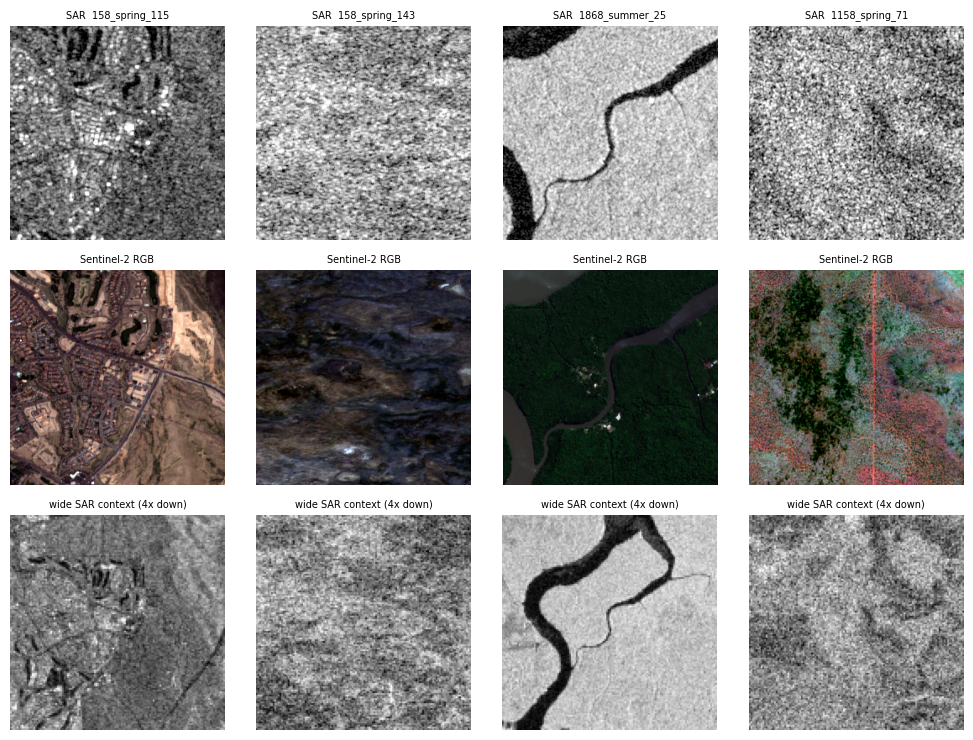

posterior-mean cache needs 18.8 GB (+18.8 GB temporarily for 'oof') | free disk now 47 GB


In [15]:
prepare_data(cfg, SOURCES)                 # idempotent: local disk -> store -> stream-ingest
rep = data_report(cfg)                     # counts, leakage assertion (raises on shared scenes), sample figure
S_, N_, _ = load_items(cfg.work)
need_gb = N_ * S_ * S_ * 3 / 1e9 * (1 + (1 if RUN["oof"] else 0))
print(f"posterior-mean cache needs {N_ * S_ * S_ * 3 / 1e9:.1f} GB (+{N_ * S_ * S_ * 3 / 1e9:.1f} GB temporarily for 'oof') | free disk now {shutil.disk_usage('/').free / 1e9:.0f} GB")
if shutil.disk_usage("/").free / 1e9 < need_gb + 3:
    print("!! not enough free disk for the posterior-mean caches -> set RUN['oof']=False or lower max_pairs")

**Check before training:** `leakage audit: PASSED`; ≥ 8 test scenes for usable CIs (raise `scene_frac` otherwise); the sample figure shows SAR / RGB / a smooth wide-context map; ~99 % of patches should report a recovered neighbour on the real data.

### 3b · The fixed evaluation set and the train-mean-colour floor
Every model is scored on the **same** `EVAL_N` test patches (random, fixed seed). FID uses the same real images and the same number of generated images for all models.

In [16]:
SPLIT = load_split(cfg.work)
EVAL_IDX = split_indices(cfg, "test", EVAL_N)
MEAN_COLOUR = train_mean_colour(cfg.work, np.array(SPLIT["idx"]["train"]))
json.dump(dict(eval_idx=[int(i) for i in EVAL_IDX], mean_colour=[float(x) for x in MEAN_COLOUR]), open(f"{cfg.work}/eval/eval_set.json", "w"))
print(f"eval set: {len(EVAL_IDX)} test patches from {len(set(PairData(cfg.work, EVAL_IDX, with_ctx=False).scene[EVAL_IDX]))} scenes | train-mean colour {np.round(MEAN_COLOUR, 1)}")

pidx = make_split_patch(cfg.work, cfg.split_fracs, cfg.seed)            # random per-PATCH split (leaky by construction): audit + E7 only
Q_PATCH = np.sort(np.random.RandomState(0).choice(pidx["test"], min(len(EVAL_IDX), len(pidx["test"])), replace=False))

def eval_model(name, ename=None, K=None, lams=None, seeds=None):
    """evaluate one registry model on EVAL_IDX with caching; relabels lambda variants"""
    ename = ename or name
    def make():
        m = load_model(cfg, name, K=K, const_colour=MEAN_COLOUR, lams=lams)
        if m is None: return None
        meta = dict(label=m["label"], group=m["group"], params_m=round(m["params_m"], 1), nfe=m["nfe"], steps=int(m["steps"]), ckpt=m["ckpt"])
        return dict(fn=m["fn"], idx=EVAL_IDX, bs=BS, seeds=(seeds or EVAL_SEEDS) if m["stochastic"] else (0,),
                    with_pm=m["with_pm"], with_ctx=m["with_ctx"], meta=meta)
    res = run_eval(cfg, ename, make)
    for v, (df, s) in res.items():
        if "@lam" in v:
            s["label"] = f"{s.get('label', name)}, $\\lambda$={v.split('@lam')[1]}"
        if ename != name and K is not None:
            s["label"] = f"{s.get('label', name)}, K={K}"
    RES.update(res)
    torch.cuda.empty_cache() if torch.cuda.is_available() else None
    return res

eval set: 4096 test patches from 11 scenes | train-mean colour [96.4 95.1 91.3]
[01:09:55] per-patch split: train=76519, val=9564, test=9566


### 3c · E1 — protocol audit: how much of a *per-patch* benchmark is solvable without SAR?
`overlap_lookup` pastes the optical pixels of **training** patches onto the footprint of a test patch (found from the 50 % overlaps). It uses **no SAR and no training**.
Under a random per-patch split it covers most test pixels with exact copies; under the scene-disjoint split coverage is exactly 0 (asserted) and it degrades to the train-mean colour.

In [17]:
if RUN["audit"]:
    gcomp, gpos = scene_positions(cfg.work)
    def mk_patch():
        col = train_mean_colour(cfg.work, np.array(pidx["train"]))
        arr, cov = overlap_lookup(cfg.work, pidx["train"], Q_PATCH, gcomp, gpos, col)
        return dict(fn=pred_lookup(arr, Q_PATCH), idx=Q_PATCH, bs=BS, with_ctx=False,
                    meta=dict(label="Overlap lookup, per-patch split (no SAR, no training)", group="audit", coverage=float(cov), params_m=0.0, nfe=0))
    def mk_scene():
        arr, cov = overlap_lookup(cfg.work, SPLIT["idx"]["train"], EVAL_IDX, gcomp, gpos, MEAN_COLOUR)
        assert cov == 0.0, "scene-disjoint split has overlapping training pixels?!"
        return dict(fn=pred_lookup(arr, EVAL_IDX), idx=EVAL_IDX, bs=BS, with_ctx=False,
                    meta=dict(label="Overlap lookup, scene-disjoint (= train-mean colour)", group="audit", coverage=float(cov), params_m=0.0, nfe=0))
    RES.update(run_eval(cfg, "LOOKUP_patch", mk_patch)); RES.update(run_eval(cfg, "LOOKUP_scene", mk_scene))
    for k in ("LOOKUP_patch", "LOOKUP_scene"):
        s = RES[k][1]; print(f"{s['label']:70s} exact-copy coverage {100 * s['coverage']:5.1f}% | PSNR(mean per image, 100 dB cap for exact) {s['psnr']:.2f} | pooled PSNR {s['psnr_pooled']:.2f} | SSIM {s['ssim']:.3f} | FID {s.get('fid', float('nan')):.1f}")
    print("-> a per-patch protocol lets a model with NO SAR input recover that share of the test pixels exactly; PSNR numbers under it are not evidence of translation skill.")

manifest_LOOKUP_patch.json:   0%|          | 0.00/16.0 [00:00<?, ?B/s]

LOOKUP_patch.csv:   0%|          | 0.00/330k [00:00<?, ?B/s]

LOOKUP_patch.json:   0%|          | 0.00/1.27k [00:00<?, ?B/s]

[01:10:09]   eval[LOOKUP_patch]: loaded cached results (1 variant(s))


manifest_LOOKUP_scene.json:   0%|          | 0.00/16.0 [00:00<?, ?B/s]

LOOKUP_scene.csv:   0%|          | 0.00/736k [00:00<?, ?B/s]

LOOKUP_scene.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

[01:10:09]   eval[LOOKUP_scene]: loaded cached results (1 variant(s))
Overlap lookup, per-patch split (no SAR, no training)                  exact-copy coverage  98.0% | PSNR(mean per image, 100 dB cap for exact) 94.44 | pooled PSNR 32.24 | SSIM 0.986 | FID 1.6
Overlap lookup, scene-disjoint (= train-mean colour)                   exact-copy coverage   0.0% | PSNR(mean per image, 100 dB cap for exact) 13.10 | pooled PSNR 12.22 | SSIM 0.289 | FID 488.6
-> a per-patch protocol lets a model with NO SAR input recover that share of the test pixels exactly; PSNR numbers under it are not evidence of translation skill.


## 4 · Benchmark (≈ 3 min) → plan → budget gate
Times the *real* training step of every model family on random tensors (no dataset needed), prints peak VRAM, then projects hours and CU for **your** `RUN`/`STEPS`. Stops if above `MAX_CU`.

In [ ]:
assert SMOKE or torch.cuda.is_available(), "No GPU: Runtime > Change runtime type > A100, then re-run sections 0-3 (data is re-fetched / restored)."
nb = 2 if SMOKE else 15
import gc, sys
sys.last_traceback = None                      # the earlier OOM keeps its frames (and GPU memory) alive until this is cleared
def _free():
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
def _bench(f):
    _free(); s = bench_family(cfg, f, 1000, n=nb, cu_per_hour=CU_PER_HOUR); _free(); return s
FAM = {f: _bench(f) for f in ("A", "B", "P2P", "CYC", "ddpm", "bbdm", "resshift")}
items = []
if RUN["A"]:     items.append(("A_main", "A", STEPS["A"]))
if RUN["B"]:     items.append(("B_main (PMRF)", "B", STEPS["B"]))
if RUN["base"]:  items += [("R_l1", "A", STEPS["R"]), ("P2P", "P2P", STEPS["P2P"]), ("CYC", "CYC", STEPS["CYC"])] + \
                          [(n, k, STEPS["DIFF"]) for n, k in (("DDPM", "ddpm"), ("BBDM", "bbdm"), ("RSHIFT", "resshift"))]
if RUN["ablA"]:  items += [(n, "A", STEPS["ABL"]) for n in ("A_ref", "A_noctx", "A_nometa", "A_plain", "A_l1ssim")]
if RUN["ctlB"]:  items += [(n, "B", STEPS["CTL"]) for n in ("B_ref", "B_pmrf", "B_noise")]
if RUN["oof"]:   items += [("A_fold0", "A", STEPS["OOF_A"]), ("A_fold1", "A", STEPS["OOF_A"]), ("B_oof", "B", STEPS["CTL"])]
if RUN["sigma"]: items += [(n, "B", STEPS["CTL"]) for n in ("B_sig005", "B_sig020")]
if RUN["proto"]: items.append(("A_patch", "A", STEPS["PATCH"]))
PLAN = pd.DataFrame([dict(run=n, family=f, steps=s, hours=s * FAM[f] / 3600) for n, f, s in items])
PLAN["CU"] = PLAN.hours * CU_PER_HOUR
overhead_h = 0.3 * (1 + int(RUN["oof"])) + (0.5 if SMOKE else 3.0)       # posterior-mean caches + evaluation (estimate)
print(PLAN.round(2).to_string(index=False))
tot_h = PLAN.hours.sum() + overhead_h
print(f"\nTOTAL  {tot_h:.1f} h = {tot_h * CU_PER_HOUR:.0f} CU   (training {PLAN.hours.sum():.1f} h + ~{overhead_h:.1f} h caching/evaluation estimate)   | MAX_CU = {MAX_CU}")
if tot_h * CU_PER_HOUR > MAX_CU and not FORCE_BUDGET:
    raise RuntimeError(f"plan = {tot_h * CU_PER_HOUR:.0f} CU > MAX_CU={MAX_CU}. Lower STEPS / switch RUN flags off (see the table), or set FORCE_BUDGET=True.")
print("budget OK. Peak VRAM above must be < ~36 GB; otherwise lower cfg.bsA / bsB / bsD (keep lr).")

[20:50:53] bench[A] 53.5M params | 0.298s/step -> 3.36 it/s | peak VRAM 18.7 GB | 60000 steps = 5.0 h = 27 CU @ 5.4 CU/h
[20:51:22] bench[B] 92.1M params | 0.398s/step -> 2.51 it/s | peak VRAM 24.9 GB | 80000 steps = 8.8 h = 48 CU @ 5.4 CU/h
[20:51:41] bench[P2P] 19.9M params | 0.134s/step (7.44 it/s) | peak VRAM 13.5 GB | 1000 steps = 0.0 h = 0 CU @ 5.4 CU/h
[20:52:01] bench[CYC] 39.7M params | 0.167s/step (5.98 it/s) | peak VRAM 12.4 GB | 1000 steps = 0.0 h = 0 CU @ 5.4 CU/h
[20:52:11] bench[ddpm] 92.1M params | 0.396s/step (2.53 it/s) | peak VRAM 24.9 GB | 1000 steps = 0.1 h = 1 CU @ 5.4 CU/h
[20:52:19] bench[bbdm] 92.1M params | 0.396s/step (2.53 it/s) | peak VRAM 24.8 GB | 1000 steps = 0.1 h = 1 CU @ 5.4 CU/h
[20:52:27] bench[resshift] 92.1M params | 0.396s/step (2.53 it/s) | peak VRAM 24.8 GB | 1000 steps = 0.1 h = 1 CU @ 5.4 CU/h
          run   family  steps  hours    CU
       A_main        A  60000   4.97 26.82
B_main (PMRF)        B  80000   8.84 47.72
         R_l1        A

## 5 · E2 — Stage A: scene-context posterior-mean regressor (ours)
Pure MSE, EMA. Validation PSNR on a fixed validation subset (validation **scenes**) every `val_every` steps with a trend flag; `best.pt` = best validation PSNR. Resumable: **if the session dies, re-run the cell.**

In [ ]:
if RUN["A"]:
    run_train(train_stage_a, cfg, "A_main")                    # wide context + season ON

ckpt/A_main/last.pt: reconstructing file:   0%|          |  0.00B /  857MB            

ckpt/A_main/last.pt: downloading bytes:           |  0.00B            

[20:52:46] [A_main] RESUMED from step 35543
[20:52:47] [A_main] training step 35543 -> 60000  (bs=32, 53.5M params, device=cuda)
[20:53:05] [A_main] step 35600/60000 loss=0.1062 mse=0.1062 lr=7.66e-05 | 0.01h this session
[20:53:35] [A_main] step 35700/60000 loss=0.1052 mse=0.1052 lr=7.61e-05 | 0.01h this session
[20:54:05] [A_main] step 35800/60000 loss=0.1058 mse=0.1058 lr=7.56e-05 | 0.02h this session
[20:54:35] [A_main] step 35900/60000 loss=0.1039 mse=0.1039 lr=7.50e-05 | 0.03h this session
[20:55:06] [A_main] step 36000/60000 loss=0.1056 mse=0.1056 lr=7.45e-05 | 0.04h this session
[20:55:36] [A_main] step 36100/60000 loss=0.1056 mse=0.1056 lr=7.40e-05 | 0.05h this session
[20:56:06] [A_main] step 36200/60000 loss=0.1050 mse=0.1050 lr=7.35e-05 | 0.06h this session
[20:56:37] [A_main] step 36300/60000 loss=0.1040 mse=0.1040 lr=7.30e-05 | 0.06h this session
[20:57:07] [A_main] step 36400/60000 loss=0.1045 mse=0.1045 lr=7.25e-05 | 0.07h this session
[20:57:37] [A_main] step 36500/600

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ..._work/ckpt/A_main/last.pt:   0%|          |  558kB /  857MB            

... (13 outputs left out)

  ..._work/ckpt/A_main/last.pt:   0%|          |  558kB /  214MB            

  ..._work/ckpt/A_main/last.pt:   0%|          |  558kB /  214MB            

Validating                    :           |   0%            

Validating                    :           |   0%            

In [ ]:
if RUN["A"]:
    ck = torch.load(f"{cfg.work}/ckpt/A_main/last.pt", map_location="cpu", weights_only=False)
    H = pd.DataFrame(ck["hist"]); print(H.tail(8).to_string(index=False)); print("trend:", trend_report(ck["hist"]), "| train hours:", round(ck.get("train_s", 0) / 3600, 2))
    diag, per_scene = diagnose_A(cfg, "A_main", tag="best" if os.path.exists(f"{cfg.work}/ckpt/A_main/best.pt") else "last")

     psnr  step
12.738609 25000
12.706617 30000
12.683592 35000
12.702716 40000
12.656233 45000
12.620919 50000
12.601962 55000
12.574690 60000
trend: FLAT (no new best in the last 3 evals; best 12.938) | train hours: 2.06
[22:57:28] diagnose[A_main/last @ step 60000]
[22:57:28]    val                             12.529 dB
[22:57:28]    train_seen_scenes               17.400 dB
[22:57:28]    constant_mean_colour            12.338 dB
[22:57:28]    val_with_oracle_colour_shift    17.294 dB
[22:57:28]    -> generalisation gap (train - val): +4.87 dB | gain available from a perfect global colour shift: +4.77 dB | model vs constant colour: +0.19 dB
[22:57:28]    per-scene val PSNR (10 scenes): min 10.32  max 15.17  spread 4.85 dB


*Diagnostic reading:* a large train−val gap plus a large “perfect global colour shift” gain means the plateau is **scene-level colour** (a generalisation limit), not an optimisation problem — more steps will not fix it; more/different scenes or a better prior will.

## 6 · E3 — Stage B: PMRF rectified flow (ours)
`Z₀ = pm + σ_s·ε`, input `[Z_t, pm, SAR]`, x-prediction with the velocity-equivalent weight; Euler sampling lands exactly on the predicted image, so `K=1` is valid. The cache uses **`best.pt` of A_main** (chosen on validation scenes).

In [ ]:
if RUN["A"] or RUN["B"]:
    cache_pm(cfg, "A_main", tag="best")                    # one pass over all patches (~10 min on an A100)
if RUN["B"]:
    run_train(train_stage_b, cfg, "B_main", mode="pmrf_y")

[22:57:29]   (store.pull ckpt/A_main/best.pt: RemoteEntryNotFoundError: 404 Client Error. (Request ID: Root=1-6ac81fd8-500b87360e39641e3b10573d;922a4ba4-8e4b-4772-926a-1f3f4b6a83ae)

Entry Not)
[22:57:29]   (A_main/best.pt not found -> using last.pt)
[22:57:47]   cache_pm 3200/95649 (18s)
[22:58:01]   cache_pm 6400/95649 (32s)
[22:58:15]   cache_pm 9600/95649 (46s)
[22:58:29]   cache_pm 12800/95649 (60s)
[22:58:43]   cache_pm 16000/95649 (74s)
[22:58:57]   cache_pm 19200/95649 (88s)
[22:59:11]   cache_pm 22400/95649 (102s)
[22:59:25]   cache_pm 25600/95649 (116s)
[22:59:39]   cache_pm 28800/95649 (130s)
[22:59:53]   cache_pm 32000/95649 (144s)
[23:00:07]   cache_pm 35200/95649 (158s)
[23:00:21]   cache_pm 38400/95649 (172s)
[23:00:35]   cache_pm 41600/95649 (186s)
[23:00:49]   cache_pm 44800/95649 (200s)
[23:01:03]   cache_pm 48000/95649 (214s)
[23:01:17]   cache_pm 51200/95649 (228s)
[23:01:31]   cache_pm 54400/95649 (242s)
[23:01:45]   cache_pm 57600/95649 (256s)
[23:01:59]   cache_p

ckpt/B_main/last.pt: reconstructing file:   0%|          |  0.00B / 1.47GB            

ckpt/B_main/last.pt: downloading bytes:           |  0.00B            

[23:04:49] [B_main] RESUMED from step 37288
[23:04:49] [B_main] training step 37288 -> 80000  (bs=32, 92.1M params, device=cuda)
[23:04:55] [B_main] step 37300/80000 loss=0.0121 mse=0.0045 lr=5.79e-05 | 0.00h this session
[23:05:35] [B_main] step 37400/80000 loss=0.0120 mse=0.0047 lr=5.77e-05 | 0.01h this session
[23:06:16] [B_main] step 37500/80000 loss=0.0126 mse=0.0051 lr=5.75e-05 | 0.02h this session
[23:06:56] [B_main] step 37600/80000 loss=0.0123 mse=0.0050 lr=5.73e-05 | 0.04h this session
[23:07:36] [B_main] step 37700/80000 loss=0.0123 mse=0.0052 lr=5.71e-05 | 0.05h this session
[23:08:17] [B_main] step 37800/80000 loss=0.0123 mse=0.0052 lr=5.69e-05 | 0.06h this session
[23:08:57] [B_main] step 37900/80000 loss=0.0119 mse=0.0048 lr=5.67e-05 | 0.07h this session
[23:09:38] [B_main] step 38000/80000 loss=0.0126 mse=0.0052 lr=5.65e-05 | 0.08h this session
[23:10:18] [B_main] step 38100/80000 loss=0.0124 mse=0.0050 lr=5.63e-05 | 0.09h this session
[23:10:58] [B_main] step 38200/800

## 7 · E4 — baselines, re-trained on the same scenes in the same harness
| Baseline | What it is | Network |
|---|---|---|
| U-Net (L1) | plain regression, SAR only | stage-A backbone, no context/season |
| Pix2Pix | paired cGAN (L1 + LSGAN, PatchGAN) | U-Net generator |
| CycleGAN | unpaired cGAN, cycle-consistency | two U-Net generators |
| DDPM | SAR-conditioned DDPM (v-pred, cosine, DDIM-25) — the family used by Bai & Xu | stage-B backbone |
| BBDM-style | Brownian-bridge diffusion SAR→optical (exact bridge posterior), 25 steps | stage-B backbone |
| ResShift-style | residual-shifting diffusion in pixel space, T=15 | stage-B backbone |

They are **our compact re-implementations of the method families** (say so in the paper), see only the SAR patch, and use the same optimiser/EMA/augmentation. A stronger claim needs the authors' code (see §15).

In [ ]:
if RUN["base"]:
    run_train(train_stage_a, cfg, "R_l1", use_ctx=False, use_meta=False, loss="l1", steps=STEPS["R"])
    run_train(train_pix2pix, cfg, "P2P", steps=STEPS["P2P"])
    run_train(train_cyclegan, cfg, "CYC", steps=STEPS["CYC"])

In [ ]:
if RUN["base"]:
    for nm, kd in (("DDPM", "ddpm"), ("BBDM", "bbdm"), ("RSHIFT", "resshift")):
        run_train(train_diffusion, cfg, nm, kd, steps=STEPS["DIFF"])

## 8 · E5 — Stage-A ablations (equal short budget; which ingredient matters?)
`A_ref` (full) vs `A_noctx` (no wide context) vs `A_nometa` (no season) vs `A_plain` (neither) vs `A_l1ssim` (the old regressor-style loss).

In [ ]:
if RUN["ablA"]:
    run_train(train_stage_a, cfg, "A_ref",    steps=STEPS["ABL"])
    run_train(train_stage_a, cfg, "A_noctx",  use_ctx=False, steps=STEPS["ABL"])
    run_train(train_stage_a, cfg, "A_nometa", use_meta=False, steps=STEPS["ABL"])
    run_train(train_stage_a, cfg, "A_plain",  use_ctx=False, use_meta=False, steps=STEPS["ABL"])
    run_train(train_stage_a, cfg, "A_l1ssim", loss="l1ssim", steps=STEPS["ABL"])

## 9 · E6 — Stage-B controls
* `B_ref` full model, short budget (reference for the controls) · `B_pmrf` pure PMRF (flow sees only `Z_t`, the original paper's setting) · `B_noise` **flow from noise conditioned on SAR = a posterior sampler**: PMRF's claim is that it beats this on PSNR at similar FID.
* `B_oof` trains the flow on **out-of-fold** posterior means. The in-sample posterior means of the training scenes are better than those of unseen scenes (Stage A overfits), so the flow learns to over-trust them; folds fix that mismatch (2 extra stage-A models on half the scenes each).
* `sigma` (optional): σ_s ∈ {0.05, 0.20}.

In [ ]:
if RUN["ctlB"]:
    run_train(train_stage_b, cfg, "B_ref",   mode="pmrf_y",    steps=STEPS["CTL"])
    run_train(train_stage_b, cfg, "B_pmrf",  mode="pmrf",      steps=STEPS["CTL"])
    run_train(train_stage_b, cfg, "B_noise", mode="noise_sar", steps=STEPS["CTL"])
if RUN["sigma"]:
    run_train(train_stage_b, cfg, "B_sig005", mode="pmrf_y", steps=STEPS["CTL"], sigma_s=0.05)
    run_train(train_stage_b, cfg, "B_sig020", mode="pmrf_y", steps=STEPS["CTL"], sigma_s=0.20)

In [ ]:
if RUN["oof"]:
    train_oof_folds(cfg, 2, steps=STEPS["OOF_A"])          # each call is resumable; finished folds are skipped
    run_train(train_stage_b, cfg, "B_oof", mode="pmrf_y", steps=STEPS["CTL"], pm_name="pm_oof")
    p = f"{cfg.work}/data/pm_oof.u8"
    if os.path.exists(p): os.remove(p); print("deleted pm_oof.u8 (only needed for training; test posterior means are identical)")

## 10 · E7 — protocol inflation: Stage A trained **and** tested under a per-patch random split
Same architecture, same steps as `A_ref`, but the split is per-patch (the protocol most SEN1-2 papers use). The difference to `A_ref` (scene-disjoint) is the inflation caused by overlap leakage on this data.

In [ ]:
if RUN["proto"]:
    if not os.path.exists(f"{cfg.work}/data/split_patch.json"): make_split_patch(cfg.work, cfg.split_fracs, cfg.seed)
    cfg_patch = Cfg(dict(cfg)); cfg_patch.split_file = "split_patch.json"
    run_train(train_stage_a, cfg_patch, "A_patch", steps=STEPS["PATCH"])

## 11 · E8 — unified evaluation on the fixed test subset
One harness for every model (`evalm.py`). Per image: PSNR/SSIM on uint8 RGB (checked against scikit-image), SAM, ERGAS, CC, RMSE, MAE, LPIPS-Alex/VGG; set-level FID; scene-level cluster-bootstrap 95 % CIs;
stochastic models average over `EVAL_SEEDS` and report sample *diversity*. Results are cached on disk — re-running only evaluates what is new. `B_main@lamX` = `(1−X)·pm + X·flow`.

In [ ]:
t0 = time.time()
for n in available(cfg):
    if n == "B_main": continue
    eval_model(n)
if "B_main" in available(cfg):
    eval_model("B_main")                                   # lambda sweep from ONE sampling pass (K=10)
    for K in ((1, 2) if SMOKE else (1, 2, 5, 20)):          # sampling-step sweep, pure PMRF output
        eval_model("B_main", ename=f"B_main_K{K}", K=K, lams=(1.0,))
print(f"evaluation done in {(time.time() - t0) / 60:.1f} min; {len(RES)} result rows")

In [ ]:
if ckpt_exists(cfg, "A_patch", "last"):
    cfg_patch = Cfg(dict(cfg)); cfg_patch.split_file = "split_patch.json"
    def mk_proto():
        m, st = load_A(cfg_patch, "A_patch", True, True, tag="best" if os.path.exists(f"{cfg.work}/ckpt/A_patch/best.pt") else "last")
        meta = dict(label="Stage A, per-patch split (leaky)", group="audit", params_m=round(count_params(m), 1), nfe=1, steps=int(st))
        return dict(fn=pred_A(m, True, True), idx=Q_PATCH, bs=BS, with_ctx=True, meta=meta)
    RES.update(run_eval(cfg, "PROTO_A_patch", mk_proto))

In [ ]:
ORDER = ["Const", "R_l1", "P2P", "CYC", "DDPM", "BBDM", "RSHIFT", "A_main", "B_main@lam1"]
T_main = summary_table({k: RES[k] for k in ORDER if k in RES})
print("MAIN TABLE (scene-disjoint test subset)"); print(T_main.to_string(index=False))
ABL = [k for k in RES if RES[k][1].get("group") in ("ablation", "control")]
print("\nABLATIONS / CONTROLS"); print(summary_table({k: RES[k] for k in ABL}).to_string(index=False))
print("\nLAMBDA SWEEP (distortion-perception knob)"); print(summary_table({k: RES[k] for k in RES if k.startswith("B_main@lam")}).to_string(index=False))
print("\nSAMPLING STEPS"); print(summary_table({k: RES[k] for k in RES if k.startswith("B_main_K")}).to_string(index=False))
print("\nPROTOCOL AUDIT"); print(summary_table({k: RES[k] for k in RES if RES[k][1].get("group") == "audit"}).to_string(index=False))
if "A_ref" in RES and "PROTO_A_patch" in RES:
    print(f"\nprotocol inflation (same arch, same steps): per-patch {RES['PROTO_A_patch'][1]['psnr']:.2f} dB vs scene-disjoint {RES['A_ref'][1]['psnr']:.2f} dB  ->  {RES['PROTO_A_patch'][1]['psnr'] - RES['A_ref'][1]['psnr']:+.2f} dB")
print("\nPER SEASON"); print(season_table({k: RES[k] for k in ORDER if k in RES}).to_string(index=False))

## 12 · Paired tests and the automatic claim check
Paired differences use the *same* patches; CIs come from a **scene-level** cluster bootstrap and a Wilcoxon test on scene means. “SUPPORTED” = CI excludes zero in the claimed direction. FID has no per-image form, so FID differences are reported as plain differences (use several seeds / bootstrap before claiming small FID gaps).

In [ ]:
PAIRS = [("B_main@lam1", "A_main"), ("B_main@lam1", "DDPM"), ("B_main@lam1", "BBDM"), ("B_main@lam1", "RSHIFT"), ("B_main@lam1", "P2P"),
         ("B_main@lam1", "CYC"), ("B_main@lam1", "R_l1"), ("A_main", "DDPM"), ("A_main", "BBDM"), ("A_main", "RSHIFT"), ("A_main", "P2P"), ("A_main", "R_l1"),
         ("A_ref", "A_noctx"), ("A_ref", "A_nometa"), ("A_ref", "A_plain"), ("A_ref", "A_l1ssim"),
         ("B_ref", "B_noise"), ("B_ref", "B_pmrf"), ("B_oof", "B_ref"), ("B_sig005", "B_ref"), ("B_sig020", "B_ref"), ("B_main@lam1", "B_main@lam0")]
HIGHER = {"psnr": True, "ssim": True, "cc": True, "lpips_alex": False, "lpips_vgg": False, "sam": False, "ergas": False}
rows = []
for a, b in PAIRS:
    if a in RES and b in RES:
        for c in HIGHER:
            if c in RES[a][0] and c in RES[b][0]:
                d = paired_delta(RES[a][0], RES[b][0], c)
                good = (d["lo"] > 0) if HIGHER[c] else (d["hi"] < 0)
                bad = (d["hi"] < 0) if HIGHER[c] else (d["lo"] > 0)
                rows.append(dict(a=a, b=b, metric=c, **d, verdict=("a BETTER" if good else "a WORSE" if bad else "n.s.")))
DELTAS = pd.DataFrame(rows)
if len(DELTAS):
    print(DELTAS.round(4).to_string(index=False))
    DELTAS.to_csv(f"{cfg.work}/eval/deltas.csv", index=False)
    print("\nCLAIM CHECK (a vs b)")
    for a, b in PAIRS:
        sub = DELTAS[(DELTAS.a == a) & (DELTAS.b == b)]
        if len(sub):
            print(f"  {a:14s} vs {b:12s}: " + " | ".join(f"{r.metric} {r.delta:+.3f} [{r.verdict}]" for r in sub.itertuples() if r.metric in ("psnr", "ssim", "lpips_alex")))

## 13 · Figures — SAR │ ground truth │ **every model**
Same test patches in every column; stochastic models show one draw (seed 0); the number in each tile is that tile's PSNR. Saved as PNG **and** PDF in `work/fig/`.

In [ ]:
from IPython.display import Image as _Im, display
GRID = [n for n in ("R_l1", "P2P", "CYC", "DDPM", "BBDM", "RSHIFT", "A_main", "B_main", "B_noise") if n in available(cfg)]
PRED = {}
for n in GRID:
    m = load_model(cfg, n, const_colour=MEAN_COLOUR)
    PRED[m["label"]] = m["fn"]
have_pm = os.path.exists(f"{cfg.work}/data/pm.u8")
g1 = sample_grid(cfg, PRED, idx=pick_idx(cfg, "test", 6 if not SMOKE else 3, seed=0), with_pm=have_pm, with_ctx=True, fname="grid_random.png")
g2 = sample_grid(cfg, PRED, idx=pick_idx(cfg, "test", 1, per_season=True, seed=1), with_pm=have_pm, with_ctx=True, fname="grid_per_season.png")
display(_Im(g1)); display(_Im(g2))

In [ ]:
fig = dp_plot({k: v for k, v in RES.items() if v[1].get("group") in ("floor", "baseline", "ours") or k.startswith("B_main@lam")}, cfg=cfg)
display(_Im(f"{cfg.work}/fig/dp_curve.png"))
# training curves of every run (validation PSNR vs step)
import matplotlib.pyplot as plt
TS = training_summary(cfg)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for nm, t in TS.items():
    h = t["val_history"]
    if len(h) > 1:
        (ax[0] if nm.startswith(("A_", "R_", "P2P", "CYC")) else ax[1]).plot([x for x, _ in h], [y for _, y in h], marker=".", label=nm)
for a_, ti in zip(ax, ("stage-A family / GANs (val PSNR, EMA)", "stage-B family / diffusion (val PSNR, K=val_K)")):
    a_.set_title(ti, fontsize=9); a_.set_xlabel("step"); a_.grid(alpha=.3); a_.legend(fontsize=6)
plt.tight_layout(); fig.savefig(f"{cfg.work}/fig/training_curves.png", dpi=150); fig.savefig(f"{cfg.work}/fig/training_curves.pdf"); plt.show()

## 14 · Paper bundle — LaTeX tables, CSVs, configs, split lists, environment, methods paragraph

In [ ]:
order = [k for k in ["Const", "R_l1", "P2P", "CYC", "DDPM", "BBDM", "RSHIFT", "A_main"] if k in RES] + \
        sorted(k for k in RES if k.startswith("B_main@lam")) + sorted(k for k in RES if k.startswith("B_main_K")) + \
        [k for k in RES if RES[k][1].get("group") in ("ablation", "control", "audit")]
extra_info = dict(eval_n=len(EVAL_IDX), eval_seeds=list(EVAL_SEEDS), steps=STEPS, run=RUN,
                  lookup_coverage={k: RES[k][1].get("coverage") for k in ("LOOKUP_patch", "LOOKUP_scene") if k in RES})
out_dir, zip_path = write_bundle(cfg, RES, deltas=(DELTAS if len(DELTAS) else None), extra=extra_info, order=order)
for f in sorted(os.listdir(out_dir)): print(f"  {f}")
print("\n" + open(f"{out_dir}/results_main.tex").read())
for f in sorted(os.listdir(f"{cfg.work}/fig")): shutil.copy(f"{cfg.work}/fig/{f}", out_dir)
zip_path = shutil.make_archive(out_dir, "zip", out_dir)
if IN_COLAB:
    os.makedirs(DRIVE_DIR, exist_ok=True); shutil.copy(zip_path, DRIVE_DIR); print("copied to Drive:", f"{DRIVE_DIR}/{os.path.basename(zip_path)}")
    from google.colab import files; files.download(zip_path)
print("bundle:", zip_path)

## 15 · How to read the result, what you can claim, and further experiments
**Reading the tables**
* `Const` is the floor; `LOOKUP_patch` vs `LOOKUP_scene` quantifies leakage; `A_patch` vs `A_ref` is the inflation of a trained model. Publish these three lines — they explain why published SEN1-2 numbers cannot be compared with scene-disjoint ones.
* **PSNR/SSIM/CC/SAM/ERGAS** measure distortion; **LPIPS/FID** perception. A posterior mean (A) wins distortion; a sampler wins perception; PMRF (`B_main@lam1`) should sit between them and beat the posterior-sampler control (`B_noise`) on PSNR at similar FID — the claim to test with `B_ref` vs `B_noise` (§12).
* `A_ref` vs `A_noctx`/`A_nometa`/`A_plain` tells you whether the wide context and season help at all. The earlier oracle study predicts a small effect; report it either way.
* Claim only what the automatic check marks SUPPORTED. If PMRF does not beat the diffusion baselines on FID/LPIPS, the honest contribution is the *benchmark and the audit*.

**What this notebook deliberately does not do**
* It does not copy numbers from other papers into measured tables (Table “lit” in the bundle is separate and flagged).
* Lat/lon and DEM are not in the SEN1-2 PNG release, so they are not used.

**Further experiments worth running (not included because they need code/weights that cannot be verified offline)**
1. **TerraMind-initialised Stage A** (open-weights EO foundation model, S1→S2 zero-shot): the strongest candidate for a real PSNR gain on unseen scenes; add as a registry entry once the weights load in your runtime.
2. **Authors' code for E3Diff / C-DiffSET / BBDM / ResShift** under the *same split files* (`split_scenes.json` in the bundle) — upgrades “-style” baselines to “official”.
3. **Train on all 258 scenes** (`scene_frac=1.0`, needs ≈ 150 GB) — the strongest lever against the scene-level overfit seen in the diagnostic.
4. **KID / DINOv2-based FD** to complement FID (FID is biased at 4096 images; use `EVAL_N=None` for the final numbers).
5. **Cross-dataset test** of the already-trained models on SEN12MS (zero-shot) to show the scene-disjoint ranking transfers.

In [19]:
# ============================ PASTE AS CELL 1 ============================
# CELL 1 — dependencies (no restart needed)
!pip -q install "diffusers>=0.32" transformers accelerate safetensors huggingface_hub lpips torchmetrics torch-fidelity kagglehub scikit-learn


In [21]:
# ============================ PASTE AS CELL 2 ============================
%%writefile /content/v3x.py
"""
v3x.py -- continue + extend the regressor v3 (SAR->optical, SD-1.5 UNet in a 16-ch adapted-VAE latent space).

  Exp 1  re-score v3 on the TRUE held-out split (the split the training scripts used)
  Exp 2  continue training v3 ("v3+"), paired gate on a fixed monitor set
  Exp 3  posterior-mean rectified flow in latent space, initialised from the regressor (PMRF-latent)
  Exp 4  full-val report: v3 / v3+ / flow (NFE 8,16) / blends -> tables, grid, PSNR-FID curve, bundle

Everything (data, split, VAE, UNet, conditioning, metrics) is copied from the user's own scripts so numbers stay comparable.
"""
import os, gc, json, math, time, copy, random, shutil, warnings
SMOKE = os.environ.get("V3X_SMOKE") == "1"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from diffusers import AutoencoderKL, UNet2DConditionModel
from diffusers.optimization import get_cosine_schedule_with_warmup
from safetensors.torch import save_file, load_file
warnings.filterwarnings("ignore")
torch.backends.cuda.matmul.allow_tf32 = True; torch.backends.cudnn.allow_tf32 = True
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")

HF_REPO = os.environ["HF_REPO_ID"]
SD_IDS = ["runwayml/stable-diffusion-v1-5", "stable-diffusion-v1-5/stable-diffusion-v1-5"]
DATA_WORK = "/tmp/v3x_fake_work" if SMOKE else "/content/pmflow_work"     # the benchmark notebook's cfg.work (memmaps in DATA_WORK/data)
TERRAIN_DEFAULT = "temperate"          # the official SEN1-2 data has no terrain label; v3's prompt was "a <season> satellite optical image of <terrain> terrain"
COND_MODE = "season_temperate"         # or "null" (decided by exp1_baseline)
_META = {}
WORK = "/tmp/v3x_work" if SMOKE else "/content/v3x"
IMG = 64 if SMOKE else 256
SEED, VAL_FRACTION = 42, 0.05
SEASONS = ("spring", "summer", "fall", "winter")
TERRAINS = ("tropical", "temperate", "arctic", "arid", "coastal", "urban")
SEASON_DESC = {"spring": "spring", "summer": "summer", "fall": "autumn", "winter": "winter"}
TOTAL_CH = 16
CU_PER_HOUR = 5.4            # A100 estimate; verify under "View resources"
HF_TOKEN = ""
T0 = time.time()
# published numbers as quoted in the paper (protocol of the original works may differ)
SOTA = {"DDPM (IGARSS)": dict(psnr=19.72, ssim=0.312, fid=116.9),
        "ACD-16 (Bai'24)": dict(psnr=20.57, ssim=0.323, fid=116.9)}


def log(*a): print(time.strftime("[%H:%M:%S]"), *a, flush=True)
def cu_used(): return (time.time() - T0) / 3600 * CU_PER_HOUR
def free_gpu():
    import sys
    sys.last_traceback = None; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()


# ============================================================================ hub
def init(hf_token="", data_work=None):
    global HF_TOKEN, DATA_WORK
    HF_TOKEN = hf_token
    if data_work: DATA_WORK = str(data_work)
    os.makedirs(WORK, exist_ok=True)
    d = json.load(open(f"{DATA_WORK}/data/items.json"))
    _META.update(S=int(d["S"]), N=int(d["N"]), season=np.array([int(it["season"]) for it in d["items"]], np.int64))
    log(f"data: {DATA_WORK}/data | N={_META['N']:,} patches | S={_META['S']}")
    global COND_MODE
    pj = f"{WORK}/exp1_baseline.json"
    if os.path.exists(pj): COND_MODE = json.load(open(pj)).get("cond_mode", COND_MODE); log(f"prompt convention restored from exp1: {COND_MODE}")
    log(f"WORK={WORK} | device={dev} | token={'set' if HF_TOKEN else 'NOT set (downloads ok, pushes skipped)'}")


def hf_dl(path):
    from huggingface_hub import hf_hub_download
    return hf_hub_download(HF_REPO, path, token=HF_TOKEN or None)


def hf_push(folder, path_in_repo):
    if not HF_TOKEN or SMOKE: log(f"  (push skipped: {path_in_repo})"); return False
    try:
        from huggingface_hub import HfApi
        HfApi().upload_folder(folder_path=folder, path_in_repo=path_in_repo, repo_id=HF_REPO, repo_type="model", token=HF_TOKEN)
        log(f"  pushed -> HF/{path_in_repo}"); return True
    except Exception as e:
        log(f"  push failed ({e}); files stay in {folder}"); return False


def sd_load(cls, sub):
    last = None
    for sid in SD_IDS:
        try: return cls.from_pretrained(sid, subfolder=sub)
        except Exception as e: last = e
    raise RuntimeError(f"could not load SD-1.5 '{sub}' from {SD_IDS}: {last}")


# ============================================================================ data (the memmaps of the benchmark notebook)
def get_split():
    """scene-disjoint split of the benchmark notebook (split.json). NOTE: v3 was trained on a per-patch random 95% of the Kaggle copy of
    these same scenes, so v3 has already seen ~95% of these patches once -> its numbers here are optimistic (see the caveat in the report)."""
    sp = json.load(open(f"{DATA_WORK}/data/split.json"))["idx"]
    return [int(i) for i in sp["train"]], [int(i) for i in sp["val"]], [int(i) for i in sp["test"]]


class PairDS(Dataset):
    """index -> {sar (3ch, [-1,1]), opt (3ch), season (str), terrain (str)}; the SAR band is replicated to 3 channels exactly like v3 saw it."""
    def __init__(self, idx, augment=False): self.idx, self.aug, self._m = list(idx), augment, None
    def __len__(self): return len(self.idx)
    def _open(self):
        S, N = _META["S"], _META["N"]; d = f"{DATA_WORK}/data"
        self._m = (np.memmap(f"{d}/sar.u8", np.uint8, "r", shape=(N, S, S)), np.memmap(f"{d}/rgb.u8", np.uint8, "r", shape=(N, S, S, 3)))
    def __getitem__(self, i):
        if self._m is None: self._open()
        k = int(self.idx[i])
        sar = torch.from_numpy(np.array(self._m[0][k])).float().div_(127.5).sub_(1).unsqueeze(0).repeat(3, 1, 1)
        opt = torch.from_numpy(np.array(self._m[1][k])).permute(2, 0, 1).float().div_(127.5).sub_(1)
        if sar.shape[-1] != IMG:
            sar = F.interpolate(sar[None], size=(IMG, IMG), mode="bilinear", align_corners=False)[0]
            opt = F.interpolate(opt[None], size=(IMG, IMG), mode="bilinear", align_corners=False)[0]
        if self.aug:
            if random.random() > .5: sar, opt = torch.flip(sar, [2]), torch.flip(opt, [2])
            if random.random() > .5: sar, opt = torch.flip(sar, [1]), torch.flip(opt, [1])
        return {"sar": sar, "opt": opt, "season": SEASONS[int(_META["season"][k])], "terrain": TERRAIN_DEFAULT}


def loader(pairs, bs, augment=False, shuffle=False, workers=None, drop_last=False):
    w = (0 if SMOKE else 6) if workers is None else workers
    return DataLoader(PairDS(pairs, augment), batch_size=bs, shuffle=shuffle, num_workers=w, pin_memory=not SMOKE,
                      drop_last=drop_last, persistent_workers=(w > 0 and shuffle))


# ============================================================================ models (identical to the training scripts)
class DetailEncoder(nn.Module):
    def __init__(s, ic=3, oc=12, nf=64):
        super().__init__()
        s.net = nn.Sequential(nn.Conv2d(ic, nf, 3, 2, 1), nn.GroupNorm(8, nf), nn.SiLU(),
                              nn.Conv2d(nf, nf * 2, 3, 2, 1), nn.GroupNorm(8, nf * 2), nn.SiLU(),
                              nn.Conv2d(nf * 2, nf * 4, 3, 2, 1), nn.GroupNorm(8, nf * 4), nn.SiLU(),
                              nn.Conv2d(nf * 4, nf * 4, 3, 1, 1), nn.GroupNorm(8, nf * 4), nn.SiLU(),
                              nn.Conv2d(nf * 4, oc, 3, 1, 1))
    def forward(s, x): return s.net(x)


class AdaptedVAE(nn.Module):
    def __init__(s, bv):
        super().__init__(); s.base_vae = bv; s.detail_enc = DetailEncoder()
        o = bv.decoder.conv_in
        bv.decoder.conv_in = nn.Conv2d(TOTAL_CH, o.out_channels, o.kernel_size, o.stride, o.padding, bias=(o.bias is not None))
    @torch.no_grad()
    def enc(s, x):
        z = s.base_vae.encode(x).latent_dist.mode()
        return torch.cat([s.base_vae.post_quant_conv(z), s.detail_enc(x)], 1)
    def dec_grad(s, l): return s.base_vae.decoder(l)
    @torch.no_grad()
    def dec(s, l): return s.base_vae.decoder(l)


def _base_vae():
    if SMOKE:
        return AutoencoderKL(in_channels=3, out_channels=3, down_block_types=("DownEncoderBlock2D",) * 4,
                             up_block_types=("UpDecoderBlock2D",) * 4, block_out_channels=(8, 8, 16, 16),
                             latent_channels=4, norm_num_groups=8, layers_per_block=1)
    return sd_load(AutoencoderKL, "vae")


def load_vae_for(reg_dir):
    """Encoder = adapted16_final (frozen, never changes). Decoder = the tuned decoder that belongs to this regressor."""
    v = AdaptedVAE(_base_vae())
    if not SMOKE:
        v.base_vae.load_state_dict(torch.load(hf_dl("adapted16_final/base_vae.pth"), map_location="cpu"))
        v.detail_enc.load_state_dict(torch.load(hf_dl("adapted16_final/detail_encoder.pth"), map_location="cpu"))
        p = hf_dl("regressor_v3_final/base_vae_tuned.pth") if reg_dir is None else f"{reg_dir}/base_vae_tuned.pth"
        v.base_vae.load_state_dict(torch.load(p, map_location="cpu"))
    return v.to(dev).float().eval().requires_grad_(False)


def build_unet(in_ch):
    if SMOKE:
        u = UNet2DConditionModel(sample_size=IMG // 8, in_channels=in_ch, out_channels=TOTAL_CH, block_out_channels=(32, 64),
                                 down_block_types=("CrossAttnDownBlock2D", "DownBlock2D"), up_block_types=("UpBlock2D", "CrossAttnUpBlock2D"),
                                 cross_attention_dim=768, layers_per_block=1, attention_head_dim=8, norm_num_groups=8)
        return u
    u = sd_load(UNet2DConditionModel, "unet")
    oi = u.conv_in; u.conv_in = nn.Conv2d(in_ch, oi.out_channels, oi.kernel_size, oi.stride, oi.padding)
    oo = u.conv_out; u.conv_out = nn.Conv2d(oo.in_channels, TOTAL_CH, oo.kernel_size, oo.stride, oo.padding)
    try: u.config.in_channels, u.config.out_channels = in_ch, TOTAL_CH
    except Exception: pass
    return u


def expand_conv_in(u, new_in):
    """keep the pretrained weights on the first channels, zero-init the new ones (flow net sees [x_t, y, z_hat])."""
    o = u.conv_in
    if o.in_channels == new_in: return u
    n = nn.Conv2d(new_in, o.out_channels, o.kernel_size, o.stride, o.padding)
    with torch.no_grad():
        n.weight.zero_(); n.weight[:, :o.in_channels] = o.weight; n.bias.copy_(o.bias)
    u.conv_in = n
    try: u.config.in_channels = new_in
    except Exception: pass
    return u


def load_reg(reg_dir=None):
    """regressor + its tuned decoder. reg_dir=None -> the original v3 on the Hub."""
    cfgp = hf_dl("regressor_v3_final/bridge_config.json") if (reg_dir is None and not SMOKE) else f"{reg_dir}/bridge_config.json"
    cfg = {"latent_scale": 1.0, "fixed_tb": 933, "final_psnr": 0, "final_ssim": 0} if SMOKE and reg_dir is None else json.load(open(cfgp))
    u = build_unet(2 * TOTAL_CH)
    if not SMOKE or reg_dir is not None:
        sp = hf_dl("regressor_v3_final/unet.safetensors") if reg_dir is None else f"{reg_dir}/unet.safetensors"
        u.load_state_dict(load_file(sp))
    u = u.to(dev).float().eval().requires_grad_(False)
    vae = load_vae_for(reg_dir)
    return u, vae, cfg


_EMB = None
def embeds():
    global _EMB
    if _EMB is not None: return _EMB
    cache = {}
    if SMOKE:
        g = torch.Generator().manual_seed(0)
        for s in SEASONS:
            for t in TERRAINS: cache[(s, t)] = torch.randn(77, 768, generator=g)
        cache["null"] = torch.zeros(77, 768)
    else:
        from transformers import CLIPTextModel, CLIPTokenizer
        tok = sd_load(CLIPTokenizer, "tokenizer"); txt = sd_load(CLIPTextModel, "text_encoder").to(dev).eval()
        @torch.no_grad()
        def emb(p):
            t = tok(p, padding="max_length", max_length=tok.model_max_length, truncation=True, return_tensors="pt").input_ids.to(dev)
            return txt(t)[0][0].cpu()
        for s in SEASONS:
            for t in TERRAINS: cache[(s, t)] = emb(f"a {SEASON_DESC[s]} satellite optical image of {t} terrain")
        cache["null"] = emb(""); del txt; free_gpu()
    _EMB = cache; return cache


def get_cond(ss, tt, drop=0.0):
    c = embeds(); null_all = COND_MODE == "null"
    return torch.stack([c["null"] if (null_all or (drop and random.random() < drop)) else c.get((s, t), c["null"]) for s, t in zip(ss, tt)]).to(dev)


def regress(u, y, cond, tb, amp=False):
    tbt = torch.full((y.shape[0],), int(tb), device=dev, dtype=torch.long)
    with torch.autocast(dev.type, dtype=torch.bfloat16, enabled=amp and dev.type == "cuda"):
        out = u(torch.cat([y, y], 1), tbt, encoder_hidden_states=cond).sample
    return out.float()


# ============================================================================ metrics (definitions identical to final_eval_full.py)
_LP = _SS = None
def _lp():
    global _LP
    if _LP is None:
        import lpips
        _LP = lpips.LPIPS(net="alex", pnet_rand=SMOKE, verbose=False).to(dev).eval()
    return _LP
def _ss():
    global _SS
    if _SS is None:
        from torchmetrics.image import StructuralSimilarityIndexMeasure
        _SS = StructuralSimilarityIndexMeasure(data_range=2.0, reduction="none").to(dev)
    return _SS

class _SmokeFID:
    """stand-in for the Inception FID when there is no network (smoke test only)."""
    def __init__(s): s.f = torch.nn.Conv2d(3, 16, 8, 8).to(dev); s.r, s.g = [], []
    def update(s, x, real):
        with torch.no_grad(): (s.r if real else s.g).append(s.f(x).mean((2, 3)).double().cpu())
    def compute(s):
        from scipy import linalg
        a, b = torch.cat(s.r).numpy(), torch.cat(s.g).numpy()
        m1, m2 = a.mean(0), b.mean(0); c1, c2 = np.cov(a.T), np.cov(b.T)
        cs = linalg.sqrtm(c1 @ c2).real
        return torch.tensor(float(((m1 - m2) ** 2).sum() + np.trace(c1 + c2 - 2 * cs)))

def new_fid():
    if SMOKE: return _SmokeFID()
    from torchmetrics.image.fid import FrechetInceptionDistance
    return FrechetInceptionDistance(feature=2048, normalize=True).to(dev)

def dn(t): return (t.clamp(-1, 1) + 1) / 2

def per_image_metrics(p, g):
    p, g = p.clamp(-1, 1), g
    mse = ((p - g) ** 2).flatten(1).mean(1)
    psnr = 10 * torch.log10(4.0 / mse.clamp_min(1e-12))
    ssim = _ss()(p, g)
    with torch.no_grad(): lp = _lp()(p, g).flatten()
    pp = ((p + 1) / 2).clamp(1e-4, 1).flatten(2).transpose(1, 2); gg = ((g + 1) / 2).clamp(1e-4, 1).flatten(2).transpose(1, 2)
    cs = ((pp * gg).sum(-1) / (pp.norm(dim=-1) * gg.norm(dim=-1) + 1e-8)).clamp(-1, 1)
    sam = torch.rad2deg(torch.acos(cs)).mean(1)
    e = 0
    for b in range(3):
        rm = torch.sqrt(((p[:, b] - g[:, b]) ** 2).flatten(1).mean(1))
        e = e + (rm / (((g[:, b] + 1) / 2).flatten(1).mean(1) + 1e-8)) ** 2
    ergas = 100 * torch.sqrt(e / 3)
    ccs = 0
    for b in range(3):
        x = p[:, b].flatten(1) - p[:, b].flatten(1).mean(1, keepdim=True); y = g[:, b].flatten(1) - g[:, b].flatten(1).mean(1, keepdim=True)
        ccs = ccs + (x * y).sum(1) / (x.norm(dim=1) * y.norm(dim=1) + 1e-8)
    return dict(psnr=psnr, ssim=ssim.flatten(), lpips=lp, sam=sam, ergas=ergas, cc=ccs / 3)


@torch.no_grad()
def evaluate_multi(fn, pairs, names, bs=8, fid=True, tag=""):
    """fn(y_sar_img_batch, cond, batch) -> {name: image in [-1,1]}.  One pass over `pairs`, all variants scored on the same images."""
    acc = {n: {k: [] for k in ("psnr", "ssim", "lpips", "sam", "ergas", "cc")} for n in names}
    fids = {n: new_fid() for n in names} if fid else {}
    ms = {n: 0.0 for n in names}; n_img = 0; t_all = time.time()
    for i, b in enumerate(loader(pairs, bs)):
        o = b["opt"].to(dev); s = b["sar"].to(dev); c = get_cond(b["season"], b["terrain"])
        outs = fn(s, c, b)
        for n in names:
            m = per_image_metrics(outs[n].float(), o)
            for k, v in m.items(): acc[n][k].append(v.detach().cpu())
            if fid: fids[n].update(dn(o), real=True); fids[n].update(dn(outs[n].float()), real=False)
        n_img += o.shape[0]
        if (i + 1) % 250 == 0: log(f"  [{tag}] {n_img}/{len(pairs)} | " + " | ".join(f"{n}: {torch.cat(acc[n]['psnr']).mean():.3f}" for n in names[:3]))
    res = {}
    for n in names:
        d = {k: torch.cat(v).numpy() for k, v in acc[n].items()}
        r = {k: float(v.mean()) for k, v in d.items()}
        r["psnr_se"] = float(d["psnr"].std() / math.sqrt(len(d["psnr"]))); r["ssim_se"] = float(d["ssim"].std() / math.sqrt(len(d["ssim"])))
        r["fid"] = float(fids[n].compute()) if fid else float("nan"); r["n"] = int(len(d["psnr"]))
        r["_per_image_psnr"] = d["psnr"]
        res[n] = r
    res["_sec_per_img_total"] = (time.time() - t_all) / max(n_img, 1)
    return res


def fmt_row(n, r): return (f"  {n:<22} PSNR {r['psnr']:.3f}±{r['psnr_se']:.3f} | SSIM {r['ssim']:.4f} | LPIPS {r['lpips']:.4f} | "
                          f"FID {r['fid']:.2f} | SAM {r['sam']:.2f} | CC {r['cc']:.3f} | ERGAS {r['ergas']:.0f}")


# ============================================================================ losses (identical to Script F)
def shift_tolerant_l2(pred, target, radius=1):
    best = None
    for dx in range(-radius, radius + 1):
        for dy in range(-radius, radius + 1):
            l = ((pred - torch.roll(target, shifts=(dx, dy), dims=(2, 3))) ** 2).mean(dim=(1, 2, 3))
            best = l if best is None else torch.minimum(best, l)
    return best.mean()

def mind_descriptor(img, radius=3, patch=3):
    gray = img.mean(1, keepdim=True); D = []
    for dx, dy in [(radius, 0), (-radius, 0), (0, radius), (0, -radius)]:
        D.append(F.avg_pool2d((gray - torch.roll(gray, shifts=(dx, dy), dims=(2, 3))) ** 2, patch, stride=1, padding=patch // 2))
    D = torch.cat(D, 1); V = D.mean(dim=1, keepdim=True).clamp(min=1e-6)
    m = torch.exp(-D / V)
    return m / m.max(dim=1, keepdim=True)[0].clamp(min=1e-8)

def mind_loss(pred_img, sar_img): return F.l1_loss(mind_descriptor(pred_img), mind_descriptor(sar_img))

def sam_loss(pred_img, gt_img):
    p = ((pred_img + 1) / 2).clamp(1e-4, 1).flatten(2).transpose(1, 2); g = ((gt_img + 1) / 2).clamp(1e-4, 1).flatten(2).transpose(1, 2)
    cos = (p * g).sum(-1) / (p.norm(dim=-1) * g.norm(dim=-1) + 1e-8)
    return torch.acos(cos.clamp(-1 + 1e-6, 1 - 1e-6)).mean()


class EMA:
    def __init__(s, model, decay=0.9995):
        s.m = copy.deepcopy(model).eval().requires_grad_(False); s.d = decay
    @torch.no_grad()
    def update(s, model, step):
        d = min(s.d, (step + 1) / (step + 10))
        torch._foreach_lerp_(list(s.m.parameters()), [p.detach() for p in model.parameters()], 1 - d)


def _save_reg(dirpath, unet_sd, vae, cfg):
    os.makedirs(dirpath, exist_ok=True)
    save_file({k: v.contiguous().cpu() for k, v in unet_sd.items()}, f"{dirpath}/unet.safetensors")
    torch.save(vae.base_vae.state_dict(), f"{dirpath}/base_vae_tuned.pth")
    json.dump(cfg, open(f"{dirpath}/bridge_config.json", "w"), indent=2)


# ============================================================================ Exp 1: v3 baseline on this data
def monitor_set(va, n=800): return random.Random(11).sample(va, min(n, len(va)))
def check_set(va, n=150): return random.Random(7).sample(va, min(n, len(va)))


def exp1_baseline(va, te, n=3000, reg_dir=None):
    """(a) choose the prompt convention (no terrain label here): season+'temperate' vs null; (b) score v3 on the test scenes."""
    global COND_MODE
    u, vae, cfg = load_reg(reg_dir); S, TB = float(cfg["latent_scale"]), int(cfg["fixed_tb"])
    def fn(s, c, b): return {"v3": vae.dec(regress(u, vae.enc(s.float()) * S, c, TB) / S).clamp(-1, 1)}
    sc = {}
    for mode in ("season_temperate", "null"):
        COND_MODE = mode
        sc[mode] = evaluate_multi(fn, monitor_set(va, 600), ["v3"], fid=False, tag=mode)["v3"]["psnr"]
        log(f"prompt convention '{mode}': v3 PSNR {sc[mode]:.3f} dB on 600 val images (training log of v3 on its own held-out: {cfg.get('final_psnr', 0):.3f})")
    COND_MODE = max(sc, key=sc.get); log(f"-> using prompt convention '{COND_MODE}' for every experiment")
    sub = random.Random(1).sample(te, min(n, len(te)))
    res = evaluate_multi(fn, sub, ["v3"], tag="exp1")
    log("v3 on %d TEST-scene patches (optimistic: v3 saw ~95%% of these patches during its original training):\n%s" % (len(sub), fmt_row("v3", res["v3"])))
    json.dump({"cond_mode": COND_MODE, "prompt_scores": sc, **{k: {a: b for a, b in v.items() if not a.startswith("_")} for k, v in res.items() if not k.startswith("_")}},
              open(f"{WORK}/exp1_baseline.json", "w"), indent=2)
    del u, vae; free_gpu(); return res


# ============================================================================ Exp 2: continue the regressor
def train_regressor(tr, va, init_dir=None, steps=120_000, bs=4, accum=2, lr=1e-5, warmup=500, dec_lr=5e-6, out="v3plus_reg", val_every=5000,
                    gate_step=20_000, gate_gain=0.15, enforce_gate=True, max_hours=10.0, ckpt_every=10_000, amp=False, ema_decay=0.9995,
                    lam_pix=0.5, lam_ssim=0.3, lam_mind=0.08, lam_sam=0.05, aux_ramp=500):
    from torchmetrics.image import StructuralSimilarityIndexMeasure
    odir = f"{WORK}/{out}"; os.makedirs(odir, exist_ok=True); sp = f"{odir}/state.pt"
    u, vae, cfg = load_reg(init_dir)
    S, TB = float(cfg["latent_scale"]), int(cfg["fixed_tb"])
    u.requires_grad_(True).train(); vae.base_vae.decoder.requires_grad_(True).train()
    ema = EMA(u, ema_decay)
    groups = [{"params": u.parameters(), "lr": lr}, {"params": vae.base_vae.decoder.parameters(), "lr": dec_lr}]
    opt = torch.optim.AdamW(groups, betas=(0.9, 0.999), weight_decay=1e-2)
    sch = get_cosine_schedule_with_warmup(opt, warmup, steps)
    ssim_tr = StructuralSimilarityIndexMeasure(data_range=2.0).to(dev)
    mon = monitor_set(va)
    state = {"step": 0, "base_psnr": None, "hist": []}

    def enc(x):
        with torch.no_grad(): return vae.enc(x.float()) * S

    @torch.no_grad()
    def val(model):
        was = model.training; model.eval(); vae.eval()
        def fn(s, c, b): return {"m": vae.dec(regress(model, enc(s), c, TB) / S).clamp(-1, 1)}
        r = evaluate_multi(fn, mon, ["m"], fid=False, tag="val")["m"]
        if was: model.train()
        vae.base_vae.decoder.train(); return r

    if os.path.exists(sp):
        ck = torch.load(sp, map_location="cpu", weights_only=False); u.load_state_dict(ck["unet"]); ema.m.load_state_dict(ck["ema"])
        vae.base_vae.decoder.load_state_dict(ck["dec"]); opt.load_state_dict(ck["opt"]); sch.load_state_dict(ck["sch"]); state = ck["state"]
        del ck; log(f"RESUMED at step {state['step']}")
    if state["base_psnr"] is None:
        r0 = val(u); state["base_psnr"] = r0["_per_image_psnr"].tolist(); state["base_mean"] = r0["psnr"]
        log(f"step 0 (= v3) on the monitor set ({len(mon)} val-scene patches): PSNR {r0['psnr']:.3f} SSIM {r0['ssim']:.4f}")
    base = np.array(state["base_psnr"])
    dl = loader(tr, bs, augment=True, shuffle=True, drop_last=True); it = iter(dl)
    t_start = time.time(); loss_ema = 0.0; skipped = 0; t_log = time.time(); s_log = state["step"]

    def snapshot(full=True):
        torch.save({"unet": u.state_dict(), "ema": ema.m.state_dict(), "dec": vae.base_vae.decoder.state_dict(),
                    "opt": opt.state_dict(), "sch": sch.state_dict(), "state": state}, sp + ".tmp"); os.replace(sp + ".tmp", sp)

    def finalize(tag):
        res = {}
        for name, m in (("RAW", u), ("EMA", ema.m)):
            r = val(m); res[name] = r; log(f"  {tag} {name}: PSNR {r['psnr']:.3f} SSIM {r['ssim']:.4f}")
        best = max(res, key=lambda k: res[k]["psnr"]); m = u if best == "RAW" else ema.m
        c = dict(cfg); c.update({"method": "deterministic_regressor_v3plus", "saved_weights": best, "final_step": state["step"],
                                 "final_psnr": res[best]["psnr"], "final_ssim": res[best]["ssim"], "decoder_finetuned": True,
                                 "monitor_psnr_v3": state["base_mean"]})
        _save_reg(odir + "/best", m.state_dict(), vae, c); hf_push(odir + "/best", f"v3plus/{out}")
        log(f"  saved best={best} ({res[best]['psnr']:.3f}) -> {odir}/best | est. CU this session {cu_used():.0f}")
        return best, res[best]

    log(f"Exp2: v3 -> v3+ | steps {state['step']}->{steps} | bs {bs}x{accum} | lr {lr} | gate at {gate_step}: paired gain >= {gate_gain} dB")
    while state["step"] < steps:
        if (time.time() - t_start) / 3600 > max_hours:
            snapshot(True); log(f"max_hours reached -> checkpoint saved at step {state['step']}; re-run this cell to resume"); return None
        got = 0; lat_v = 0.0
        for _ in range(accum):
            try: b = next(it)
            except StopIteration: it = iter(dl); b = next(it)
            o = b["opt"].to(dev, non_blocking=True); s = b["sar"].to(dev, non_blocking=True)
            x0 = enc(o); y = enc(s); c = get_cond(b["season"], b["terrain"], 0.10)
            pred = regress(u, y, c, TB, amp)
            l_lat = shift_tolerant_l2(pred, x0); loss = l_lat
            w = min(1.0, state["step"] / max(aux_ramp, 1))
            if w > 0:
                img = vae.dec_grad(pred / S).clamp(-1, 1)
                loss = loss + w * (lam_pix * F.l1_loss(img, o) + lam_ssim * (1 - ssim_tr(img, o)) + lam_mind * mind_loss(img, s) + lam_sam * sam_loss(img, o))
            if (state["step"] > 500 and loss_ema > 0 and l_lat.item() > 10 * max(loss_ema, 1e-4)) or not torch.isfinite(loss):
                skipped += 1; continue
            (loss / accum).backward(); got += 1; lat_v += l_lat.item()
        if got == 0: opt.zero_grad(set_to_none=True); continue
        torch.nn.utils.clip_grad_norm_(u.parameters(), 1.0); torch.nn.utils.clip_grad_norm_(vae.base_vae.decoder.parameters(), 1.0)
        opt.step(); sch.step(); opt.zero_grad(set_to_none=True)
        l_lat = torch.tensor(lat_v / got)
        ema.update(u, state["step"]); state["step"] += 1; loss_ema = 0.98 * loss_ema + 0.02 * l_lat.item()
        st = state["step"]
        if st % 500 == 0 or st in (20, 100):
            mem = f" | peak {torch.cuda.max_memory_allocated() / 1e9:.1f} GB" if torch.cuda.is_available() else ""
            log(f"step {st}/{steps} | lat {loss_ema:.4f} | skipped {skipped} | {(st - s_log) / max(time.time() - t_log, 1e-9):.2f} it/s (eff. batch {bs * accum}){mem} | CU(session) {cu_used():.0f}")
            t_log, s_log = time.time(), st
        if st % val_every == 0 or st == gate_step:
            gains = []
            for name, m in (("RAW", u), ("EMA", ema.m)):
                r = val(m); d = r["_per_image_psnr"] - base; gains.append(float(d.mean()))
                log(f"[VAL {st}] {name}: PSNR {r['psnr']:.3f} (paired vs v3 {d.mean():+.3f} ± {d.std() / math.sqrt(len(d)):.3f}) SSIM {r['ssim']:.4f}")
            state["hist"].append((st, max(gains)))
            if st == gate_step:
                best_gain = max(gains); ok = best_gain >= gate_gain
                log(f"GATE @ {st}: best paired gain {best_gain:+.3f} dB vs required {gate_gain:+.2f} -> {'PASS' if ok else 'FAIL'}")
                if not ok and enforce_gate:
                    snapshot(True); finalize("gate-fail"); log("STOPPED by the gate (set enforce_gate=False to continue anyway)."); return "GATE_FAIL"
        if st % ckpt_every == 0: snapshot(True)
    snapshot(True); best, r = finalize("FINAL"); del u, vae, ema, opt; free_gpu(); return best


# ============================================================================ Exp 3: posterior-mean rectified flow in latent space
def build_flow(reg_dir):
    u = build_unet(2 * TOTAL_CH)
    if not SMOKE or reg_dir is not None:
        sp = hf_dl("regressor_v3_final/unet.safetensors") if reg_dir is None else f"{reg_dir}/unet.safetensors"
        u.load_state_dict(load_file(sp))
    return expand_conv_in(u, 3 * TOTAL_CH).to(dev).float()


def flow_net(f, x, y, zh, t, cond, amp=False):
    tt = (t * 1000.0).flatten().to(x.dtype)
    with torch.autocast(dev.type, dtype=torch.bfloat16, enabled=amp and dev.type == "cuda"):
        return f(torch.cat([x, y, zh], 1), tt, encoder_hidden_states=cond).sample.float()


@torch.no_grad()
def flow_sample(f, y, zh, cond, nfe=8, sigma=0.1, amp=False, gen=None):
    x = zh + sigma * torch.randn(zh.shape, device=zh.device, generator=gen)
    B = y.shape[0]
    for k in range(nfe):
        t = torch.full((B, 1, 1, 1), k / nfe, device=zh.device)
        x = x + (1.0 / nfe) * flow_net(f, x, y, zh, t, cond, amp)
    return x


def train_flow(tr, va, reg_dir, steps=40_000, bs=8, lr=2e-5, warmup=500, sigma=0.1, out="pmrf_flow", val_every=5000,
               gate_step=10_000, gate_psnr_drop=2.0, gate_lpips_gain=0.03, enforce_gate=True, max_hours=10.0, amp=True, ema_decay=0.9995):
    odir = f"{WORK}/{out}"; os.makedirs(odir, exist_ok=True); sp = f"{odir}/state.pt"
    R, vae, cfg = load_reg(reg_dir); S, TB = float(cfg["latent_scale"]), int(cfg["fixed_tb"])
    f = build_flow(reg_dir).train(); ema = EMA(f, ema_decay)
    opt = torch.optim.AdamW(f.parameters(), lr=lr, betas=(0.9, 0.999), weight_decay=1e-2)
    sch = get_cosine_schedule_with_warmup(opt, warmup, steps)
    mon = monitor_set(va, 400); state = {"step": 0, "ref": None}

    def enc(x):
        with torch.no_grad(): return vae.enc(x.float()) * S

    @torch.no_grad()
    def val(model, nfe=8):
        model.eval()
        def fn(s, c, b):
            y = enc(s); zh = regress(R, y, c, TB)
            return {"reg": vae.dec(zh / S).clamp(-1, 1), "flow": vae.dec(flow_sample(model, y, zh, c, nfe, sigma, amp) / S).clamp(-1, 1)}
        r = evaluate_multi(fn, mon, ["reg", "flow"], fid=False, tag="val"); model.train(); return r

    if os.path.exists(sp):
        ck = torch.load(sp, map_location="cpu", weights_only=False); f.load_state_dict(ck["f"]); ema.m.load_state_dict(ck["ema"]); opt.load_state_dict(ck["opt"])
        sch.load_state_dict(ck["sch"]); state = ck["state"]; del ck; log(f"RESUMED at step {state['step']}")

    def snapshot():
        torch.save({"f": f.state_dict(), "ema": ema.m.state_dict(), "opt": opt.state_dict(), "sch": sch.state_dict(), "state": state}, sp + ".tmp"); os.replace(sp + ".tmp", sp)

    def finalize():
        d = f"{odir}/best"; os.makedirs(d, exist_ok=True)
        save_file({k: v.contiguous().cpu() for k, v in ema.m.state_dict().items()}, f"{d}/flow_unet.safetensors")
        json.dump({"sigma": sigma, "latent_scale": S, "fixed_tb": TB, "reg_dir": str(reg_dir), "steps": state["step"], "in_ch": 3 * TOTAL_CH},
                  open(f"{d}/flow_config.json", "w"), indent=2)
        hf_push(d, f"v3plus/{out}"); log(f"  flow saved -> {d} | est. CU this session {cu_used():.0f}")

    dl = loader(tr, bs, augment=True, shuffle=True, drop_last=True); it = iter(dl)
    t_start = time.time(); lo = 0.0; t_log = time.time(); s_log = state["step"]
    log(f"Exp3: PMRF-latent | sigma {sigma} | steps {state['step']}->{steps} | bs {bs} | gate at {gate_step}")
    while state["step"] < steps:
        if (time.time() - t_start) / 3600 > max_hours:
            snapshot(); log(f"max_hours reached -> saved step {state['step']}; re-run to resume"); return None
        try: b = next(it)
        except StopIteration: it = iter(dl); b = next(it)
        o = b["opt"].to(dev, non_blocking=True); s = b["sar"].to(dev, non_blocking=True); c = get_cond(b["season"], b["terrain"])
        with torch.no_grad():
            z0 = enc(o); y = enc(s); zh = regress(R, y, c, TB, False)
        xs = zh + sigma * torch.randn_like(zh)
        t = torch.rand(z0.shape[0], 1, 1, 1, device=dev)
        xt = (1 - t) * xs + t * z0
        v = flow_net(f, xt, y, zh, t, c, amp)
        loss = F.mse_loss(v, z0 - xs)
        if not torch.isfinite(loss): opt.zero_grad(set_to_none=True); continue
        loss.backward(); torch.nn.utils.clip_grad_norm_(f.parameters(), 1.0)
        opt.step(); sch.step(); opt.zero_grad(set_to_none=True)
        ema.update(f, state["step"]); state["step"] += 1; lo = 0.98 * lo + 0.02 * loss.item(); st = state["step"]
        if st % 500 == 0 or st in (20, 100):
            mem = f" | peak {torch.cuda.max_memory_allocated() / 1e9:.1f} GB" if torch.cuda.is_available() else ""
            log(f"step {st}/{steps} | fm-loss {lo:.4f} | {(st - s_log) / max(time.time() - t_log, 1e-9):.2f} it/s{mem} | CU(session) {cu_used():.0f}")
            t_log, s_log = time.time(), st
        if st % val_every == 0 or st == gate_step:
            r = val(ema.m)
            log(f"[VAL {st}] regressor {r['reg']['psnr']:.3f} dB / LPIPS {r['reg']['lpips']:.4f}  ->  flow(EMA, NFE8) {r['flow']['psnr']:.3f} dB / LPIPS {r['flow']['lpips']:.4f}")
            if st == gate_step:
                ok = (r["flow"]["psnr"] >= r["reg"]["psnr"] - gate_psnr_drop) and (r["flow"]["lpips"] <= r["reg"]["lpips"] - gate_lpips_gain)
                log(f"GATE @ {st}: PSNR drop <= {gate_psnr_drop} dB and LPIPS gain >= {gate_lpips_gain} -> {'PASS' if ok else 'FAIL'}")
                if not ok and enforce_gate: snapshot(); finalize(); log("STOPPED by the gate."); return "GATE_FAIL"
        if st % 10_000 == 0: snapshot()
    snapshot(); finalize(); del f, R, vae, ema, opt; free_gpu(); return "OK"


# ============================================================================ Exp 4: final report
def load_flow_ema(flow_dir):
    cfg = json.load(open(f"{flow_dir}/flow_config.json"))
    f = expand_conv_in(build_unet(2 * TOTAL_CH), 3 * TOTAL_CH)
    f.load_state_dict(load_file(f"{flow_dir}/flow_unet.safetensors")); return f.to(dev).float().eval().requires_grad_(False), cfg


def final_report(va, reg_dir, flow_dir, n=None, nfes=(8, 16), blends=(0.25, 0.5, 0.75), bs=8, out="report", amp=True):
    od = f"{WORK}/{out}"; os.makedirs(od, exist_ok=True)
    R0, V0, c0 = load_reg(None)                       # original v3
    R1, V1, c1 = load_reg(reg_dir)                    # v3+ (or v3 again if reg_dir is None)
    F1, fc = load_flow_ema(flow_dir); sig = float(fc["sigma"])
    S0, T0_, S1, T1 = float(c0["latent_scale"]), int(c0["fixed_tb"]), float(c1["latent_scale"]), int(c1["fixed_tb"])
    names = ["v3 (orig)", "v3+ (continued)"] + [f"PMRF-latent NFE{k}" for k in nfes] + [f"blend {l:.2f}" for l in blends]
    @torch.no_grad()
    def fn(s, c, b):
        o = {}
        o["v3 (orig)"] = V0.dec(regress(R0, V0.enc(s.float()) * S0, c, T0_) / S0).clamp(-1, 1)
        y = V1.enc(s.float()) * S1; zh = regress(R1, y, c, T1, False)
        o["v3+ (continued)"] = V1.dec(zh / S1).clamp(-1, 1)
        zf = None
        for k in nfes:
            z = flow_sample(F1, y, zh, c, k, sig, amp); o[f"PMRF-latent NFE{k}"] = V1.dec(z / S1).clamp(-1, 1)
            if k == max(nfes): zf = z
        for l in blends: o[f"blend {l:.2f}"] = V1.dec((zh + l * (zf - zh)) / S1).clamp(-1, 1)
        return o
    sub = va if n is None else random.Random(3).sample(va, min(n, len(va)))
    log(f"FINAL REPORT on {len(sub)} test-scene patches")
    res = evaluate_multi(fn, sub, names, bs=bs, tag="final")
    log("\n" + "=" * 100 + f"\nFINAL (test scenes, n={len(sub)})")
    for nme in names: log(fmt_row(nme, res[nme]))
    for k, v in SOTA.items(): log(f"  {k:<22} PSNR {v['psnr']:.2f} | SSIM {v['ssim']:.3f} | FID {v['fid']:.1f}   (as quoted in the paper)")
    clean = {k: {a: b for a, b in v.items() if not a.startswith("_")} for k, v in res.items() if not k.startswith("_")}
    json.dump({"n": len(sub), "protocol": "scene-disjoint TEST scenes of the benchmark data; the v3 initialisation had seen ~95% of these patches in its original per-patch training (optimistic)", "cond_mode": COND_MODE, "results": clean, "sota_quoted": SOTA, "sigma": sig}, open(f"{od}/final_results.json", "w"), indent=2)
    pd.DataFrame(clean).T.to_csv(f"{od}/final_results.csv")
    _latex(clean, f"{od}/final_table.tex"); _dp_plot(clean, f"{od}/psnr_fid_tradeoff")
    # paired significance v3+ vs v3 on PSNR
    d = res["v3+ (continued)"]["_per_image_psnr"] - res["v3 (orig)"]["_per_image_psnr"]
    log(f"paired PSNR gain v3+ - v3: {d.mean():+.3f} ± {d.std() / math.sqrt(len(d)):.3f} dB (n={len(d)})")
    _grid(sub, va, {"v3 (orig)": lambda s, c: fn_one(fn, s, c, "v3 (orig)"), "v3+": lambda s, c: fn_one(fn, s, c, "v3+ (continued)"),
                    f"PMRF-latent NFE{max(nfes)}": lambda s, c: fn_one(fn, s, c, f"PMRF-latent NFE{max(nfes)}")}, f"{od}/sample_grid")
    free_gpu(); return res


def fn_one(fn, s, c, name): return fn(s, c, None)[name]


def _latex(res, path):
    cols = [("psnr", "PSNR$\\uparrow$", "{:.2f}"), ("ssim", "SSIM$\\uparrow$", "{:.3f}"), ("lpips", "LPIPS$\\downarrow$", "{:.3f}"),
            ("fid", "FID$\\downarrow$", "{:.1f}"), ("sam", "SAM$\\downarrow$", "{:.2f}"), ("cc", "CC$\\uparrow$", "{:.3f}")]
    best = {k: (max if k in ("psnr", "ssim", "cc") else min)(r[k] for r in res.values()) for k, _, _ in cols}
    L = ["\\begin{table}[t]\\centering\\caption{Comparison on the test scenes of the scene-disjoint split. The v3 initialisation was originally trained on a per-patch split of the same scenes, "
         "so these numbers are optimistic. Published rows are quoted from the original papers and may use a different protocol.}\\label{tab:v3x}",
         "\\resizebox{\\columnwidth}{!}{\\begin{tabular}{l" + "c" * len(cols) + "}\\toprule", "Method & " + " & ".join(h for _, h, _ in cols) + "\\\\\\midrule"]
    for n, r in res.items():
        L.append(n.replace("+", "$^+$") + " & " + " & ".join(("\\textbf{" + f.format(r[k]) + "}") if abs(r[k] - best[k]) < 1e-9 else f.format(r[k]) for k, _, f in cols) + "\\\\")
    L.append("\\midrule")
    for k, v in SOTA.items(): L.append(f"{k} (quoted) & {v['psnr']:.2f} & {v['ssim']:.3f} & -- & {v['fid']:.1f} & -- & --\\\\")
    L += ["\\bottomrule\\end{tabular}}\\end{table}"]
    open(path, "w").write("\n".join(L))


def _dp_plot(res, stem):
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(5.2, 3.6))
    for n, r in res.items(): ax.scatter(r["fid"], r["psnr"], s=28); ax.annotate(n, (r["fid"], r["psnr"]), fontsize=6, xytext=(3, 3), textcoords="offset points")
    for k, v in SOTA.items(): ax.scatter(v["fid"], v["psnr"], marker="*", s=70, c="k"); ax.annotate(k + " (quoted)", (v["fid"], v["psnr"]), fontsize=6, xytext=(3, -8), textcoords="offset points")
    ax.set_xlabel("FID (lower is better)"); ax.set_ylabel("PSNR [dB]"); ax.grid(alpha=.3); ax.invert_xaxis()
    fig.tight_layout(); fig.savefig(stem + ".png", dpi=200); fig.savefig(stem + ".pdf")
    try:
        from IPython.display import display; display(fig)
    except Exception: pass
    plt.close(fig)


@torch.no_grad()
def _grid(sub, va, models, stem):
    import matplotlib.pyplot as plt
    picks = []
    for si in range(4):
        pool = [p for p in va if int(_META["season"][p]) == si]
        if pool: picks.append(random.Random(5).choice(pool))
    cols = ["SAR", "Ground truth"] + list(models)
    fig, ax = plt.subplots(len(picks), len(cols), figsize=(2.0 * len(cols), 2.0 * len(picks)))
    ax = np.atleast_2d(ax)
    for r, p in enumerate(picks):
        d = PairDS([p])[0]; s = d["sar"][None].to(dev); o = d["opt"][None].to(dev); c = get_cond([d["season"]], [d["terrain"]])
        ims = [s[0], o[0]] + [m(s, c)[0] for m in models.values()]
        for j, im in enumerate(ims):
            ax[r, j].imshow(dn(im).permute(1, 2, 0).cpu().numpy()); ax[r, j].set_xticks([]); ax[r, j].set_yticks([])
            if j >= 2:
                ps = 10 * math.log10(4.0 / F.mse_loss(im.clamp(-1, 1), o[0]).item()); ax[r, j].set_xlabel(f"{ps:.1f} dB", fontsize=6, labelpad=1)
        ax[r, 0].set_ylabel(SEASONS[int(_META["season"][p])], fontsize=7)
    for j, t in enumerate(cols): ax[0, j].set_title(t, fontsize=7)
    fig.tight_layout(); fig.savefig(stem + ".png", dpi=170); fig.savefig(stem + ".pdf")
    try:
        from IPython.display import display; display(fig)
    except Exception: pass
    plt.close(fig)


def bundle(out="report"):
    od = f"{WORK}/{out}"
    z = shutil.make_archive(f"{WORK}/v3x_results", "zip", od); log(f"bundle -> {z}"); hf_push(od, "v3plus/report"); return z


Writing /content/v3x.py


GPU memory still held by earlier cells: 0.0 GB
[01:36:53] data: /content/pmflow_work/data | N=95,649 patches | S=256
[01:36:53] WORK=/content/v3x | device=cuda | token=set
train 73,284 | val 10,935 | test 11,430 patches (scene-disjoint)


bridge_config.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

unet/diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 3.44GB            

unet/diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

regressor_v3_final/unet.safetensors: reconstructing file:   0%|          |  0.00B / 3.44GB            

... (19 outputs left out)

100%|██████████| 233M/233M [00:01<00:00, 177MB/s]


[01:38:01] prompt convention 'season_temperate': v3 PSNR 15.530 dB on 600 val images (training log of v3 on its own held-out: 17.668)
[01:38:15] prompt convention 'null': v3 PSNR 16.021 dB on 600 val images (training log of v3 on its own held-out: 17.668)
[01:38:15] -> using prompt convention 'null' for every experiment


Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 196MB/s]


[01:39:06]   [exp1] 2000/3000 | v3: 16.620
[01:39:32] v3 on 3000 TEST-scene patches (optimistic: v3 saw ~95% of these patches during its original training):
  v3                     PSNR 16.616±0.063 | SSIM 0.2571 | LPIPS 0.7070 | FID 145.68 | SAM 7.26 | CC 0.365 | ERGAS 106
[01:39:54] step 0 (= v3) on the monitor set (800 val-scene patches): PSNR 16.067 SSIM 0.2315
[01:39:54] Exp2: v3 -> v3+ | steps 0->120000 | bs 4x2 | lr 1e-05 | gate at 20000: paired gain >= 0.15 dB
[01:40:08] step 20/120000 | lat 0.1517 | skipped 0 | 1.48 it/s (eff. batch 8) | peak 26.6 GB | CU(session) 0
[01:41:00] step 100/120000 | lat 0.3923 | skipped 0 | 1.54 it/s (eff. batch 8) | peak 26.6 GB | CU(session) 0
[01:45:20] step 500/120000 | lat 0.4211 | skipped 0 | 1.54 it/s (eff. batch 8) | peak 26.6 GB | CU(session) 1
[01:50:46] step 1000/120000 | lat 0.4393 | skipped 0 | 1.54 it/s (eff. batch 8) | peak 26.6 GB | CU(session) 1
[01:56:12] step 1500/120000 | lat 0.4202 | skipped 0 | 1.53 it/s (eff. batch 8) | peak

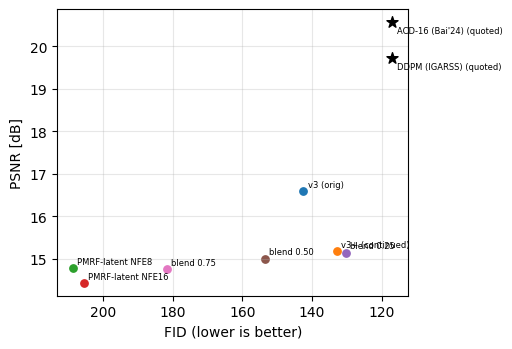

[06:44:10] paired PSNR gain v3+ - v3: -1.407 ± 0.046 dB (n=4096)


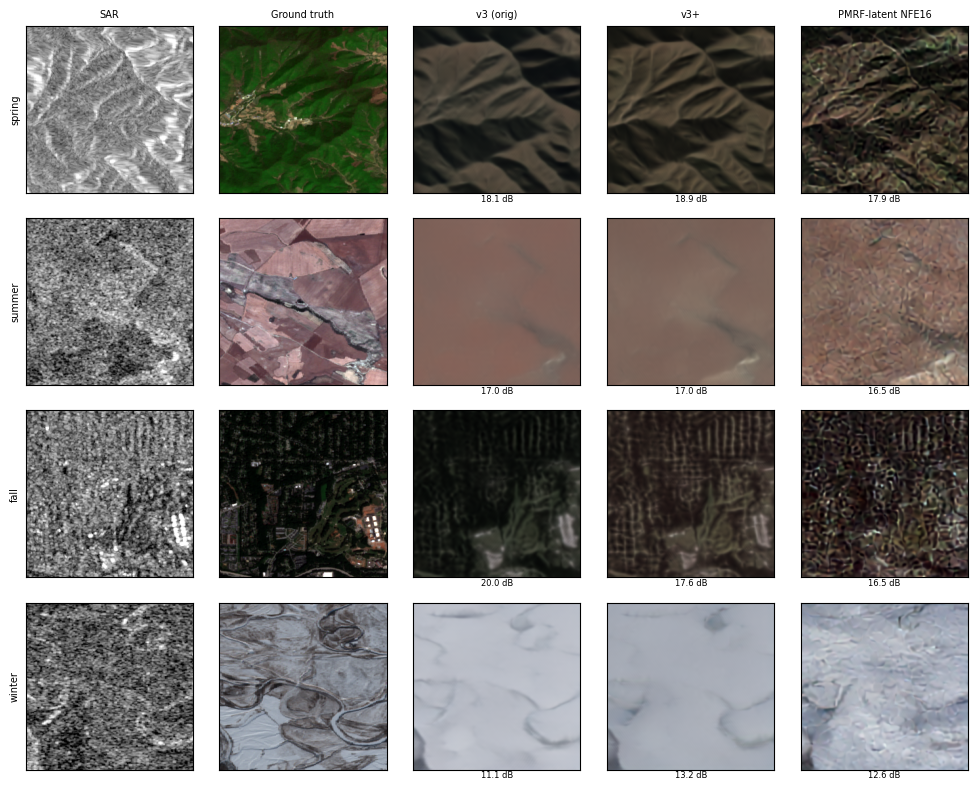

[06:44:34] bundle -> /content/v3x/v3x_results.zip
[06:44:36]   pushed -> HF/v3plus/report


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:


# ============================ PASTE AS CELL 3 ============================
# CELL 3 — setup + Exp 1 (uses the dataset already loaded by the benchmark notebook: /content/pmflow_work/data/{sar,rgb}.u8, split.json)
import os, sys, gc, torch
sys.path.insert(0, "/content/v3x")
if "v3x" in sys.modules: del sys.modules["v3x"]
gc.collect(); torch.cuda.empty_cache()
print(f"GPU memory still held by earlier cells: {torch.cuda.memory_allocated()/1e9:.1f} GB")
if torch.cuda.memory_allocated() > 4e9:
    print("!! >4 GB still allocated by the benchmark notebook. Runtime > Restart session (the disk and data are kept), then run CELL 1-3 again.")
try:
    from google.colab import userdata; HF_TOKEN = userdata.get("HF_TOKEN")      # Colab Secrets (key icon). Never paste tokens into cells.
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN", "")

import v3x
DATA_WORK = globals()["cfg"].work if "cfg" in globals() else "/content/pmflow_work"
v3x.init(HF_TOKEN, DATA_WORK)
tr, va, te = v3x.get_split()
print(f"train {len(tr):,} | val {len(va):,} | test {len(te):,} patches (scene-disjoint)")
base = v3x.exp1_baseline(va, te, n=3000)      # Exp 1: picks the prompt convention and scores v3 on the test scenes

# ============================ PASTE AS CELL 4 ============================
# CELL 4 — Exp 2: continue v3 (resumable: if Colab disconnects, re-run CELL 3 then this cell)
# The 2nd/3rd log lines (step 20, 100) show it/s and peak GPU memory; check them in the first minute.
# The gate at 20,000 steps stops the run unless the paired gain over v3 is >= +0.15 dB.
out2 = v3x.train_regressor(tr, va, steps=120_000, bs=4, accum=2, lr=1e-5, gate_step=20_000, gate_gain=0.15, max_hours=10)
print("Exp 2 ->", out2)

# ============================ PASTE AS CELL 5 ============================
# CELL 5 — Exp 3: posterior-mean rectified flow on top of the regressor (gate at 10,000 steps)
import os
REG_DIR = f"{v3x.WORK}/v3plus_reg/best" if os.path.exists(f"{v3x.WORK}/v3plus_reg/best/unet.safetensors") else None   # None = the original v3
print("regressor used as the posterior mean:", REG_DIR or "original v3")
out3 = v3x.train_flow(tr, va, REG_DIR, steps=40_000, bs=8, lr=2e-5, sigma=0.1, gate_step=10_000)
print("Exp 3 ->", out3)

# ============================ PASTE AS CELL 6 ============================
# CELL 6 — Exp 4: final report on the test scenes (tables, PSNR–FID curve, sample grid, bundle).  n=4096 first (fast); n=None = all 15,394
res = v3x.final_report(te, REG_DIR, f"{v3x.WORK}/pmrf_flow/best", n=4096, nfes=(8, 16), blends=(0.25, 0.5, 0.75))
zip_path = v3x.bundle()
try:
    from google.colab import files; files.download(zip_path)
except Exception: print(zip_path)